# Day 2.5/3 analysis

In [1]:
here::i_am("Manuscript/day_253.ipynb")

source(here::here("settings.R"))
source(here::here("utils.R"))

suppressPackageStartupMessages(library(scran))
suppressPackageStartupMessages(library(scater))
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(dplyr))
suppressPackageStartupMessages(library(ArchR))
suppressPackageStartupMessages(library(edgeR))


BPPARAM <- BiocParallel::bpparam()
BPPARAM$workers = 21

# Multi core using future - built in to seurat
plan("multicore", workers = 16)
options(future.globals.maxSize = 50 * 1024 ^ 3) # for 50 Gb RAM

here() starts at /rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/code


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
        

In [2]:
args = list()
# UMAP
args$MOFA_factors = file.path(io$basedir, 'results/rna_atac/dimensionality_reduction/mofa/MOFA_factors.txt.gz')
args$MOFA_umap = file.path(io$basedir, 'results/rna_atac/dimensionality_reduction/mofa/MOFA_umap.txt.gz')

# RNA_sce
args$rna_sce = file.path(io$basedir, 'processed/rna/SingleCellExperiment.rds')

# Archr
args$archr_directory = file.path(io$basedir, 'processed/atac/archR')

# Mapping Luke
#args$integrated_object = '/rds/project/rds-SDzz0CATGms/users/ltgh2/projects/01_Eomes_invitro_HE_multiome/processed/rna/seurat_objects/all_anchors_20_rPCA.rds'

# outdir
args$outdir = file.path(io$basedir, 'results/manuscript/day_253_v2/')
dir.create(args$outdir, showWarnings = F, recursive = T)

# Metadata
args$metadata = file.path(io$basedir, 'results/rna_atac/combined_metadata.txt.gz')

# Mapping metadata
args$mapping = file.path(io$basedir, 'results/rna/mapping/sample_metadata_after_mapping.txt.gz')

In [3]:
# Load meta
meta = fread(args$metadata)

## Cell Type identification

In [4]:
# load sce
rna.sce <- load_SingleCellExperiment(args$rna_sce, normalise = TRUE, cells = meta$cell)
colData(rna.sce) = meta %>% as.data.frame() %>% tibble::column_to_rownames('cell') %>% DataFrame()

# Convert to Seurat
seurat = as.Seurat(rna.sce)

In [5]:
seurat = seurat[, seurat@meta.data$day != 'D4.5']

In [6]:
set.seed(1234)

In [7]:
options(repr.plot.width=20, repr.plot.height=5)

In [8]:
factors = fread(args$MOFA_factors)[match(meta$cell, cell)] %>%
    .[meta$day != 'D4.5']

In [9]:
umap = uwot::umap(factors[,-1], n_neighbors = 25, min_dist = 0.2)

In [10]:
umap = as.data.table(umap) %>%
    setnames(c('umap1', 'umap2'))

In [11]:
summary(colnames(seurat) == factors$cell)

   Mode    TRUE 
logical   34628 

In [12]:
# Prepare mofa umap
factors.mtx = factors %>% 
    as.data.frame(.) %>% 
    tibble::column_to_rownames('cell') %>%
    as.matrix()
seurat[["mofa"]] <- CreateDimReducObject(embeddings = factors.mtx, key = "mofa_", assay = DefaultAssay(seurat))

In [13]:
umap = uwot::umap(factors[,2:7], n_neighbors = 25, min_dist = 0.2)
umap = as.data.table(umap) %>%
    setnames(c('umap1', 'umap2'))

umap.mtx = umap %>% 
    .[,cell := meta[day != 'D4.5', cell]] %>% 
    as.data.frame(.) %>% 
    tibble::column_to_rownames('cell') %>%
    as.matrix()

seurat[["umap"]] <- CreateDimReducObject(embeddings = umap.mtx, key = "umap_", assay = DefaultAssay(seurat))
seurat <- FindNeighbors(seurat, dims = 1:6, reduction = 'mofa')

seurat <- FindClusters(seurat, resolution = 0.1) # Set to 0.1!?

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 34628
Number of edges: 964292

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9317
Number of communities: 4
Elapsed time: 4 seconds


Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via the L'Ecuyer-CMRG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”


In [14]:
cluster2celltype = c(
    '0' = 'PS 1', 
    '1' = 'PS 2',
    '2' = 'aPS', 
    '3' = 'Epiblast'
)

In [15]:
meta = as.data.table(seurat@meta.data, keep.rownames = T) %>%
    setnames('rn', 'cell') %>%
    .[, celltype_manual := cluster2celltype[match(seurat_clusters, names(cluster2celltype))]] %>%
    merge(., umap[, .(cell, umap1, umap2)], by = 'cell') %>%
    .[,genotype := gsub('_KO', ' KD', genotype)]
meta$cluster = seurat$seurat_clusters

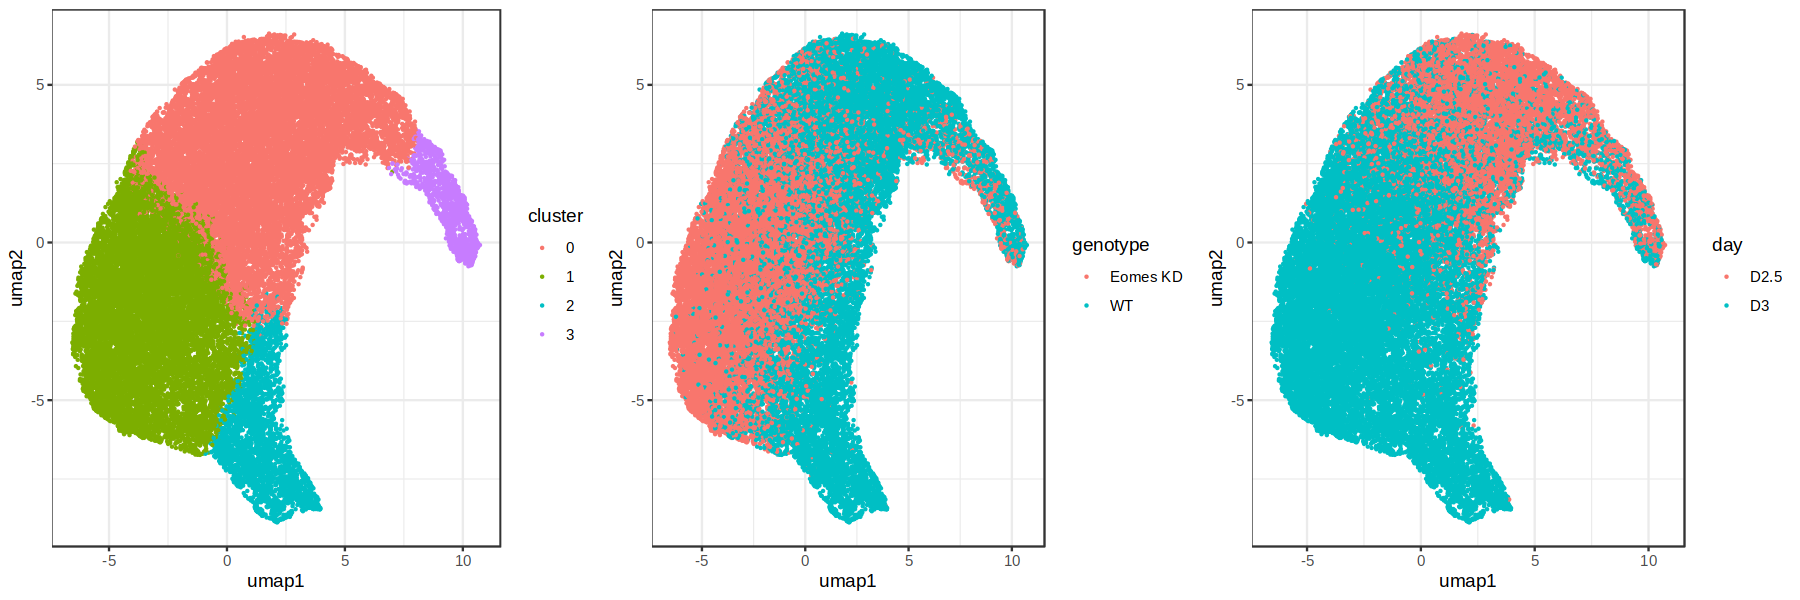

In [16]:
options(repr.plot.width=15, repr.plot.height=5)
p1 = ggplot(meta[sample(nrow(meta))], aes(umap1, umap2, color = cluster)) + geom_point(size = 0.2) + theme_bw()
p2 = ggplot(meta[sample(nrow(meta))], aes(umap1, umap2, color = genotype)) + geom_point(size = 0.2) + theme_bw()
p3 = ggplot(meta[sample(nrow(meta))], aes(umap1, umap2, color = day)) + geom_point(size = 0.2) + theme_bw()
ggarrange(p1, p2, p3, nrow = 1)

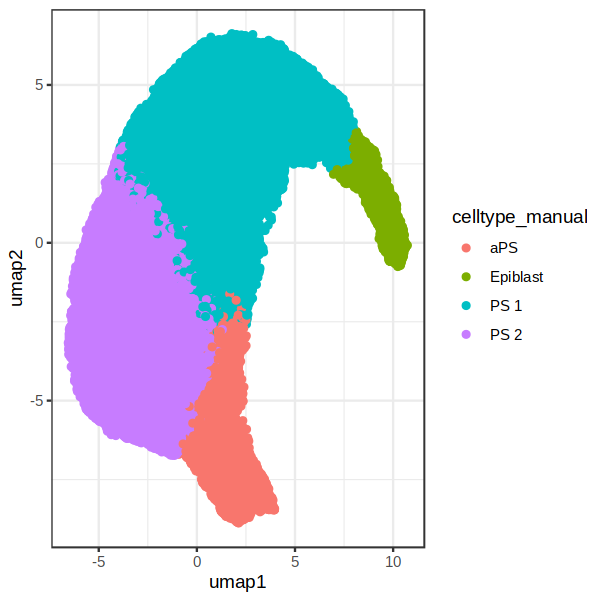

In [17]:
options(repr.plot.width=5, repr.plot.height=5)
ggplot(meta, aes(umap1, umap2, color = celltype_manual)) + geom_point() + theme_bw()

In [18]:
fwrite(meta, file.path(args$outdir, 'd253_celltypes.txt.gz'))
fwrite(umap, file.path(args$outdir, 'd253_umap.txt.gz'))


In [19]:
meta = fread(file.path(args$outdir, 'd253_celltypes.txt.gz'))
umap = fread(file.path(args$outdir, 'd253_umap.txt.gz'))

In [20]:
p_legend = ggplot(meta, aes(umap1, umap2, color = celltype_manual)) + 
    ggrastr::rasterize(geom_point(size = -0.2), dpi = 600) + 
    guides(color = guide_legend(override.aes = list(size = 2.5))) + # Set legend dot size 
    theme_void() + 
    theme(legend.key.size = unit(1.2, "mm"))

p1 = ggplot(copy(meta)[day == 'D2.5'], aes(umap1, umap2, color = celltype_manual)) + 
    ggrastr::rasterize(geom_point(data = meta[genotype != 'D2.5'], color = 'grey90', size = -0.2), dpi = 600) + 
    ggrastr::rasterize(geom_point(size = -0.2), dpi = 600) + 
    ggtitle('WT') + 
    guides(color = guide_legend(override.aes = list(size = 2.5))) + # Set legend dot size 
    theme_void()  + theme(legend.position = 'none',
                         plot.title = element_text(hjust = 0.5)
                          )

p2 = ggplot(copy(meta)[genotype == 'WT' & day == 'D3'], aes(umap1, umap2, color = celltype_manual)) + 
    ggrastr::rasterize(geom_point(data = meta[genotype == 'Eomes KD' | (genotype == 'WT' & day != 'D3')], color = 'grey90', size = -0.2), dpi = 600) + 
    ggrastr::rasterize(geom_point(size = -0.2), dpi = 600) + 
    ggtitle('WT') + 
    guides(color = guide_legend(override.aes = list(size = 2.5))) + # Set legend dot size 
    theme_void()  + theme(legend.position = 'none',
                         plot.title = element_text(hjust = 0.5)
                          )

p3 = ggplot(copy(meta)[genotype == 'Eomes KD' & day == 'D3'], aes(umap1, umap2, color = celltype_manual)) + 
    ggrastr::rasterize(geom_point(data = meta[genotype == 'WT'], color = 'grey90', size = -0.2), dpi = 600) + 
    ggrastr::rasterize(geom_point(size = -0.2), dpi = 600) + 
    ggtitle('EOMES KD') + 
    guides(color = guide_legend(override.aes = list(size = 2.5))) + # Set legend dot size 
    theme_void() + theme(legend.position = 'none',
                         plot.title = element_text(hjust = 0.5)
                        )

meta_props = meta %>% copy() %>%
    .[day == 'D3', ] %>%
    .[, tot := .N, by = 'genotype'] %>%
    .[, prop := .N/tot, by = c('celltype_manual', 'genotype')] %>%
    unique(by = c('celltype_manual', 'genotype')) %>%
    .[, genotype := factor(genotype, levels = c('WT', 'Eomes KD'))]

p4 = ggplot(meta_props, aes(celltype_manual, prop * 100, fill = genotype)) +
    geom_bar(position = 'dodge', stat = 'identity') + 
    scale_fill_manual(values = c('Eomes KD' = 'red', 'WT' = 'black')) +
    scale_y_continuous(expand = c(0,0,0.05,0)) + 
    scale_x_discrete(limits = c(
                                'Epiblast',
                                'PS 1', 
                                'PS 2', 
                                'aPS'
                                )) + 
    ylab('% of genotype') + 
    theme_bw() + 
    theme(axis.text = element_text(color = 'black'),
          axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
          axis.title.x = element_blank())

                      
# p4

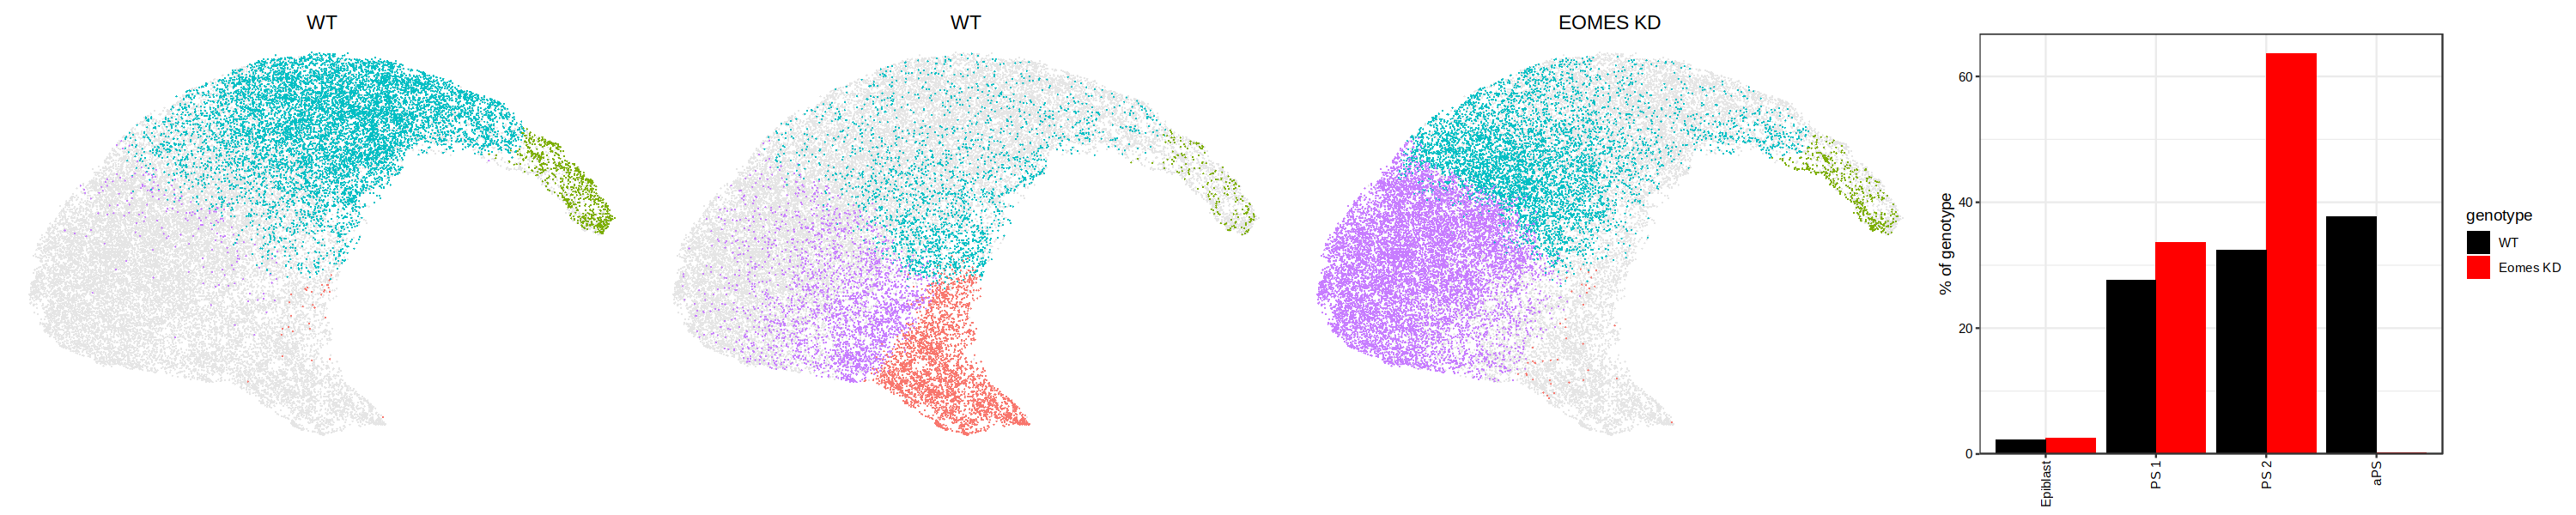

In [21]:
options(repr.plot.width = 25)
ggarrange(p1, p2, p3, p4, ncol = 4, align = 'h')


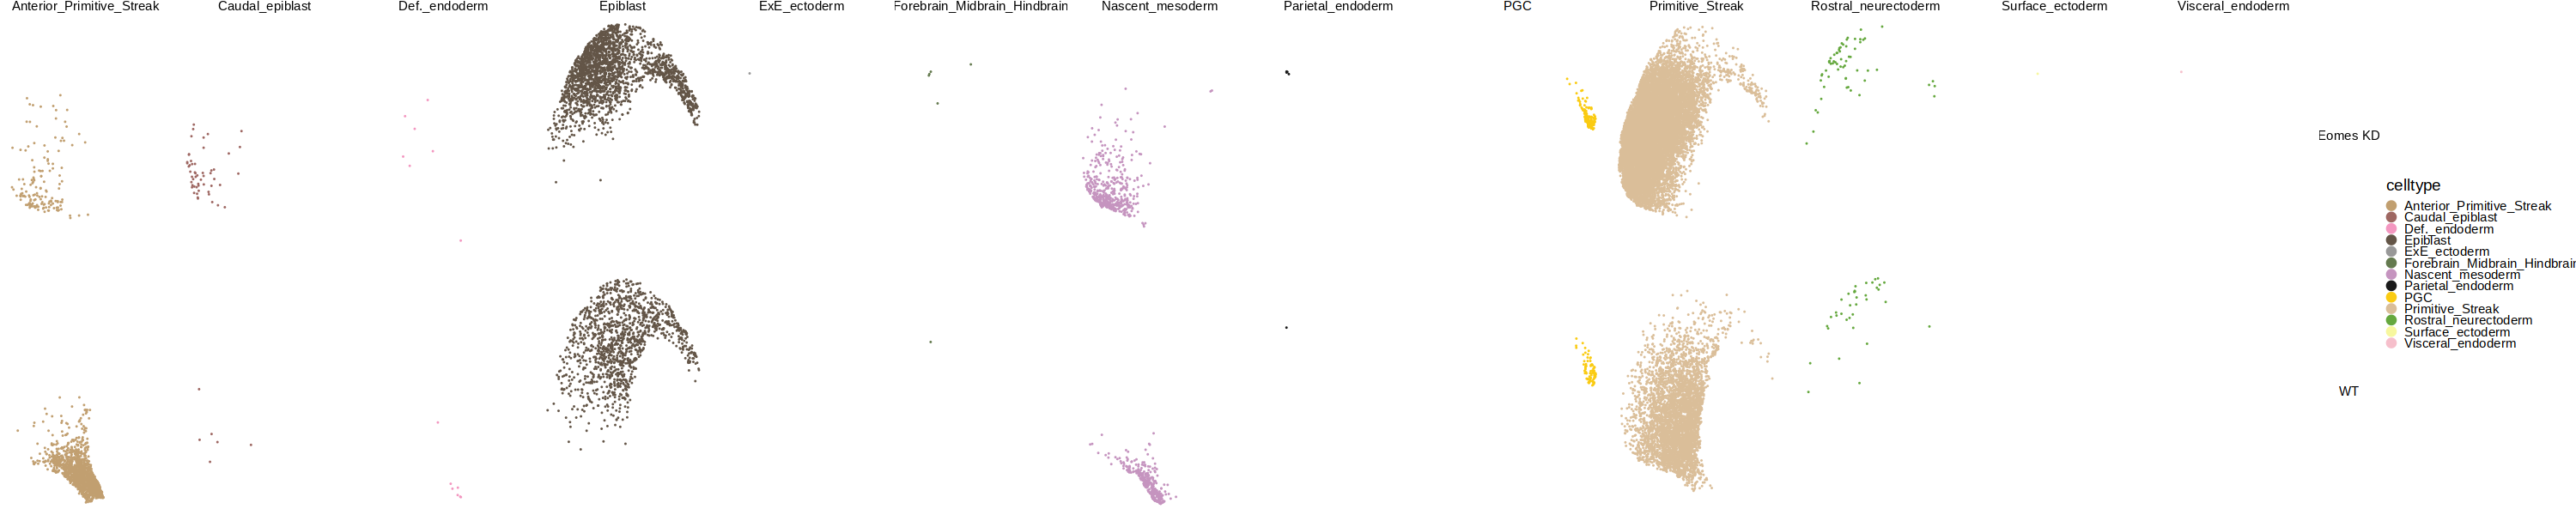

In [22]:
options(repr.plot.width = 25, repr.plot.height = 5)
ggplot(meta[day == 'D3'], aes(umap1, umap2, color = celltype)) + 
    geom_point(size = -0.2) + 
    guides(color = guide_legend(override.aes = list(size = 2.5))) + # Set legend dot size 
    scale_color_manual(values = opts$celltype.colors) + 
    facet_grid(cols = vars(celltype), rows = vars(genotype)) + 
    theme_void() + 
    theme(legend.key.size = unit(1.2, "mm"))

In [23]:
ggsave(file.path(args$outdir, 'UMAPs_proportions.pdf'), 
       plot = ggarrange(cowplot::ggdraw(get_legend(p_legend)), p1, p2, p3, p4, ncol = 5, widths = c(0.4, 0.8, 0.8, 0.8, 1)),
       width = 300, 
       height = 60, 
       units = "mm")

In [24]:
Idents(seurat) =  seurat$seurat_clusters

In [25]:
all.genes <- rownames(seurat)
seurat = ScaleData(seurat, features = all.genes)

Centering and scaling data matrix



In [26]:
# find markers for every cluster compared to all remaining cells, report only the positive
# ones
markers <- FindAllMarkers(seurat, only.pos = TRUE)
markers %>%
    group_by(cluster) %>%
    # dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 30) %>%
    ungroup() -> top30


Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3



In [27]:
markers %>%
    group_by(cluster) %>%
    # dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 30) %>%
    ungroup() -> top30

In [28]:
seurat@meta.data = meta %>% as.data.frame() %>% tibble::column_to_rownames('cell') %>% as.data.frame()

In [29]:
seurat@meta.data$genotype = gsub('_KO', ' KD', seurat@meta.data$genotype)

In [30]:
seurat$celltype_genotype = paste0(seurat$celltype_manual, ' (', gsub('Eomes ', '', seurat$genotype), ')')
seurat$celltype_genotype = factor(seurat$celltype_genotype, 
                                  levels = c(
                                      'Epiblast (WT)',
                                      'Epiblast (KD)',
                                      'PS 1 (WT)', 
                                      'PS 1 (KD)', 
                                      'PS 2 (WT)', 
                                      'PS 2 (KD)', 
                                      'aPS (WT)',
                                      'aPS (KD)'
                                    )
                                  )

In [31]:
seurat_filt = seurat[, ! seurat@meta.data$celltype_genotype %in% 
                     c(
                      'aPS (KD)'
                     )
                    ]

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


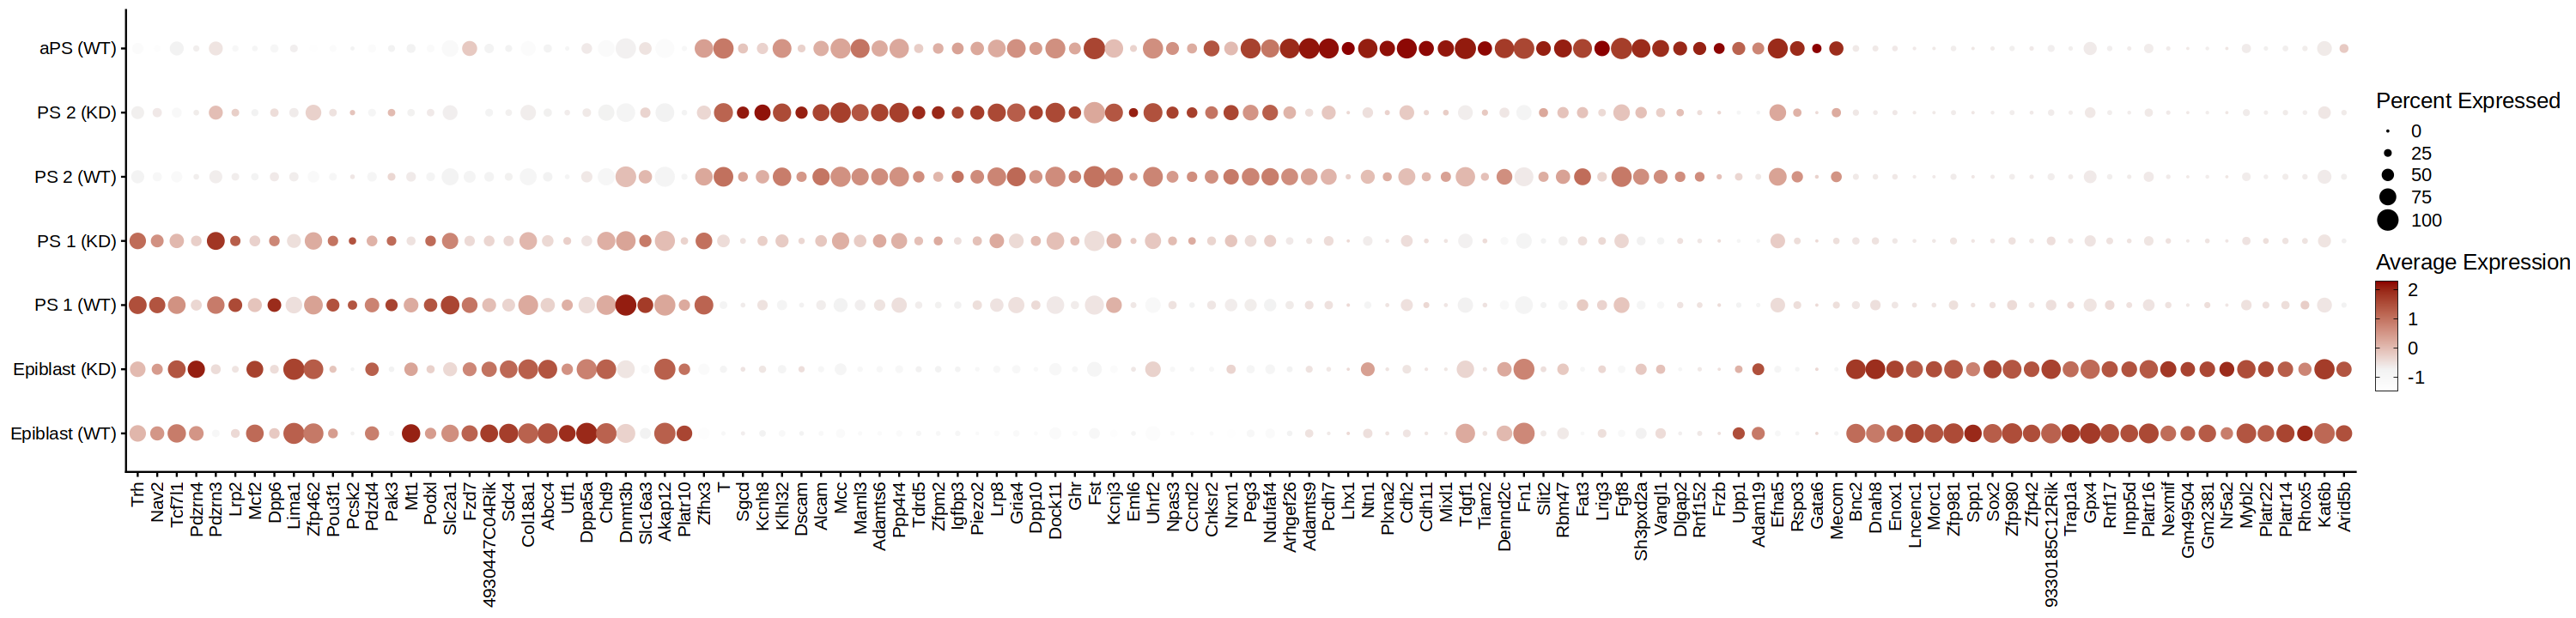

In [32]:
options(repr.plot.width=25, repr.plot.height=6)
p = DotPlot(seurat_filt, features = unique(top30$gene), group.by = 'celltype_genotype') + 
    # scale_color_gradient(low='white', high='darkred', name='Average Expression') + 
    scale_color_gradientn(colours = c('white', 'grey95','darkred'), values = c(0, 0.2,1), name='Average Expression') + 
    guides(color = guide_colourbar(
         # barwidth = 0.5, barheight = 2.5,
        frame.colour = "black", 
        ticks.colour = "black"
    )) + 
    RotatedAxis() +
    ylab('celltype genotype') + xlab('') +
    theme(text=element_text(size=15), 
                         axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
                         axis.text.y=element_text(hjust=1),
         axis.title = element_blank())

p

Warning message in FetchData.Seurat(object = object, vars = features, cells = cells):
“The following requested variables were not found: Essrb”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


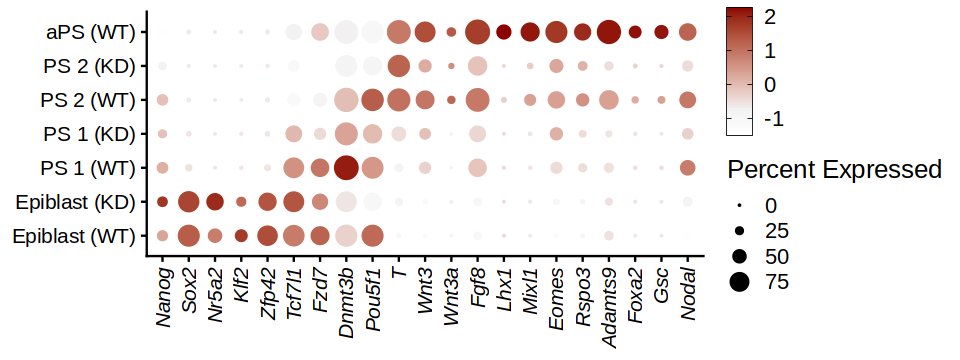

In [33]:
features = c(
    'Nanog', 'Sox2', 'Essrb', 'Nr5a2', 'Klf2', 'Zfp42', 'Tcf7l1', 'Fzd7', 'Dnmt3b','Pou5f1', # Epiblast
    'T', 'Wnt3', 'Wnt3a', 'Fgf8',  # General PS
    'Lhx1', 'Mixl1', 'Eomes', 'Rspo3', 'Adamts9', 'Foxa2', 'Gsc', 'Nodal' # Anterior PS
)

options(repr.plot.width=8, repr.plot.height=3)
p = DotPlot(seurat_filt, features = features, group.by = 'celltype_genotype') + 
    # scale_color_gradient(low='white', high='darkred', name='Average Expression') + 
    scale_color_gradientn(colours = c('white', 'grey95','darkred'), values = c(0, 0.2,1), name='Average Expression') + 
    guides(color = guide_colourbar(
         # barwidth = 0.5, barheight = 2.5,
        frame.colour = "black", 
        ticks.colour = "black"
    )) + 
    RotatedAxis() +
    ylab('celltype genotype') + xlab('') +
    theme(text=element_text(size=15), 
                         axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5, face = 'italic'),
                         axis.text.y=element_text(hjust=1),
         axis.title = element_blank())

p

In [34]:
ggsave(file.path(args$outdir, 'd253_expression.pdf'), 
       plot = p,
       width = 180, 
       height = 70, 
       units = "mm")

# Differential testing - RNA

In [35]:
### Differential testing functinos
volcano_plot = function(dt, ntop=5, logFC_thr = logFC_thr, FDR_thr = FDR_thr, xlim=2.5, ylim=3, title=NULL){
    tmp = dt[,sign:=ifelse(padj_fdr < FDR_thr & abs(logFC) > logFC_thr, ifelse(logFC>0, 'pos', 'neg'), 'nonsig')] %>%
        .[order(-abs(logFC))] %>% 
        .[,logFC_plot:=ifelse(logFC<=-xlim, -xlim, ifelse(logFC>=xlim, xlim, logFC))] %>%
        .[,log10_padj_fdr:=ifelse(-log10(padj_fdr)>=ylim, ylim, -log10(padj_fdr))]
    
    labels = tmp[, head(.SD, ntop),  by=sign][sign!='nonsig']
    
    negative_hits <- tmp[sign == 'neg',gene]
    positive_hits <- tmp[sign == 'pos',gene]
    all <- nrow(tmp[!is.na(sign)])
    
    p = ggplot(tmp, aes(logFC_plot, log10_padj_fdr, col=sign, size = sign)) + 
        geom_point() + 
        scale_colour_manual(values=c('pos' = 'red', 'neg' = 'blue', 'nonsig' = 'black')) + 
        scale_size_manual(values=c('pos' = 1, 'neg' = 1, 'nonsig' = 0.2)) + 
        geom_vline(xintercept=c(-logFC_thr, logFC_thr),  linetype = "longdash") +
        geom_segment(aes(x=0, xend=0, y=0, yend=ylim*1.05), color="orange", linewidth=0.5) +
        geom_hline(yintercept=-log10(FDR_thr),  linetype = "longdash") + 
        ggrepel::geom_text_repel(data=labels, aes(label=gene), 
                                 color='black',
                                 size=5,
                                 box.padding = 0.5, 
                                 max.overlaps = Inf,
                                 bg.color='white', 
                                 bg.r = 0.1) + 
        scale_x_continuous(limits=c(-xlim*1.05,xlim*1.05), expand = c(0,0)) +
        scale_y_continuous(limits=c(0,ylim*1.2), expand = c(0,0)) +
        annotate("text", x=0, y=ylim*1.1, size=6, label=sprintf("(%d)", all)) +
        annotate("text", x=-xlim*0.9, y=ylim*1.15, size=6, label=sprintf("%d (-)",length(negative_hits))) +
        annotate("text", x=xlim*0.9, y=ylim*1.15, size=6, label=sprintf("%d (+)",length(positive_hits))) +
        #xlim(c(-max(abs(tmp$logFC)), max(abs(tmp$logFC)))) + 
        ggtitle(title) + 
        theme_bw() + 
        theme(text = element_text(size=15, color='black'),
             axis.text = element_text(size=15, color='black'),
             legend.position = 'none',
              plot.title = element_text(hjust=0.5))
    
    return(p)
}

run_edger = function(fr_cells = fr_cells, bg_cells = bg_cells, logFC_thr = logFC_thr, title = ''){
    sce = rna.sce[, c(bg_cells, fr_cells)]
    sce$group = ifelse(colnames(sce) %in% fr_cells, 'fr', 'bg') 
    sce$group_by = paste0(sce$group, '_', sce$sample)   
    
    sce = aggregateAcrossCells(sce, id=sce$group_by, BPPARAM = BPPARAM)
    
    # Convert SCE to DGEList
    sce_edger <- scran::convertTo(sce, type="edgeR")

    keep.genes <- filterByExpr(sce_edger, group=sce_edger$samples$group, min.count = 25, min.total.count = 100)
    sce_edger = sce_edger[keep.genes, ]

    # Calculate Normalisation Factors
    sce_edger <- calcNormFactors(sce_edger)

    # Define design matrix (with intercept)
    design <- model.matrix(~sce$group)

    # Estimate dispersions
    sce_edger  <- estimateDisp(sce_edger,design)

    # Fit GLM
    fit <- glmQLFit(sce_edger,design)

    # # Likelihood ratio test
    # lrt <- glmQLFTest(fit)

    # Testing above logFC threshold
    lrt = glmTreat(fit, lfc=logFC_thr)

    # Construct output data.frame
    out <- topTags(lrt, n=nrow(lrt))$table %>% as.data.table(keep.rownames=T) %>%
    setnames(c("gene","logFC","logCPM","LR","p.value","padj_fdr"))
    
    plot = volcano_plot(out,ylim = 5, FDR_thr = 0.05, logFC_thr = logFC_thr, ntop = 10, title = title)
    
    tmp = list(out, plot)
    names(tmp) = c('DEGs', 'plot')
    return(tmp)
}



find_DEGs = function(celltype_test, logFC_thr = args$logFC_thr, sample_cells = NULL, plot = T){
    title = celltype_test
    message(celltype_test)
    tmp = seurat[, meta[celltype_manual %in% celltype_test]$cell]

    KO_tmp = tmp[,tmp$genotype == 'Eomes KD']
    WT_tmp = tmp[,tmp$genotype == 'WT']
    
    if(!is.null(sample_cells)){
        KO_tmp = KO_tmp[,sample(colnames(KO_tmp), sample_cells)]
        WT_tmp = WT_tmp[,sample(colnames(WT_tmp), sample_cells)]
    }
    
    fr_cells = colnames(KO_tmp)
    bg_cells = colnames(WT_tmp)
    
    tmp = run_edger(fr_cells = fr_cells, bg_cells = bg_cells, logFC_thr = logFC_thr, title = title)
    if(plot){
        return(tmp$plot)
    }
    else{return(tmp$DEGs)}
}  

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


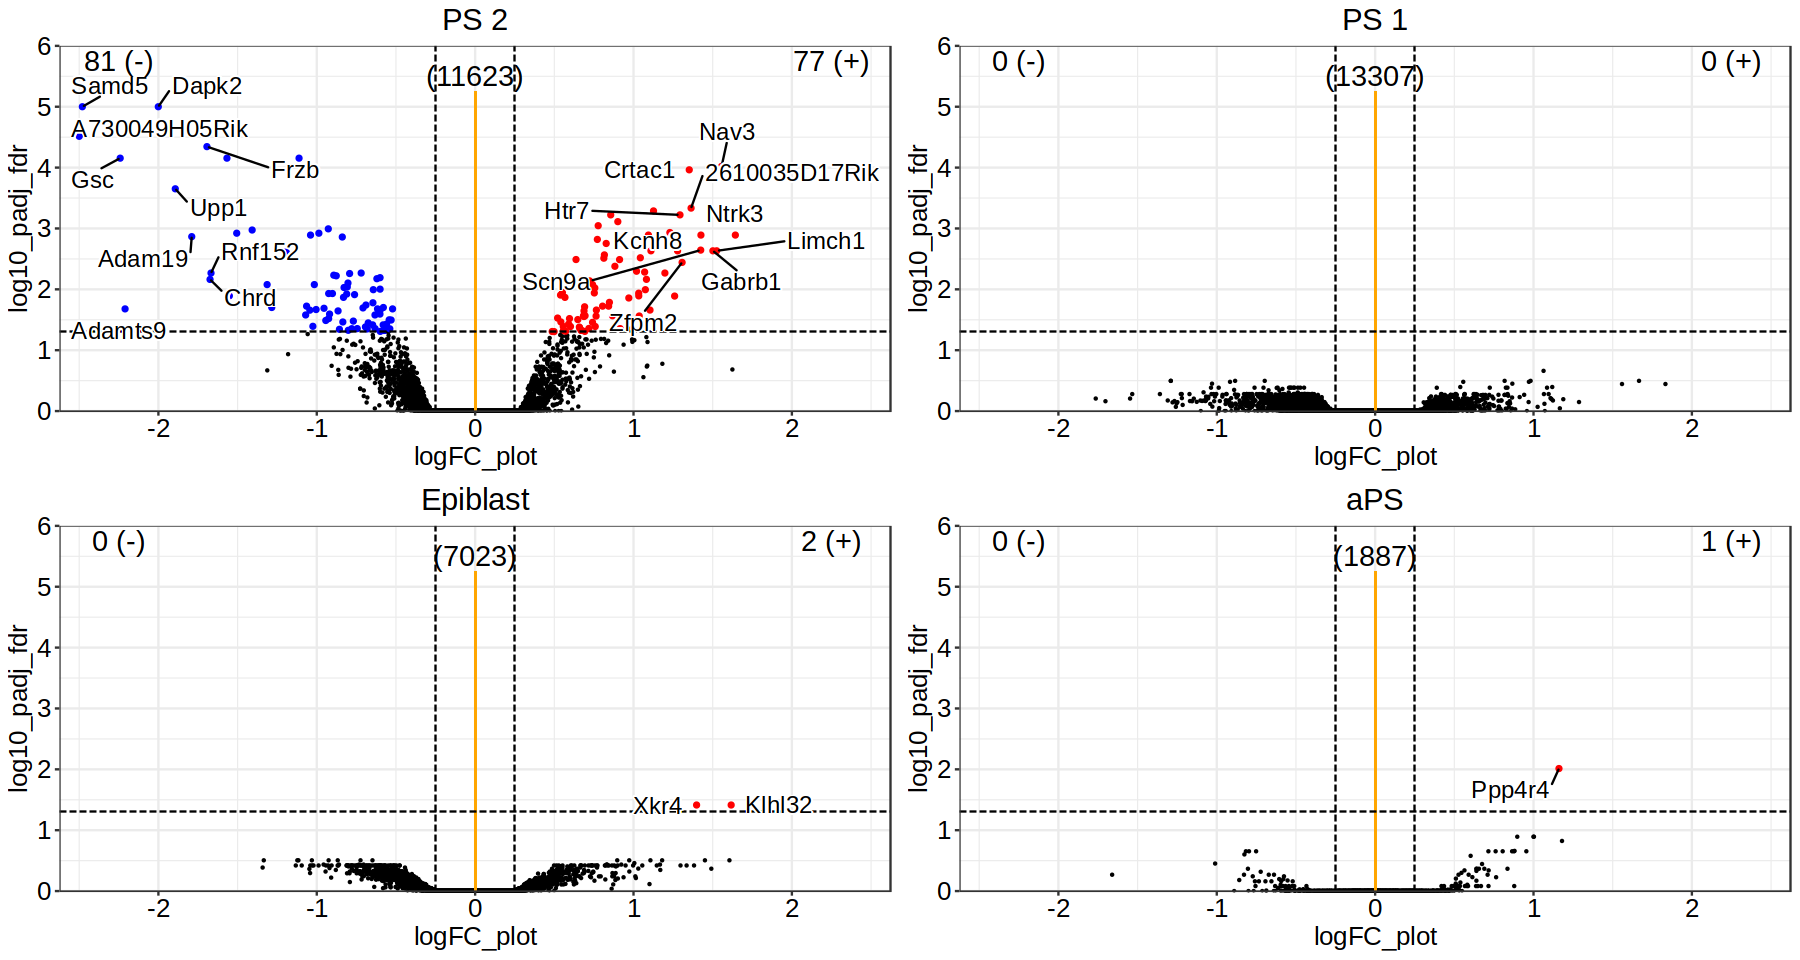

In [36]:
plots = mclapply(unique(meta[day == 'D3', celltype_manual]), function(x){
    tmp = find_DEGs(celltype_test = x, logFC = 0.25)
    return(tmp)
}, mc.cores = 8)
options(repr.plot.width=15, repr.plot.height=8)
ggarrange(plotlist=plots)

In [37]:
WT_WT = run_edger(fr_cells = meta[day == 'D3' & celltype_manual == 'aPS' & genotype == 'WT', cell], 
          bg_cells = meta[day == 'D3' & celltype_manual == 'PS 2' & genotype == 'WT', cell], 
          logFC_thr = 0.25)

In [38]:
WT_KD = run_edger(fr_cells = meta[day == 'D3' & celltype_manual == 'PS 2' & genotype == 'Eomes KD', cell], 
          bg_cells = meta[day == 'D3' & celltype_manual == 'PS 2' & genotype == 'WT', cell], 
          logFC_thr = 0.25)

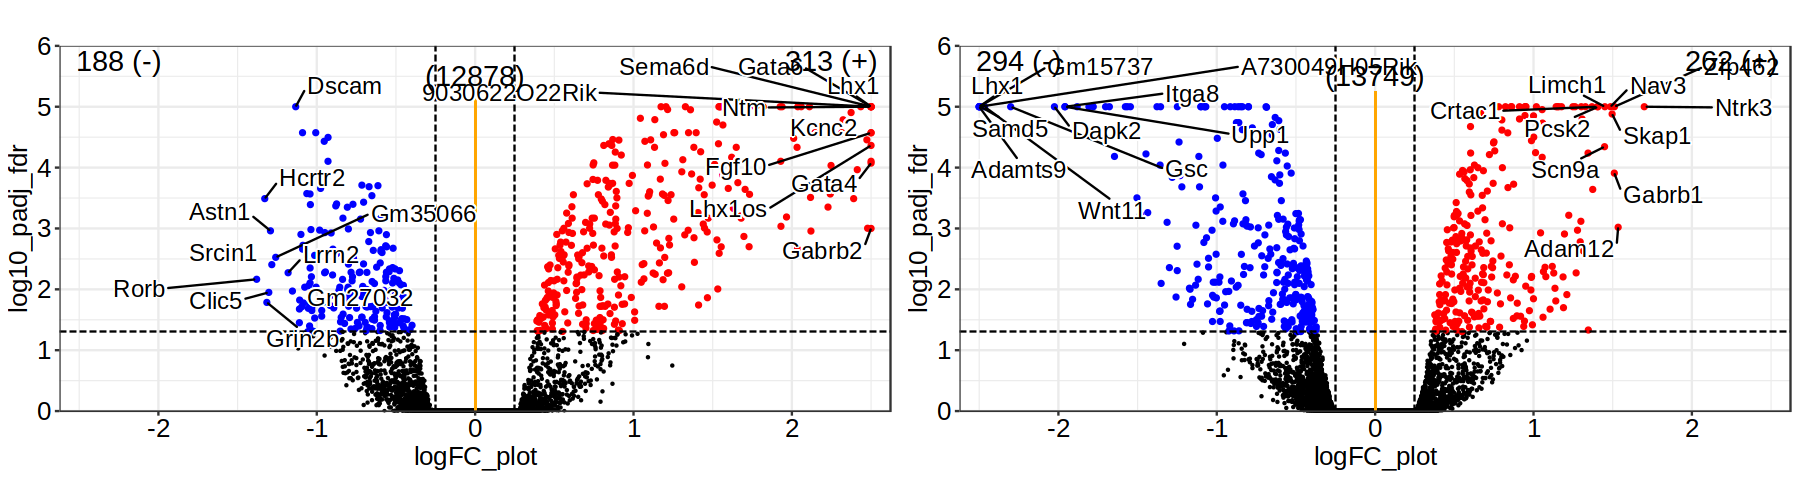

In [39]:
options(repr.plot.width=15, repr.plot.height=4)
ggarrange(WT_WT$plot, WT_KD$plot)

In [40]:
fwrite(rbind(WT_WT$DEGs[, test := 'WT_WT'], 
             WT_KD$DEGs[, test := 'WT_KD']), 
       file.path(args$outdir, 'transcriptomic_comparisons.txt.gz'), sep = '\t')

In [41]:
tmp = fread(file.path(args$outdir, 'transcriptomic_comparisons.txt.gz'))

In [42]:
tmp[gene %in% c('Sox17', 'Noto', 'Shh', 'Foxj1', 'Cxcr4', 'Snai1')]

gene,logFC,logCPM,LR,p.value,padj_fdr,sign,test
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
Snai1,0.664545,0.6654738,2.321241,0.0052514157,0.10616598,nonsig,WT_WT
Snai1,-1.165760,-1.1676865,1.222434,0.0005474175,0.01766771,neg,WT_KD


In [43]:
head(WT_WT$DEGs)

gene,logFC,logCPM,LR,p.value,padj_fdr,sign,test
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
Tiam2,1.937985,1.938170,6.519733,2.581591e-10,1.564362e-06,pos,WT_WT
Flt1,1.539082,1.539273,5.993051,3.607935e-10,1.564362e-06,pos,WT_WT
9030622O22Rik,3.133780,3.136263,4.118549,3.644267e-10,1.564362e-06,pos,WT_WT
Gata6,4.048097,4.050372,5.145635,6.100487e-10,1.945967e-06,pos,WT_WT
Sema6d,2.870482,2.872620,4.059525,7.555394e-10,1.945967e-06,pos,WT_WT
Pcdh7,1.545583,1.545597,9.689488,1.034903e-09,1.993520e-06,pos,WT_WT


In [44]:
comparison = merge(WT_WT$DEGs[,.(gene, logFC, sign)] %>% setnames(c('logFC', 'sign'), c('WT_WT_logFC', 'WT_WT_sign')),
                   WT_KD$DEGs[,.(gene, logFC, sign)] %>% setnames(c('logFC', 'sign'), c('WT_KD_logFC', 'WT_KD_sign')),
                   by = 'gene') %>%
        .[, sign := ifelse(WT_WT_sign == 'nonsig' & WT_KD_sign == 'nonsig', 'nonsig',
                           ifelse(WT_WT_sign != 'nonsig' & WT_KD_sign == 'nonsig', 'WT_WT',
                                  ifelse(WT_WT_sign == 'nonsig' & WT_KD_sign != 'nonsig', 'WT_KD',
                                         ifelse(WT_WT_sign != 'nonsig' & WT_KD_sign != 'nonsig', 'both', NA))))] %>%
        .[, sign := factor(sign, levels = c('nonsig', 'WT_WT', 'WT_KD', 'both'))] %>%
        .[order(sign)] %>%
        .[, meanlogFC := (WT_WT_logFC - WT_KD_logFC)/2]

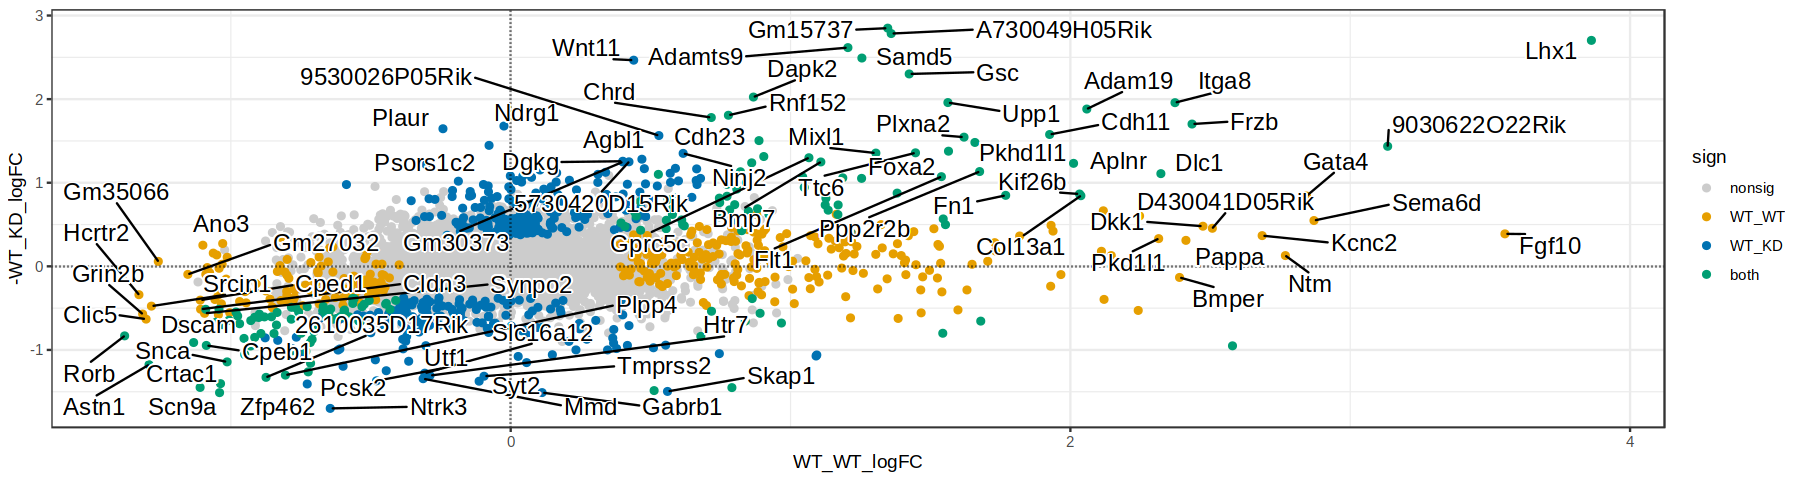

In [45]:
n = 10
label = rbind(
    head(comparison[sign == 'both'][order(meanlogFC)], n),
    head(comparison[sign == 'both'][order(-meanlogFC)], n*3),
        head(comparison[sign == 'WT_WT'][order(WT_WT_logFC)], n),
    head(comparison[sign == 'WT_WT'][order(-WT_WT_logFC)], n),
        head(comparison[sign == 'WT_KD'][order(WT_KD_logFC)], n),
    head(comparison[sign == 'WT_KD'][order(-WT_KD_logFC)], n)
) %>% unique(by = 'gene')

ggplot(comparison, aes(WT_WT_logFC, -WT_KD_logFC, color = sign)) + 
    geom_point() +
    geom_hline(yintercept = 0, linetype = 'dotted') + 
    geom_vline(xintercept = 0, linetype = 'dotted') + 
    ggrepel::geom_text_repel(data = label,
                                 aes(label = gene),
                                 color = 'black',
                                 max.overlaps = Inf,
                                size=5,
                                box.padding = 0.5, 
                                bg.color='white', 
                                bg.r = 0.1) + 
    scale_color_manual(values = c(
                    'both' = '#009E73',      # green (colorblind-friendly)
                    'nonsig' = 'grey80',
                    'WT_WT' = '#E69F00',     # orange (colorblind-friendly)
                    'WT_KD' = '#0072B2'      # blue (colorblind-friendly)
                    )) + 
    theme_bw()

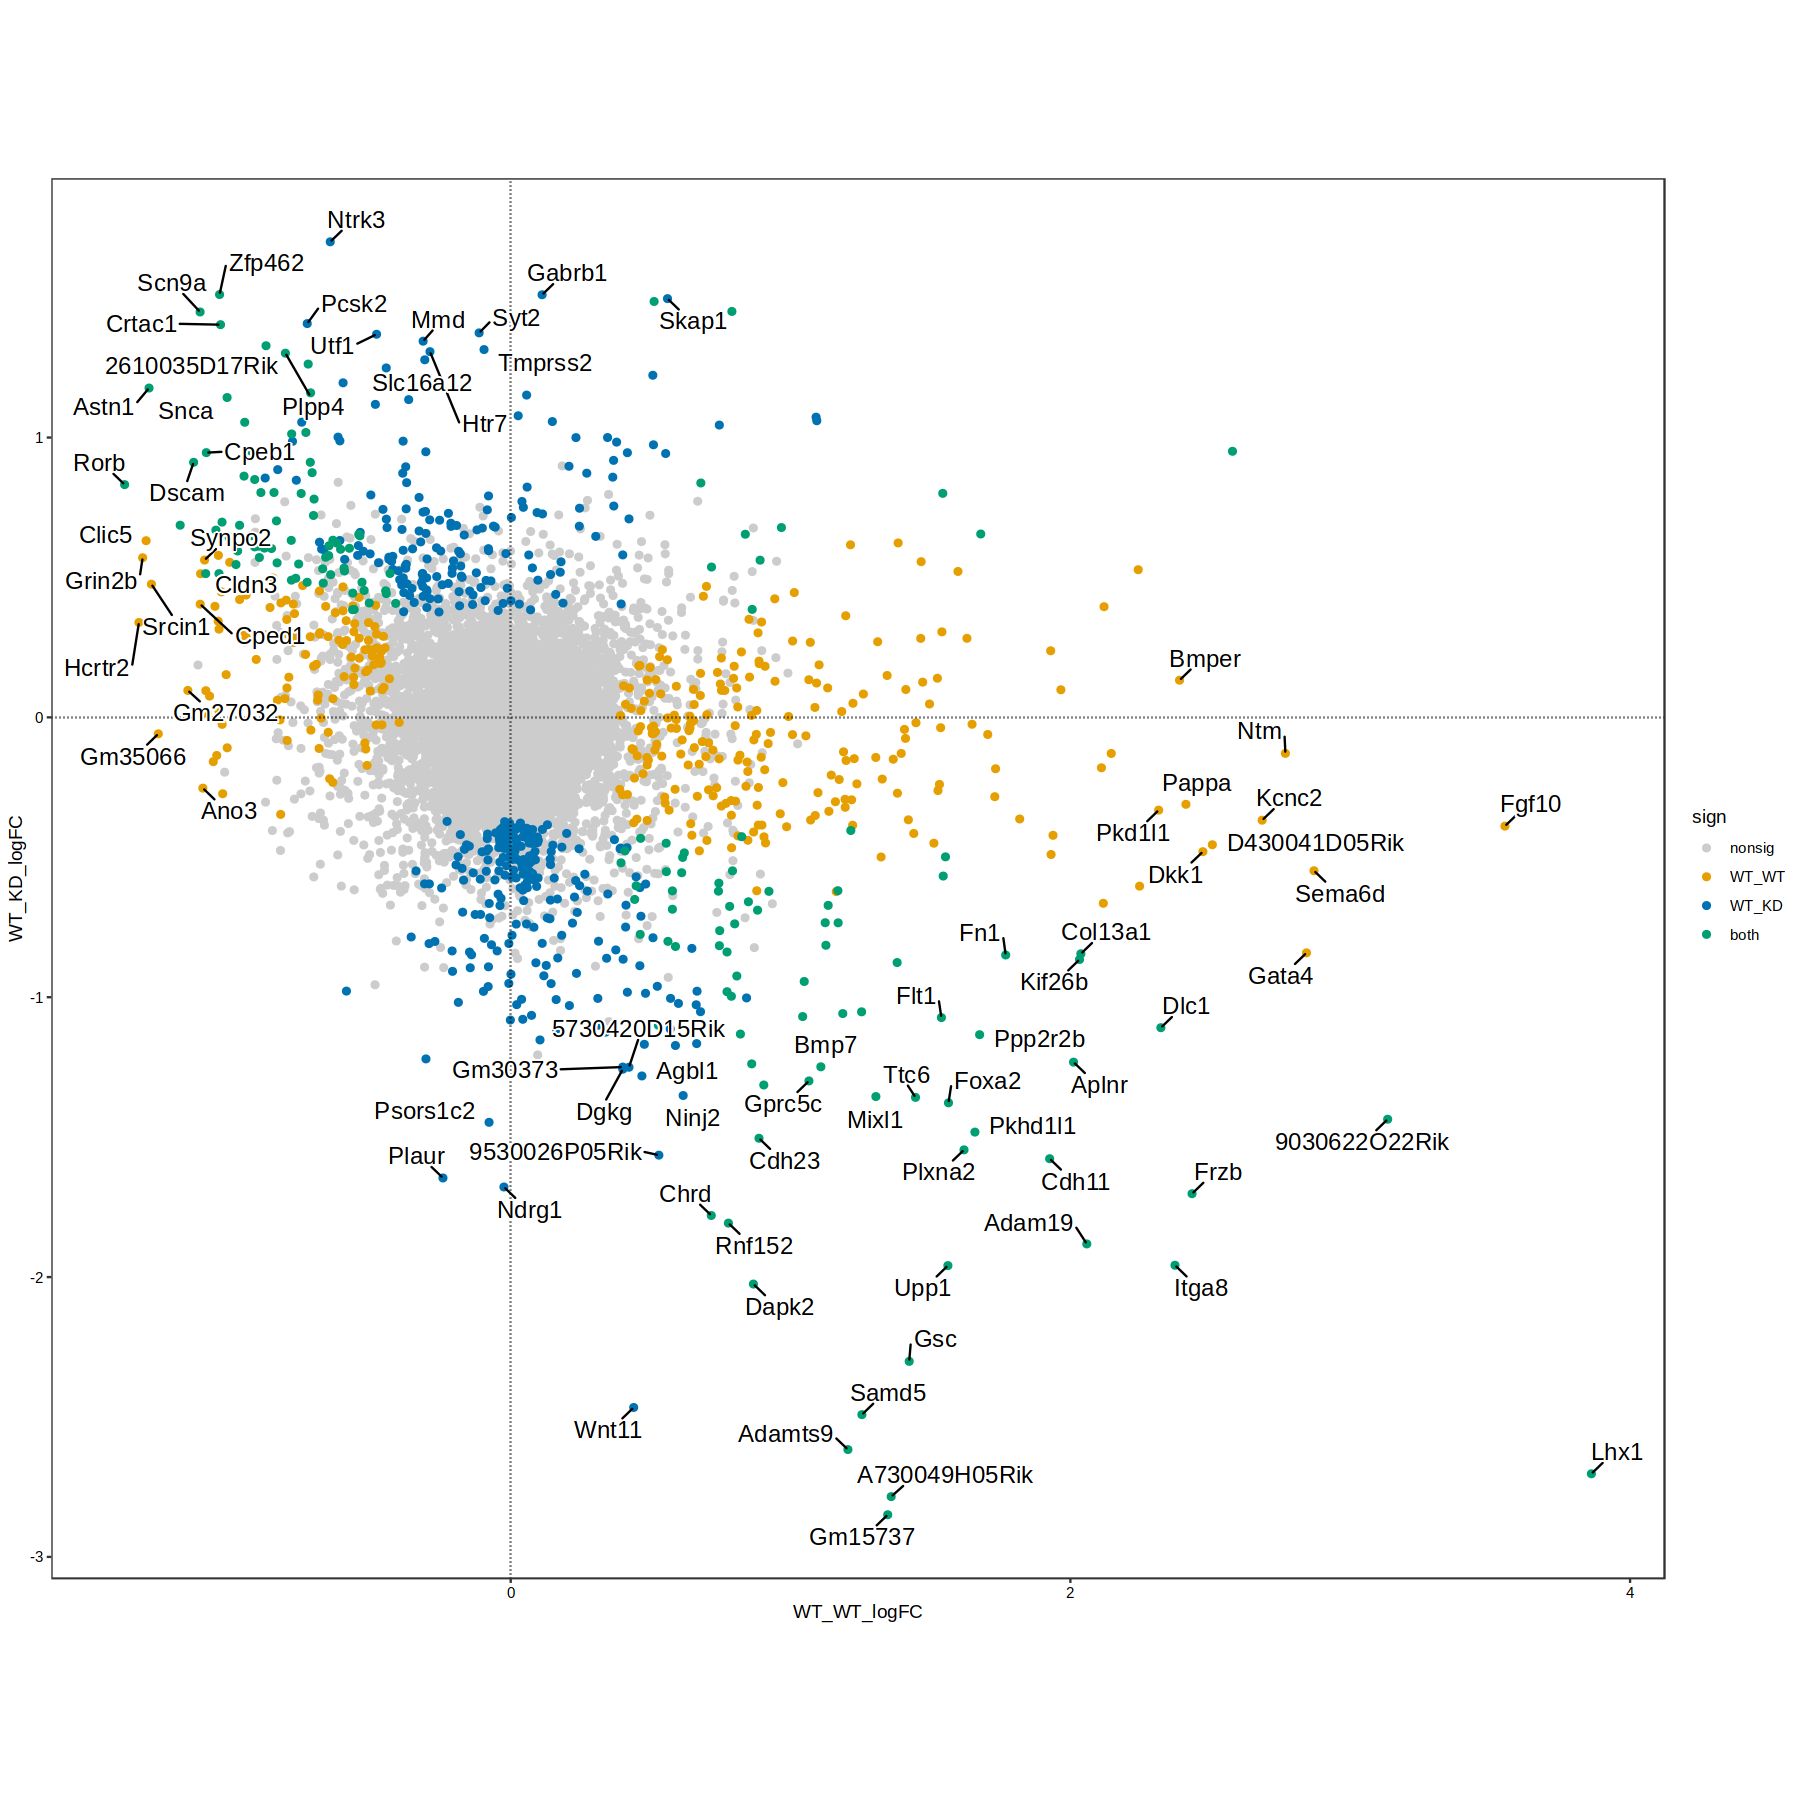

In [46]:
n = 10
label = rbind(
    head(comparison[sign == 'both'][order(meanlogFC)], n),
    head(comparison[sign == 'both'][order(-meanlogFC)], n*3),
        head(comparison[sign == 'WT_WT'][order(WT_WT_logFC)], n),
    head(comparison[sign == 'WT_WT'][order(-WT_WT_logFC)], n),
        head(comparison[sign == 'WT_KD'][order(WT_KD_logFC)], n),
    head(comparison[sign == 'WT_KD'][order(-WT_KD_logFC)], n)
) %>% unique(by = 'gene')

options(repr.plot.width=15, repr.plot.height=15)
p = ggplot(comparison, aes(WT_WT_logFC,WT_KD_logFC,  color = sign)) + 
    geom_point() +
    geom_hline(yintercept = 0, linetype = 'dotted') + 
    geom_vline(xintercept = 0, linetype = 'dotted') + 
    ggrepel::geom_text_repel(data = label,
                                 aes(label = gene),
                                 color = 'black',
                                 max.overlaps = Inf,
                                size=5,
                                box.padding = 0.5, 
                                bg.color='white', 
                                bg.r = 0.1) + 
    scale_color_manual(values = c(
                    'both' = '#009E73',      # green (colorblind-friendly)
                    'nonsig' = 'grey80',
                    'WT_WT' = '#E69F00',     # orange (colorblind-friendly)
                    'WT_KD' = '#0072B2'      # blue (colorblind-friendly)
                    )) + 
    coord_fixed() + 
    theme_bw() + 
    theme(
        axis.text = element_text(color = 'black'),
        panel.grid = element_blank()
    )
p

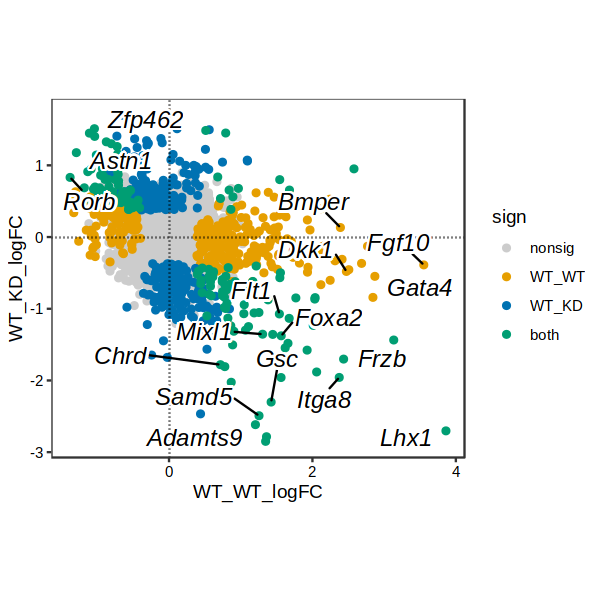

In [47]:
n = 10
label = c('Mixl1', 'Lhx1', 'Gsc', 'Chrd', 'Foxa2', 'Adamts9', 'Frzb', 'Itga8', 'Samd5', 'Frzb', 'Flt1', # shared up
          'Gata4', 'Fgf10', 'Bmper', 'Dkk1', # WT only up
          'Zfp462', 'Astn1', 'Rorb' # shared down
        )

options(repr.plot.width=5, repr.plot.height=5)
p_transcriptomics = ggplot(comparison, aes(WT_WT_logFC,WT_KD_logFC,  color = sign)) + 
    geom_point() +
    geom_hline(yintercept = 0, linetype = 'dotted') + 
    geom_vline(xintercept = 0, linetype = 'dotted') + 
    ggrepel::geom_text_repel(data = comparison[gene %in% label],
                                 aes(label = gene),
                                 segment.color = 'black',
                                 color = 'black',
                                 max.overlaps = Inf,
                                size=5,
                                box.padding = 0.5, 
                                 fontface = 'italic',
                                bg.color='white', 
                                bg.r = 0.15) + 
    scale_color_manual(values = c(
                    'both' = '#009E73',      # green (colorblind-friendly)
                    'nonsig' = 'grey80',
                    'WT_WT' = '#E69F00',     # orange (colorblind-friendly)
                    'WT_KD' = '#0072B2'      # blue (colorblind-friendly)
                    )) + 
    coord_fixed() + 
    theme_bw() + 
    theme(
        axis.text = element_text(color = 'black'),
        panel.grid = element_blank()
    )
p_transcriptomics

In [48]:
ggsave(file.path(args$outdir, 'differential_expression.pdf'), 
       plot = p_transcriptomics,
       width = 160, 
       height = 160, 
       units = "mm")

In [49]:
fwrite(comparison[, WT_KD_logFC := WT_KD_logFC], file.path(args$outdir, 'transcriptomic_comparisons_combined.csv'), sep = ',')

# Differential testing - ATAC

In [50]:
meta = fread(file.path(args$outdir, 'd253_celltypes.txt.gz'))
umap = fread(file.path(args$outdir, 'd253_umap.txt.gz'))

In [51]:
archr = loadArchRProject(io$archR.directory)

Successfully loaded ArchRProject!


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .____

In [52]:
addArchRThreads(12)

Setting default number of Parallel threads to 12.



In [53]:
atac.sce = getMatrixFromProject(
  ArchRProj = archr,
  useMatrix = "PeakMatrix")

ArchR logging to : ArchRLogs/ArchR-getMatrixFromProject-b82c754b9b54f-Date-2026-09-22_Time-16-39-29.log
If there is an issue, please report to github with logFile!

2026-09-22 16:40:19 : Organizing colData, 0.824 mins elapsed.

2026-09-22 16:40:19 : Organizing rowData, 0.831 mins elapsed.

2026-09-22 16:40:19 : Organizing rowRanges, 0.831 mins elapsed.

2026-09-22 16:40:19 : Organizing Assays (1 of 1), 0.832 mins elapsed.

2026-09-22 16:40:43 : Constructing SummarizedExperiment, 1.231 mins elapsed.

2026-09-22 16:41:17 : Finished Matrix Creation, 1.797 mins elapsed.



In [54]:
atac.sce = as(atac.sce, 'SingleCellExperiment')

In [55]:
counts(atac.sce) = atac.sce@assays@data$PeakMatrix

In [56]:
# new_peaks = readRDS('/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/rna_atac/clustering/early_peaks.rds')

In [57]:
peaks = archr@peakSet
peaks = paste0(seqnames(peaks), ':', start(peaks), '-', end(peaks))
rownames(atac.sce) = peaks

In [58]:
# peaks = paste0(seqnames(new_peaks), ':', start(new_peaks), '-', end(new_peaks))
# rownames(atac.sce) = peaks

In [59]:
atac.sce

class: SingleCellExperiment 
dim: 66178 68312 
metadata(0):
assays(2): PeakMatrix counts
rownames(66178): chr1:3191544-3192144 chr1:3549359-3549959 ...
  chrX:169320164-169320764 chrX:169879271-169879871
rowData names(1): idx
colnames(68312): RBG43473#CCGCAAATCATTATGG-1
  RBG43473#GGATGTAAGGGCTTTG-1 ... RBG43478#GGCCTCTGTAACAGGG-1
  RBG43478#TTGACTAAGGCCTGGT-1
colData names(38): BlacklistRatio nDiFrags ... ReadsInPeaks FRIP
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

In [61]:
### Differential testing functinos
volcano_plot = function(dt, ntop=5, logFC_thr = logFC_thr, FDR_thr = FDR_thr, xlim=2.5, ylim=3, title=NULL){
    tmp = dt[,sign:=ifelse(padj_fdr < FDR_thr & abs(logFC) > logFC_thr, ifelse(logFC>0, 'pos', 'neg'), 'nonsig')] %>%
        .[order(-abs(logFC))] %>% 
        .[,logFC_plot:=ifelse(logFC<=-xlim, -xlim, ifelse(logFC>=xlim, xlim, logFC))] %>%
        .[,log10_padj_fdr:=ifelse(-log10(padj_fdr)>=ylim, ylim, -log10(padj_fdr))]
    
    labels = tmp[, head(.SD, ntop),  by=sign][sign!='nonsig']
    
    negative_hits <- tmp[sign == 'neg',gene]
    positive_hits <- tmp[sign == 'pos',gene]
    all <- nrow(tmp[!is.na(sign)])
    
    p = ggplot(tmp, aes(logFC_plot, log10_padj_fdr, col=sign, size = sign)) + 
        geom_point() + 
        scale_colour_manual(values=c('pos' = 'red', 'neg' = 'blue', 'nonsig' = 'black')) + 
        scale_size_manual(values=c('pos' = 1, 'neg' = 1, 'nonsig' = 0.2)) + 
        geom_vline(xintercept=c(-logFC_thr, logFC_thr),  linetype = "longdash") +
        geom_segment(aes(x=0, xend=0, y=0, yend=ylim*1.05), color="orange", linewidth=0.5) +
        geom_hline(yintercept=-log10(FDR_thr),  linetype = "longdash") + 
        ggrepel::geom_text_repel(data=labels, aes(label=gene), 
                                 color='black',
                                 size=5,
                                 box.padding = 0.5, 
                                 max.overlaps = Inf,
                                 bg.color='white', 
                                 bg.r = 0.1) + 
        scale_x_continuous(limits=c(-xlim*1.05,xlim*1.05), expand = c(0,0)) +
        scale_y_continuous(limits=c(0,ylim*1.2), expand = c(0,0)) +
        annotate("text", x=0, y=ylim*1.1, size=6, label=sprintf("(%d)", all)) +
        annotate("text", x=-xlim*0.9, y=ylim*1.15, size=6, label=sprintf("%d (-)",length(negative_hits))) +
        annotate("text", x=xlim*0.9, y=ylim*1.15, size=6, label=sprintf("%d (+)",length(positive_hits))) +
        #xlim(c(-max(abs(tmp$logFC)), max(abs(tmp$logFC)))) + 
        ggtitle(title) + 
        theme_bw() + 
        theme(text = element_text(size=15, color='black'),
             axis.text = element_text(size=15, color='black'),
             legend.position = 'none',
              plot.title = element_text(hjust=0.5))
    
    return(p)
}

run_edger = function(fr_cells = fr_cells, bg_cells = bg_cells, logFC_thr = 0){
    sce = atac.sce[, c(bg_cells, fr_cells)]
    sce$group = ifelse(colnames(sce) %in% fr_cells, 'fr', 'bg') 
    sce$group_by = paste0(sce$group, '_', sce$sample)   
    
    sce = aggregateAcrossCells(sce, id=sce$group_by, BPPARAM = BPPARAM)
    
    # Convert SCE to DGEList
    sce_edger <- scran::convertTo(sce, type="edgeR")

    keep.genes <- filterByExpr(sce_edger, group=sce_edger$samples$group, min.count = 50, min.total.count = 200)
    sce_edger = sce_edger[keep.genes, ]

    # Calculate Normalisation Factors
    sce_edger <- calcNormFactors(sce_edger)

    # Define design matrix (with intercept)
    design <- model.matrix(~sce$group)

    # Estimate dispersions
    sce_edger  <- estimateDisp(sce_edger,design)

    # Fit GLM
    fit <- glmQLFit(sce_edger,design)

    # Likelihood ratio test
    lrt <- glmQLFTest(fit)

    # Testing above logFC threshold
    lrt = glmTreat(fit, lfc=logFC_thr)

    # Construct output data.frame
    out <- topTags(lrt, n=nrow(lrt))$table %>% as.data.table(keep.rownames=T) %>%
     setnames(c("gene", "idx", "logFC", "unshrunk.logFC","logCPM", "p.value","padj_fdr"))
    
    plot = volcano_plot(out,ylim = 10, FDR_thr = 0.05, logFC_thr = logFC_thr, ntop = 1)
    
    tmp = list(out, plot)
    names(tmp) = c('DEGs', 'plot')
    return(tmp)
}

In [62]:
WT_WT = run_edger(fr_cells = meta[day == 'D3' & celltype_manual == 'aPS' & genotype == 'WT', cell], 
          bg_cells = meta[day == 'D3' & celltype_manual == 'PS 2' & genotype == 'WT', cell], 
          logFC_thr = 0.15)

Warning message in .local(x, row.names, optional, ...):
“Arguments in '...' ignored”


In [63]:
WT_KD = run_edger(fr_cells = meta[day == 'D3' & celltype_manual == 'PS 2' & genotype == 'Eomes KD', cell], 
          bg_cells = meta[day == 'D3' & celltype_manual == 'PS 2' & genotype == 'WT', cell], 
          logFC_thr = 0.15)

Warning message in .local(x, row.names, optional, ...):
“Arguments in '...' ignored”


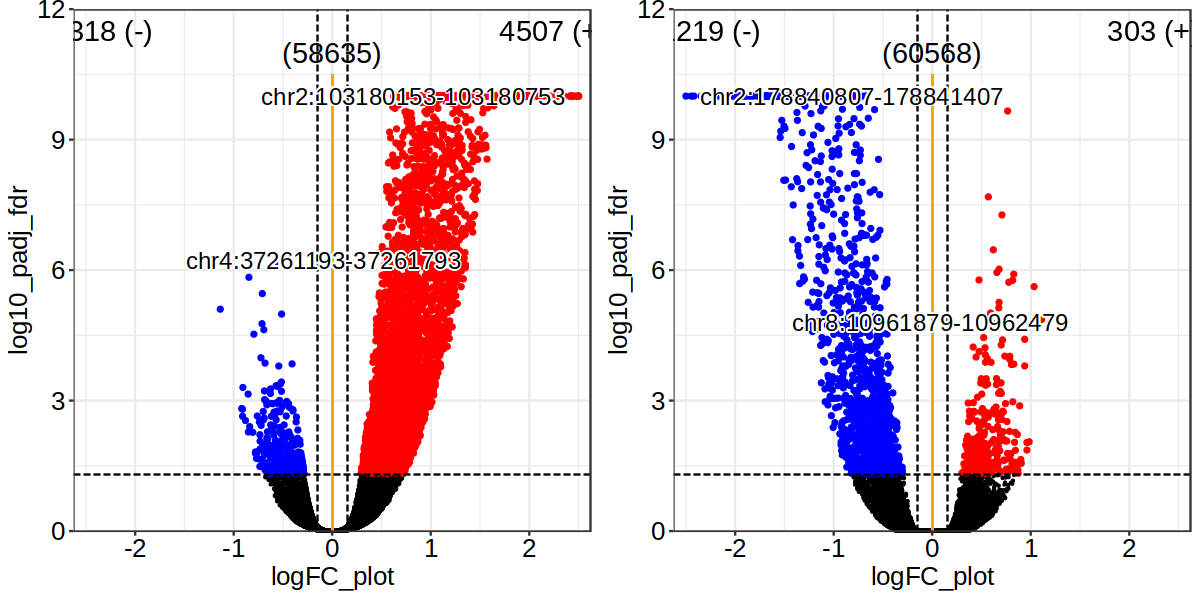

In [64]:
options(repr.plot.width = 10, repr.plot.height = 5)
ggarrange(WT_WT$plot, WT_KD$plot)

In [65]:
fwrite(rbind(WT_WT$DEGs[, test := 'WT_WT'], 
             WT_KD$DEGs[, test := 'WT_KD']), 
       file.path(args$outdir, 'chromatin_comparisons.txt.gz'), sep = '\t')

In [66]:
comparison = merge(WT_WT$DEGs[,.(gene, logFC, sign)] %>% setnames(c('logFC', 'sign'), c('WT_WT_logFC', 'WT_WT_sign')),
                   WT_KD$DEGs[,.(gene, logFC, sign)] %>% setnames(c('logFC', 'sign'), c('WT_KD_logFC', 'WT_KD_sign')),
                   by = 'gene') %>%
        .[, sign := ifelse(WT_WT_sign == 'nonsig' & WT_KD_sign == 'nonsig', 'nonsig',
                           ifelse(WT_WT_sign != 'nonsig' & WT_KD_sign == 'nonsig', 'WT_WT',
                                  ifelse(WT_WT_sign == 'nonsig' & WT_KD_sign != 'nonsig', 'WT_KD',
                                         ifelse(WT_WT_sign != 'nonsig' & WT_KD_sign != 'nonsig', 'both', NA))))] %>%
        .[, sign := factor(sign, levels = c('nonsig', 'WT_WT', 'WT_KD', 'both'))] %>%
        .[order(sign)] %>%
        .[, meanlogFC := (WT_WT_logFC - WT_KD_logFC)/2]

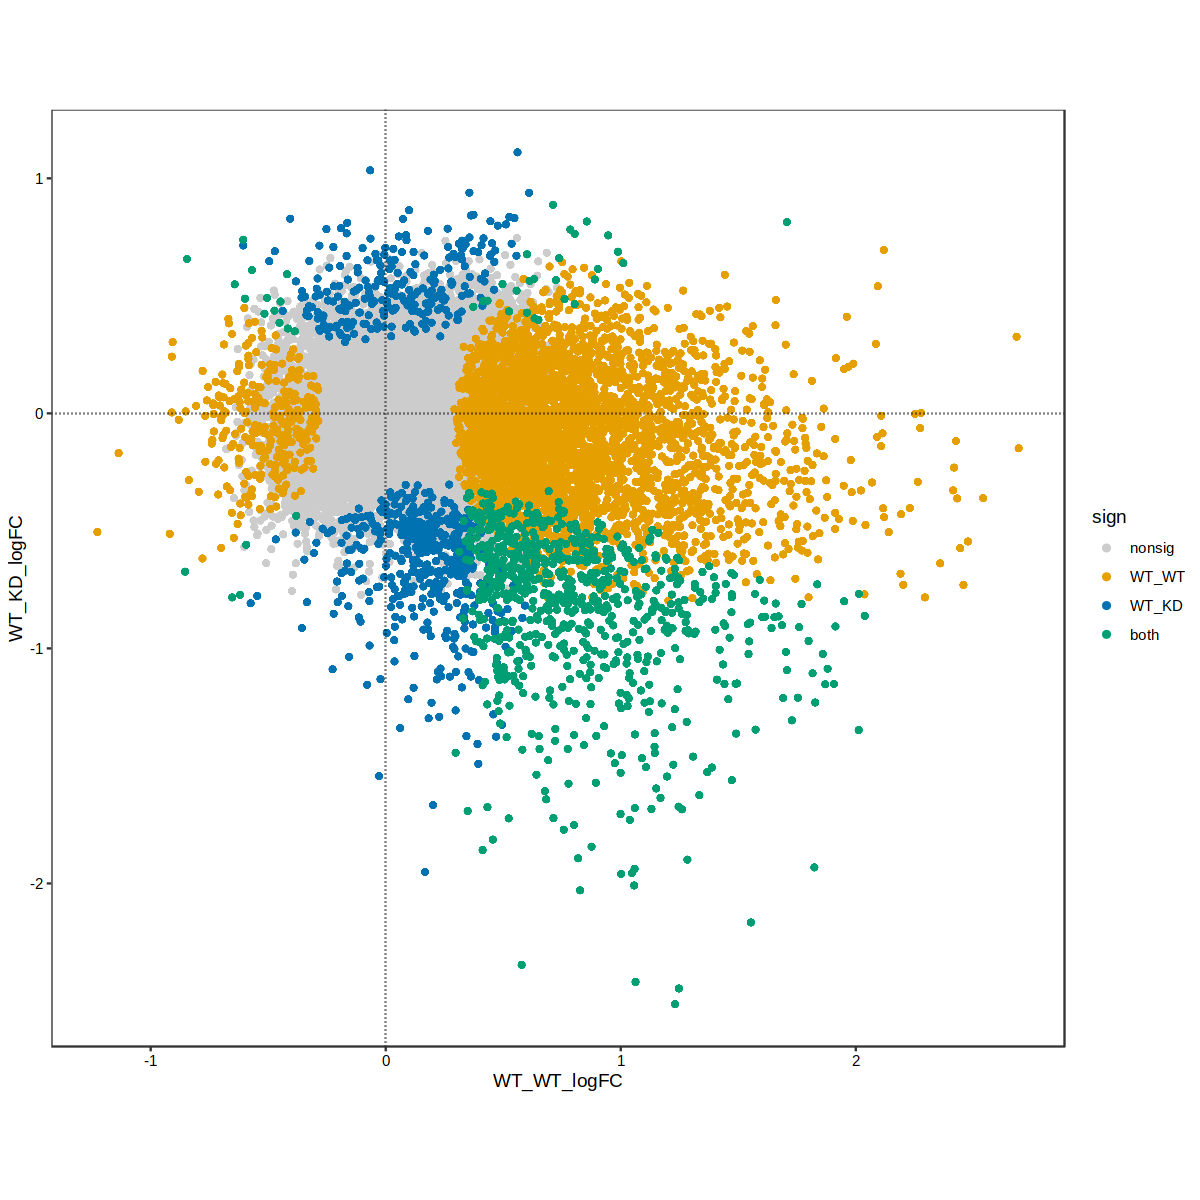

In [67]:
n = 0
label = rbind(
    head(comparison[sign == 'both'][order(meanlogFC)], n),
    head(comparison[sign == 'both'][order(-meanlogFC)], n*3),
        head(comparison[sign == 'WT_WT'][order(WT_WT_logFC)], n),
    head(comparison[sign == 'WT_WT'][order(-WT_WT_logFC)], n),
        head(comparison[sign == 'WT_KD'][order(WT_KD_logFC)], n),
    head(comparison[sign == 'WT_KD'][order(-WT_KD_logFC)], n)
) %>% unique(by = 'gene')

options(repr.plot.width = 10, repr.plot.height = 10)
p_accessibility = ggplot(comparison, aes(WT_WT_logFC, WT_KD_logFC, color = sign)) + 
    ggrastr::rasterize(geom_point(), dpi = 600) +
    geom_hline(yintercept = 0, linetype = 'dotted') + 
    geom_vline(xintercept = 0, linetype = 'dotted') + 
    # geom_abline(intercept = 0, slope = -1) + 
    ggrepel::geom_text_repel(data = label,
                                 aes(label = gene),
                                 color = 'black',
                                 max.overlaps = Inf,
                                size=5,
                                box.padding = 0.5, 
                                bg.color='white', 
                                bg.r = 0.1) + 
    scale_color_manual(values = c(
                    'both' = '#009E73',      # green (colorblind-friendly)
                    'nonsig' = 'grey80',
                    'WT_WT' = '#E69F00',     # orange (colorblind-friendly)
                    'WT_KD' = '#0072B2'      # blue (colorblind-friendly)
                    )) + 
    coord_fixed() + 
    theme_bw() + 
    theme(
        axis.text = element_text(color = 'black'),
        panel.grid = element_blank()
    )
p_accessibility

In [68]:
fwrite(comparison, file.path(args$outdir, 'chromatin_comparisons_combined.csv'), sep = ',')

In [69]:
ggsave(file.path(args$outdir, 'differential_accessibility.pdf'), 
       plot = p_accessibility,
       width = 160, 
       height = 160, 
       units = "mm")

In [70]:
ggsave(file.path(args$outdir, 'differential_combined.pdf'), 
       plot = ggarrange(p_transcriptomics, p_accessibility, align = 'hv'),
       width = 320, 
       height = 160, 
       units = "mm")

In [71]:
## Get motif matches for example motifs in peaks 
## Adapted from: https://rdrr.io/github/GreenleafLab/ArchR/src/R/AnnotationPeaks.R
# Load motifs
library(motifmatchr)
library(chromVARmotifs)

data("mouse_pwms_v2")
motifs <- mouse_pwms_v2
obj <- ArchR:::.summarizeChromVARMotifs(motifs)
motifs <- obj$motifs
motifSummary <- obj$motifSummary
names(motifs) = gsub( 'Tcfap', 'tfap', names(motifs))

# Find scores
motifmatcher.se <-  motifmatchr::matchMotifs(pwms = motifs, 
                                        subject = archr@peakSet, 
                                        genome = "mm10", 
                                        out = 'scores',
                                        p.cutoff = 5e-05,
                                        w = 7) 




Attaching package: ‘XVector’


The following object is masked from ‘package:plyr’:

    compact


The following object is masked from ‘package:purrr’:

    compact



Attaching package: ‘Biostrings’


The following object is masked from ‘package:grid’:

    pattern


The following object is masked from ‘package:base’:

    strsplit




In [72]:
rownames(motifmatcher.se) = rownames(atac.sce)

In [73]:
assay(motifmatcher.se, 'matches') = assay(motifmatcher.se, 'motifMatches')
assay(motifmatcher.se, 'motifScores') = NULL
assay(motifmatcher.se, 'motifMatches') = NULL
assay(motifmatcher.se, 'motifCounts') = NULL
matches = motifmatcher.se

In [74]:
matches = matches[, grep('Gm', colnames(matches), invert = T)]
colnames(matches) = str_to_upper(colnames(matches))

In [75]:
options(repr.plot.width = 20, repr.plot.height = 3)

DARs = WT_WT$DEGs
WT_WT_up = as.data.table(ArchR:::.computeEnrichment(matches,  DARs[logFC > 0 & padj_fdr < 5e-2, gene], seq_len(nrow(matches)))) %>%
        .[,feature := str_split(feature, '_') %>% map_chr(1)] %>% 
        .[mlog10Padj > -log10(0.05)] %>%
        .[order(-mlog10Padj)] %>% 
        .[,I := .I] %>%
        .[,test := 'Up in aPS differentiation']

WT_WT_down = as.data.table(ArchR:::.computeEnrichment(matches,  DARs[logFC < 0 & padj_fdr < 5e-2, gene], seq_len(nrow(matches)))) %>%
        .[,feature := str_split(feature, '_') %>% map_chr(1)] %>% 
        .[mlog10Padj > -log10(0.05)] %>%
        .[order(-mlog10Padj)] %>% 
        .[,I := .I] %>%
        .[,test := 'Down in aPS differentiation']

DARs = WT_KD$DEGs
WT_KD_up = as.data.table(ArchR:::.computeEnrichment(matches,  DARs[logFC < 0 & padj_fdr < 5e-2, gene], seq_len(nrow(matches)))) %>%
        .[,feature := str_split(feature, '_') %>% map_chr(1)] %>% 
        .[mlog10Padj > -log10(0.05)] %>%
        .[order(-mlog10Padj)] %>% 
        .[,I := .I] %>%
        .[,test := 'Down upon EOMES KD in PS2']


WT_KD_down = as.data.table(ArchR:::.computeEnrichment(matches,  DARs[logFC > 0 & padj_fdr < 5e-2, gene], seq_len(nrow(matches)))) %>%
        .[,feature := str_split(feature, '_') %>% map_chr(1)] %>% 
        .[mlog10Padj > -log10(0.05)] %>%
        .[order(-mlog10Padj)] %>% 
        .[,I := .I] %>%
        .[,test := 'Up upon EOMES KD in PS2']


motifs = rbind(WT_WT_up, WT_WT_down, WT_KD_up, WT_KD_down) %>%
    .[, test := factor(test, levels = c('Up in aPS differentiation','Down upon EOMES KD in PS2','Down in aPS differentiation','Up upon EOMES KD in PS2'))]

In [76]:
motif_families = 
    rbind(
        data.table(
            feature = c(motifs$feature[startsWith(motifs$feature, 'TBX')],
                        motifs$feature[startsWith(motifs$feature, 'TBR')],
                        'EOMES', 'MGA', 'T'),
            family = 'T-BOX'
            ),
        data.table(
            feature = c(motifs$feature[startsWith(motifs$feature, 'FOX')]),
            family = 'FOX'
            ),
        data.table(
            feature = c(motifs$feature[startsWith(motifs$feature, 'TCF')],
                        motifs$feature[startsWith(motifs$feature, 'LEF')]),
            family = 'TCF/LEF'
            ),
        data.table(
            feature = c(motifs$feature[startsWith(motifs$feature, 'SOX')]),
            family = 'SOX'
            ),
        data.table(
            feature = c(motifs$feature[startsWith(motifs$feature, 'POU')]),
            family = 'POU'
            )
        )

In [77]:
motifs$family = motif_families[match(motifs$feature, feature), family]
motifs$family = ifelse(is.na(motifs$family), 'OTHER', motifs$family)

In [78]:
family_colors = c(
    'T-BOX' = "#0072B2",
    'FOX' = "#E69F00",
    'TCF/LEF' = "#009E73",  
    'SOX' = "#b965f9",
    'POU' = "#D55E00",
    'OTHER' = 'black'
    )

In [79]:
head(motifs)

feature,CompareFrequency,nCompare,CompareProportion,BackgroundFrequency,nBackground,BackgroundProporition,Enrichment,mlog10p,mlog10Padj,I,test,family
<chr>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<fct>,<chr>
FOXA1,1325,4507,0.2939871,9556,66178,0.14439844,2.035944,158.4402,157.4860,1,Up in aPS differentiation,FOX
FOXL1,1679,4507,0.3725316,13680,66178,0.20671522,1.802149,155.3068,154.3526,2,Up in aPS differentiation,FOX
TBX1,878,4507,0.1948081,5659,66178,0.08551180,2.278143,126.2035,125.2493,3,Up in aPS differentiation,T-BOX
TBX10,878,4507,0.1948081,5659,66178,0.08551180,2.278143,126.2035,125.2493,4,Up in aPS differentiation,T-BOX
FOXC1,1142,4507,0.2533836,8516,66178,0.12868325,1.969049,122.0622,121.1080,5,Up in aPS differentiation,FOX
EOMES,834,4507,0.1850455,5348,66178,0.08081235,2.289817,120.4543,119.5001,6,Up in aPS differentiation,T-BOX


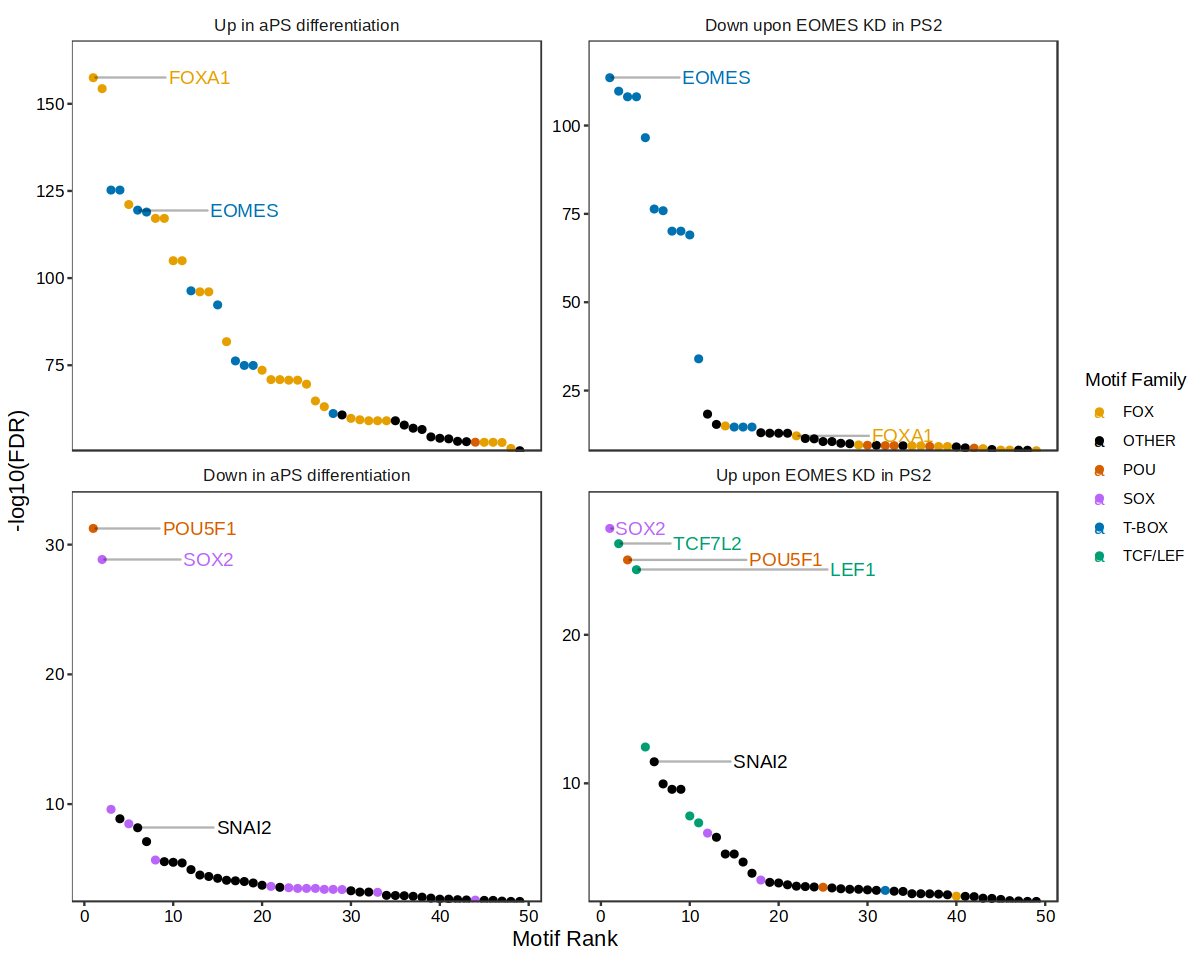

In [80]:
options(repr.plot.width = 10, repr.plot.height = 8)
motifs_to_plot = c('EOMES', 'FOXA1', 'SOX2', 'POU5F1', 'SNAI2', 'TCF7L2', 'LEF1')
p = ggplot(motifs[I < 50], aes(I, mlog10Padj, color = family)) + 
    geom_point() + 
    ggrepel::geom_text_repel(
        data = motifs[I < 50][feature %in% motifs_to_plot], 
        aes(label = feature), 
        segment.color = 'black',
        segment.alpha = 0.3,
        nudge_x = 12,                # Base nudge to the right
        direction = "x",            # Only move vertically to resolve overlaps
        force = 3,                # Increase force to push overlapping labels apart
        max.overlaps = Inf,         # Allow all labels
        min.segment.length = 0,     # Always draw segments
        segment.curvature = 90,      # No curve in lines
        segment.angle = 0,          # Horizontal lines
        segment.ncp = 1,
        box.padding = 0.15,          # Increase padding to help push overlapping labels further right
        xlim = c(NA, max(motifs$I, na.rm = TRUE) + 5) # Allow more space to the right
    ) + 
    scale_y_continuous(expand = c(0,0,0.10,0), name = '-log10(FDR)') + 
    scale_x_continuous(name = 'Motif Rank') + 
    scale_color_manual(values = family_colors, name = 'Motif Family') +
    facet_wrap(~test, scale = 'free_y') + 
    theme_bw() + 
    theme(
        strip.background = element_blank(),
        strip.text = element_text(size = 10),
        axis.text = element_text(size = 10, color = 'black'),
        axis.title = element_text(size = 13, color = 'black'),
        panel.grid = element_blank()
    )
p
ggsave(file.path(args$outdir, 'motif_enrichment.pdf'), 
       plot = p,
       width = 160, 
       height = 100, 
       units = "mm")

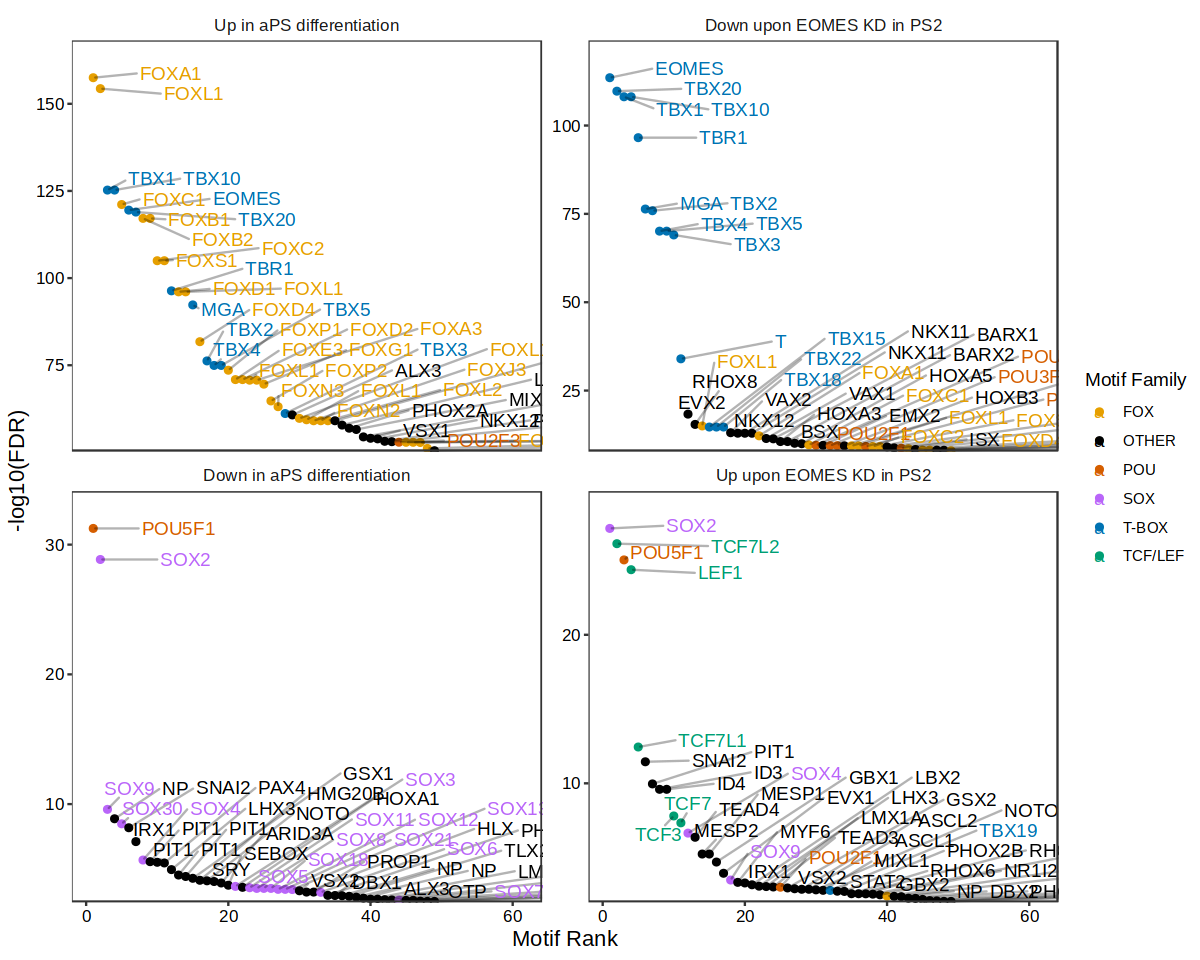

In [81]:
options(repr.plot.width = 10, repr.plot.height = 8)
p = ggplot(motifs[I < 50], aes(I, mlog10Padj, color = family)) + 
    geom_point() + 
    ggrepel::geom_text_repel(
        data = motifs[I < 50], 
        aes(label = feature), 
        segment.color = 'black',
        segment.alpha = 0.3,
        nudge_x = 12,                # Base nudge to the right
        # direction = "x",            # Only move vertically to resolve overlaps
        force = 3,                # Increase force to push overlapping labels apart
        max.overlaps = Inf,         # Allow all labels
        min.segment.length = 0,     # Always draw segments
        segment.curvature = 90,      # No curve in lines
        segment.angle = 0,          # Horizontal lines
        segment.ncp = 1,
        box.padding = 0.15,          # Increase padding to help push overlapping labels further right
        xlim = c(NA, max(motifs$I, na.rm = TRUE) + 5) # Allow more space to the right
    ) + 
    scale_y_continuous(expand = c(0,0,0.10,0), name = '-log10(FDR)') + 
    scale_x_continuous(name = 'Motif Rank') + 
    scale_color_manual(values = family_colors, name = 'Motif Family') +
    facet_wrap(~test, scale = 'free_y') + 
    theme_bw() + 
    theme(
        strip.background = element_blank(),
        strip.text = element_text(size = 10),
        axis.text = element_text(size = 10, color = 'black'),
        axis.title = element_text(size = 13, color = 'black'),
        panel.grid = element_blank()
    )
p

# Plotting regions

In [82]:
comparison = fread(file.path(args$outdir, 'chromatin_comparisons_combined.csv'), sep = ',')

In [83]:
meta$genotype = gsub('_KO', ' KD', meta$genotype)
meta$celltype_genotype = paste0(meta$celltype_manual, ' (', gsub('Eomes ', '', meta$genotype), ')')
meta$celltype_genotype = factor(meta$celltype_genotype, 
                                  levels = c(
                                      'Epiblast (WT)',
                                      'Epiblast (KD)',
                                      'PS 1 (WT)', 
                                      'PS 1 (KD)', 
                                      'PS 2 (WT)', 
                                      'PS 2 (KD)', 
                                      'aPS (WT)',
                                      'aPS (KD)'
                                    )
                                  )

In [84]:
# archr = addCellColData(
#     ArchRProj = archr,
#     data = as.character(meta$celltype_genotype),
#     name = 'celltype_genotype2',
#     cells = meta$cell,
#     force = TRUE)

# archr = archr[meta[day == 'D3', cell], ]

# getGroupBW(
#   ArchRProj = archr,
#   groupBy = "celltype_genotype2",
#   normMethod = "ReadsInTSS",
#   tileSize = 100,
#   maxCells = 1e9)

In [85]:
archr


           ___      .______        ______  __    __  .______      
          /   \     |   _  \      /      ||  |  |  | |   _  \     
         /  ^  \    |  |_)  |    |  ,----'|  |__|  | |  |_)  |    
        /  /_\  \   |      /     |  |     |   __   | |      /     
       /  _____  \  |  |\  \\___ |  `----.|  |  |  | |  |\  \\___.
      /__/     \__\ | _| `._____| \______||__|  |__| | _| `._____|
    



class: ArchRProject 
outputDirectory: /rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/processed/atac/archR 
samples(8): RBG43471 RBG43472 ... RBG43477 RBG43478
sampleColData names(1): ArrowFiles
cellColData names(38): Sample TSSEnrichment ... ReadsInPeaks FRIP
numberOfCells(1): 68312
medianTSS(1): 14.034
medianFrags(1): 20956

In [86]:
meta = fread(file.path(args$outdir, 'd253_celltypes.txt.gz'))
meta$genotype = gsub('_KO', ' KD', meta$genotype)
meta$celltype_genotype = paste0(meta$celltype_manual, ' (', gsub('Eomes ', '', meta$genotype), ')')
meta$celltype_genotype = factor(meta$celltype_genotype, 
                                  levels = c(
                                    'Epiblast (KD)',
                                    'Epiblast (WT)',     
                                    'PS 1 (KD)', 
                                    'PS 1 (WT)', 
                                    'PS 2 (KD)', 
                                    'PS 2 (WT)',       
                                    'aPS (KD)',
                                    'aPS (WT)'
                                    )
                                  )

In [87]:
# Load browser track files
ArchRProject = suppressMessages(ArchR::loadArchRProject(io$archR.directory))

args$vitro_bws = file.path(io$basedir, 'processed/atac/archR/GroupBigWigs/celltype_genotype2/')

bigwigs.data_vitro = data.table(celltype = list.files(args$vitro_bws, 'bw') %>% str_split(., '-') %>% map_chr(1),
                    path =  paste0(args$vitro_bws, list.files(args$vitro_bws, 'bw'))) 

# bigwig_order = c(
#                 'WT_depleted','WT_nearest',
#                 'KD_nearest'
# )
# WT_plot = bigwigs.data_vitro %>% copy() %>%
#     .[match(bigwig_order, celltype)] %>% 
#     .[, name := factor(celltype, levels = bigwig_order)] %>% 
#                 .[,color := c('#000000', '#000000', '#FF0000')]

WT_plot = bigwigs.data_vitro %>% copy() %>%
    .[,color := ifelse(grepl('WT', path), '#000000', '#FF0000')] %>%
    .[, name := celltype]

In [88]:
unique(WT_plot$name)

[1] "aPS..KD."      "aPS..WT."      "Epiblast..KD." "Epiblast..WT."
[5] "PS.1..KD."     "PS.1..WT."     "PS.2..KD."     "PS.2..WT."

In [89]:
format_string <- function(x) {
    x <- gsub("\\.\\.", " (", x)
    x <- gsub("\\.$", ")", x)
    x <- gsub("\\.", " ", x)
    x
}

In [90]:
WT_plot$name = format_string(WT_plot$name)
WT_plot$celltype = format_string(WT_plot$celltype)

In [91]:
WT_plot$name

[1] "aPS (KD)"      "aPS (WT)"      "Epiblast (KD)" "Epiblast (WT)"
[5] "PS 1 (KD)"     "PS 1 (WT)"     "PS 2 (KD)"     "PS 2 (WT)"

In [92]:
WT_plot = WT_plot[!name %in% c('aPS (KD)', 'Epiblast (KD)', 'Epiblast (WT)', 'PS 1 (WT)', 'PS 1 (KD)')] %>%
    .[, name := factor(name, levels = c(
        'PS 2 (KD)','PS 2 (WT)','aPS (WT)'
        ))
    ] %>% .[order(name)]

In [93]:
genes = archr@geneAnnotation$genes
start(genes) = start(genes) - 1.5e5
end(genes) = end(genes) + 1.5e5
peaks = archr@peakSet
overlaps = findOverlaps(genes, peaks)

Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 13 out-of-bound ranges located on sequences
  chr2, chr3, chr7, chr8, chr9, chr12, chr13, chr15, chr16, and chr17.
  Note that ranges located on a sequence whose length is unknown (NA) or
  on a circular sequence are not considered out-of-bound (use
  seqlengths() and isCircular() to get the lengths and circularity flags
  of the underlying sequences). You can use trim() to trim these ranges.
  See ?`trim,GenomicRanges-method` for more information.”


In [94]:
peaks.dt = data.table(peak = paste0(seqnames(peaks), ':', start(peaks), '-', end(peaks)),
                      chr =  paste0(seqnames(peaks)),
                      start = start(peaks),
                      end = end(peaks)) %>% 
    .[, subjectHits := .I]
links = data.table(gene = genes$symbol[queryHits(overlaps)],
                   gene_strt = start(genes)[queryHits(overlaps)]+1.5e5,
                   gene_end = end(genes)[queryHits(overlaps)]-1.5e5,
                   peak = peaks.dt$peak[subjectHits(overlaps)])
links = merge(links, peaks.dt[,.(peak, chr, start, end)], by = 'peak')

In [95]:
head(peaks.dt)

peak,chr,start,end,subjectHits
<chr>,<chr>,<int>,<int>,<int>
chr1:3191544-3192144,chr1,3191544,3192144,1
chr1:3549359-3549959,chr1,3549359,3549959,2
chr1:3648815-3649415,chr1,3648815,3649415,3
chr1:3670788-3671388,chr1,3670788,3671388,4
chr1:3671520-3672120,chr1,3671520,3672120,5
chr1:3672281-3672881,chr1,3672281,3672881,6


In [96]:
nrow(meta)

[1] 34628

In [97]:
unique(meta$celltype_genotype)

[1] PS 1 (WT)     Epiblast (WT) PS 2 (WT)     aPS (WT)      PS 2 (KD)    
[6] PS 1 (KD)     Epiblast (KD) aPS (KD)     
8 Levels: Epiblast (KD) Epiblast (WT) PS 1 (KD) PS 1 (WT) ... aPS (WT)

In [98]:
rna.sce_filt = rna.sce[, meta[celltype_genotype %in% WT_plot$name]$cell]
meta = meta[match(colnames(rna.sce_filt), cell)]

In [99]:
summary(colnames(rna.sce_filt) == meta[celltype_genotype %in% WT_plot$name]$cell)

   Mode    TRUE 
logical   16551 

In [100]:
rna.sce_filt$celltype = meta[celltype_genotype %in% WT_plot$name]$celltype_genotype

In [101]:
intersect(unique(rna.sce_filt$celltype),
WT_plot$name)

[1] "PS 2 (WT)" "aPS (WT)"  "PS 2 (KD)"

In [102]:
table(rna.sce_filt$celltype)


Epiblast (KD) Epiblast (WT)     PS 1 (KD)     PS 1 (WT)     PS 2 (KD) 
            0             0             0             0         10712 
    PS 2 (WT)      aPS (KD)      aPS (WT) 
         2780             0          3059 

In [103]:
plot_gene_bigwig = function(gene_in, extend.upstream = 1e3, extend.downstream = 1e3){
    DARs = comparison
    peaks = links[gene %in% gene_in & peak %in% DARs[sign != 'nonsig']$gene,] %>%
        merge(., DARs, by.x = 'peak', by.y = 'gene')
    region = paste0(peaks$chr[1], ':', min(c(peaks$start, peaks$gene_strt)) - extend.downstream, '-', max(peaks$end, peaks$gene_end) + extend.upstream)

    highlight_colors = ifelse(peaks$sign == 'both', "#b8fca4", 
                              ifelse(peaks$sign == 'WT_KD', "#80fff9",
                                    'grey90'))
    names(highlight_colors) = str_split(str_split(peaks[, peak], ':') %>% map_chr(2), '-') %>% map_chr(1)
    
    p1 = plot_browser_track(gene = gene_in, # Only choose one of gene/input_region, otherwise will use region
                              input_region = region, #'chr10:101890817-101891317', 
                              WT_plot, 
                              plot_expression = T,
                              sce = rna.sce_filt,
                              extend.upstream = 0,
                              extend.downstream = 0, 
                              highlight_regions = peaks$peak,
                              downsample.rate = 1, 
                              no_label = T, 
                              background_color = 'white',
                              highlight_color = highlight_colors,
                              bw_height = 40, 
                              gene_height = 10, 
                              bw_width = 200,
                              expr_width = 20)
    return(p1)
    }

In [104]:
get_enhancers = function(gene_in, extend.upstream = 1000, extend.downstream = 1000){
    DARs = comparison
    peaks = links[gene %in% gene_in & peak %in% DARs[sign != 
        "nonsig"]$gene, ] %>% merge(., DARs, by.x = "peak", by.y = "gene")
    region = paste0(peaks$chr[1], ":", min(c(peaks$start, peaks$gene_strt)) - 
        extend.downstream, "-", max(peaks$end, peaks$gene_end) + 
        extend.upstream)
    highlight_colors = ifelse(peaks$sign == "both", "#b8fca4", 
        ifelse(peaks$sign == "WT_KD", "#80fff9", "grey90"))
    names(highlight_colors) = str_split(str_split(peaks[, peak], 
        ":") %>% map_chr(2), "-") %>% map_chr(1)
    return(list(peaks, region))
}

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation ideoms with `aes()`”


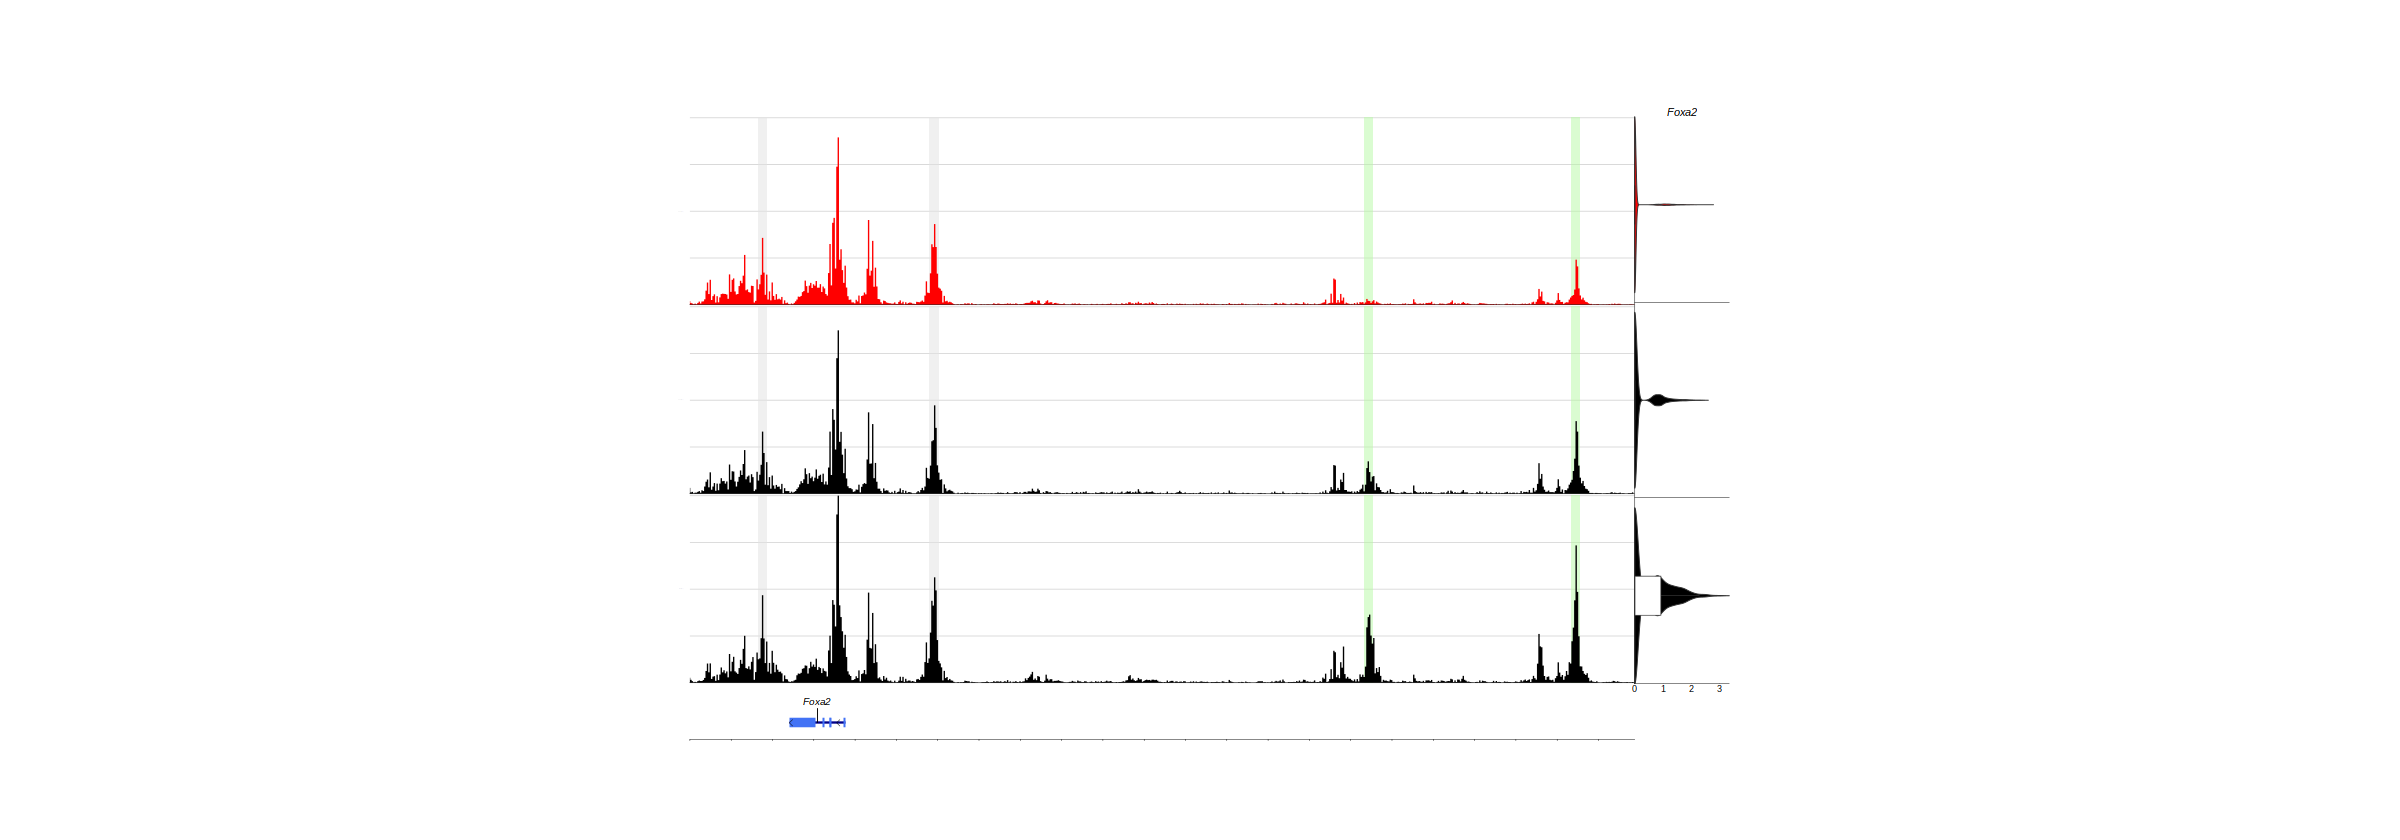

In [105]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Foxa2', extend.upstream = 4e3, extend.downstream = -1.3e5)

In [106]:
get_enhancers('Foxa2', extend.upstream = 4e3, extend.downstream = -1.3e5)

peak,gene,gene_strt,gene_end,chr,start,end,WT_WT_logFC,WT_WT_sign,WT_KD_logFC,WT_KD_sign,sign,meanlogFC
<chr>,<chr>,<dbl>,<dbl>,<chr>,<int>,<int>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<dbl>
chr2:147905671-147906271,Foxa2,148042877,148046969,chr2,147905671,147906271,0.6066602,pos,0.394824607,nonsig,WT_WT,0.1059178
chr2:147968402-147969002,Foxa2,148042877,148046969,chr2,147968402,147969002,1.0311568,pos,-0.151602376,nonsig,WT_WT,0.5913796
chr2:147974682-147975282,Foxa2,148042877,148046969,chr2,147974682,147975282,1.7589834,pos,-0.909611517,neg,both,1.3342975
chr2:148005097-148005697,Foxa2,148042877,148046969,chr2,148005097,148005697,1.5683382,pos,-0.177199979,nonsig,WT_WT,0.8727691
chr2:148040653-148041253,Foxa2,148042877,148046969,chr2,148040653,148041253,0.3951065,pos,-0.004946159,nonsig,WT_WT,0.2000263
chr2:148053096-148053696,Foxa2,148042877,148046969,chr2,148053096,148053696,0.4059335,pos,0.012136055,nonsig,WT_WT,0.1968987
chr2:148084670-148085270,Foxa2,148042877,148046969,chr2,148084670,148085270,1.2474856,pos,-2.446825668,neg,both,1.8471556
chr2:148099708-148100308,Foxa2,148042877,148046969,chr2,148099708,148100308,0.8094878,pos,-0.801138620,neg,both,0.8053132


In [107]:
matrix = as.matrix(matches[c('chr2:148040653-148041253', 'chr2:148053096-148053696', 'chr2:148084670-148085270', 'chr2:148099708-148100308'),
                           grep('EOMES|^TCF|LEF', colnames(matches))]@assays@data$matches)
matrix <- matrix * 1
matrix

,Tcfe3_17,Tcf3_31,Tcfeb_41,Tcfec_53,Tcf12_59,Tcfl5_71,Tcf21_79,Tcf4_88,Tcf15_93,Tcfcp2_389,Tcfcp2l1_391,Tcf7_726,Tcf7l2_732,Lef1_734,Tcf7l1_744,Eomes_768
chr2:148040653-148041253,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
chr2:148053096-148053696,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
chr2:148084670-148085270,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
chr2:148099708-148100308,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0


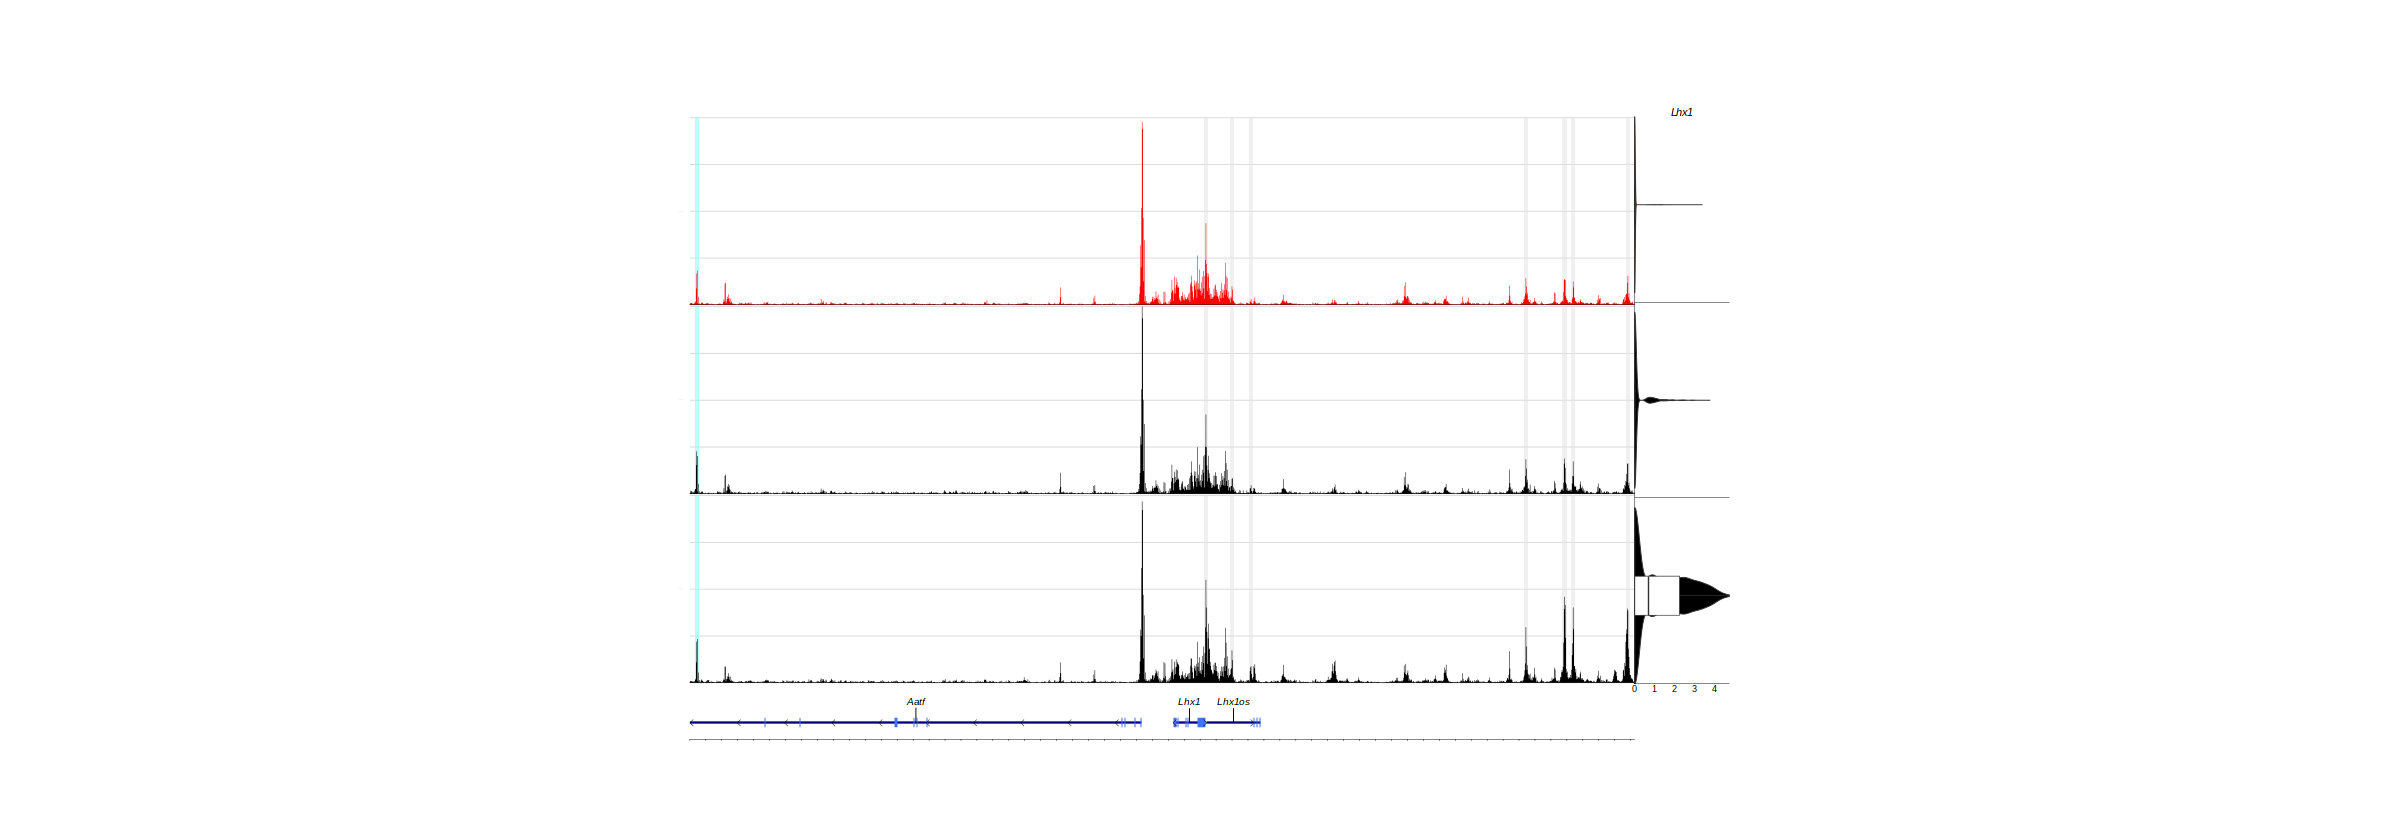

In [108]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Lhx1', extend.upstream = 1e3, extend.downstream = 1e3)

In [109]:
source(here::here("utils.R"))


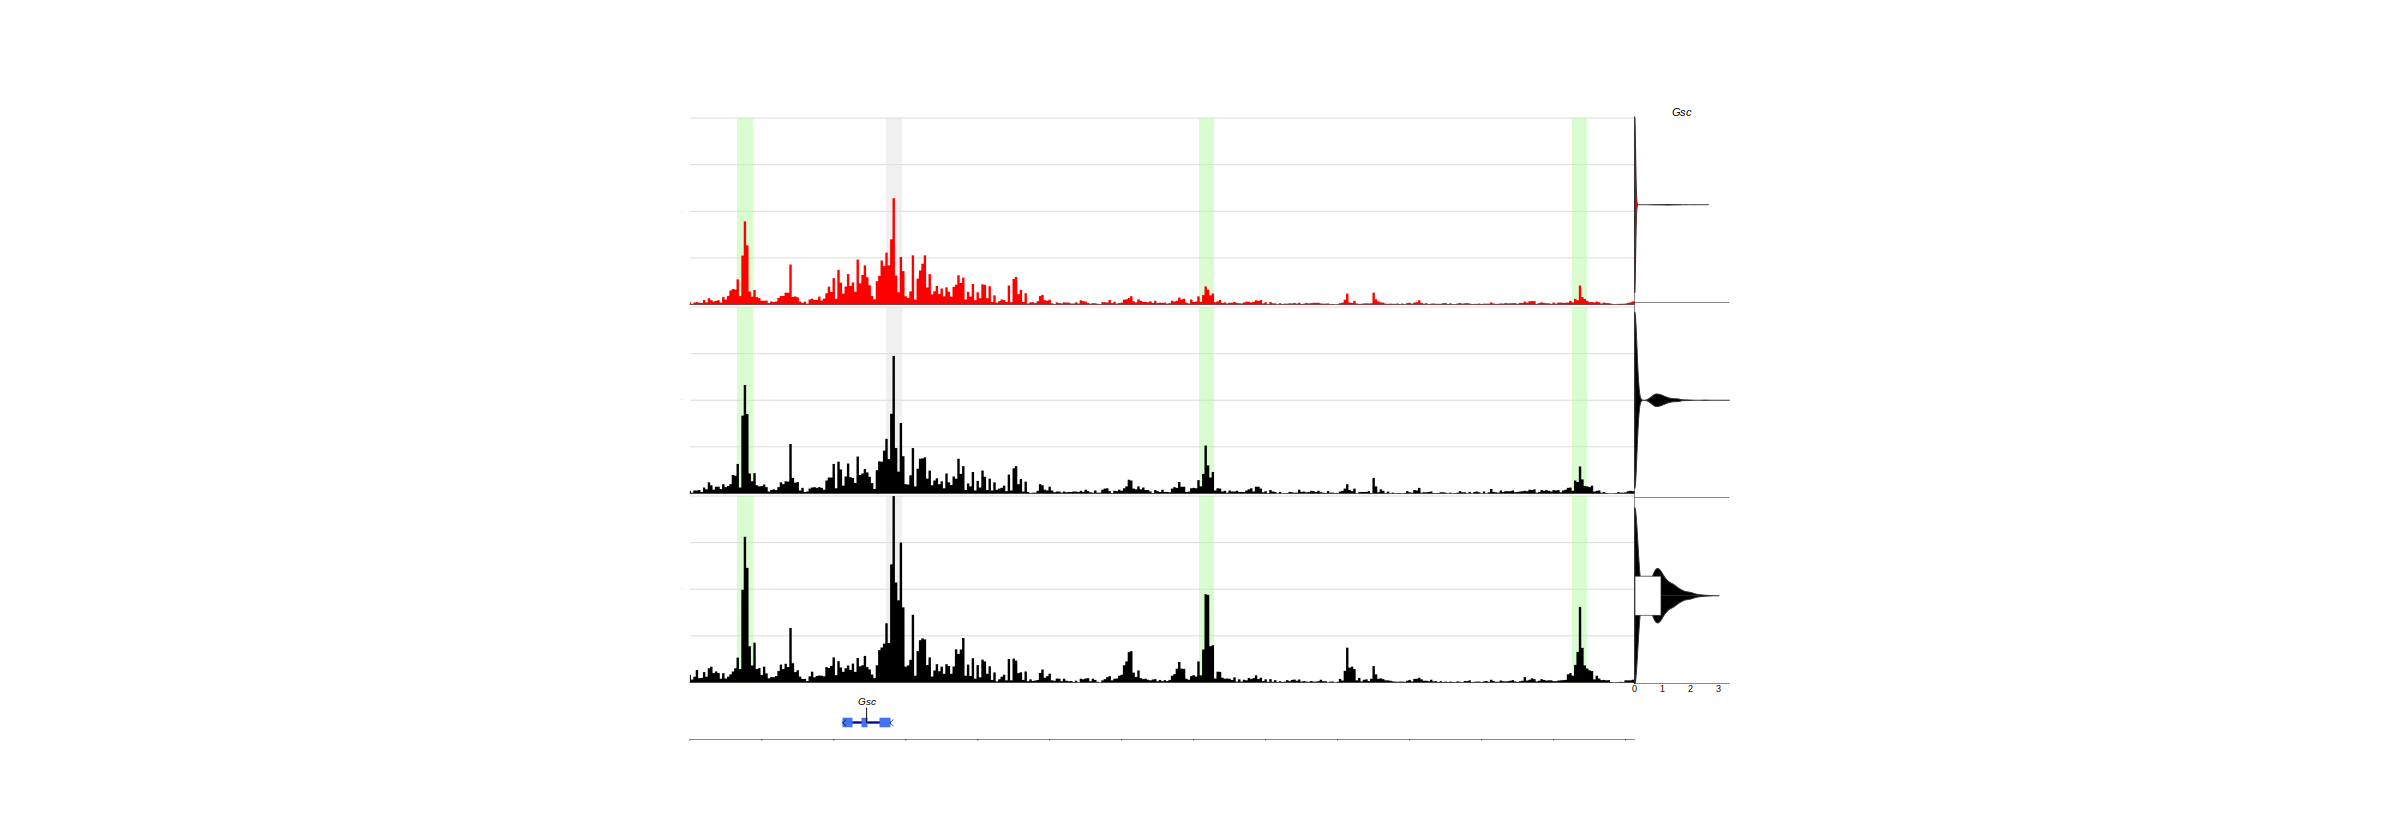

In [110]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Gsc', extend.upstream = 2e3, extend.downstream = 2e3)

In [111]:
enhancers = get_enhancers('Gsc', extend.upstream = 2e3, extend.downstream = 2e3)
enhancers

peak,gene,gene_strt,gene_end,chr,start,end,WT_WT_logFC,WT_WT_sign,WT_KD_logFC,WT_KD_sign,sign,meanlogFC
<chr>,<chr>,<dbl>,<dbl>,<chr>,<int>,<int>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<dbl>
chr12:104466858-104467458,Gsc,104471209,104473236,chr12,104466858,104467458,0.3973070,pos,-0.4220385,neg,both,0.4096727
chr12:104473055-104473655,Gsc,104471209,104473236,chr12,104473055,104473655,0.5921631,pos,-0.3258169,nonsig,WT_WT,0.4589900
chr12:104486090-104486690,Gsc,104471209,104473236,chr12,104486090,104486690,0.9786565,pos,-1.0511282,neg,both,1.0148923
chr12:104501632-104502232,Gsc,104471209,104473236,chr12,104501632,104502232,1.1717710,pos,-0.8266927,neg,both,0.9992319


In [112]:
matrix = as.matrix(matches[enhancers[[1]][0:4, peak],
                           grep('EOMES|^TCF|LEF', colnames(matches))]@assays@data$matches)
matrix <- matrix * 1
matrix

,Tcfe3_17,Tcf3_31,Tcfeb_41,Tcfec_53,Tcf12_59,Tcfl5_71,Tcf21_79,Tcf4_88,Tcf15_93,Tcfcp2_389,Tcfcp2l1_391,Tcf7_726,Tcf7l2_732,Lef1_734,Tcf7l1_744,Eomes_768
chr12:104466858-104467458,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
chr12:104473055-104473655,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
chr12:104486090-104486690,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
chr12:104501632-104502232,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


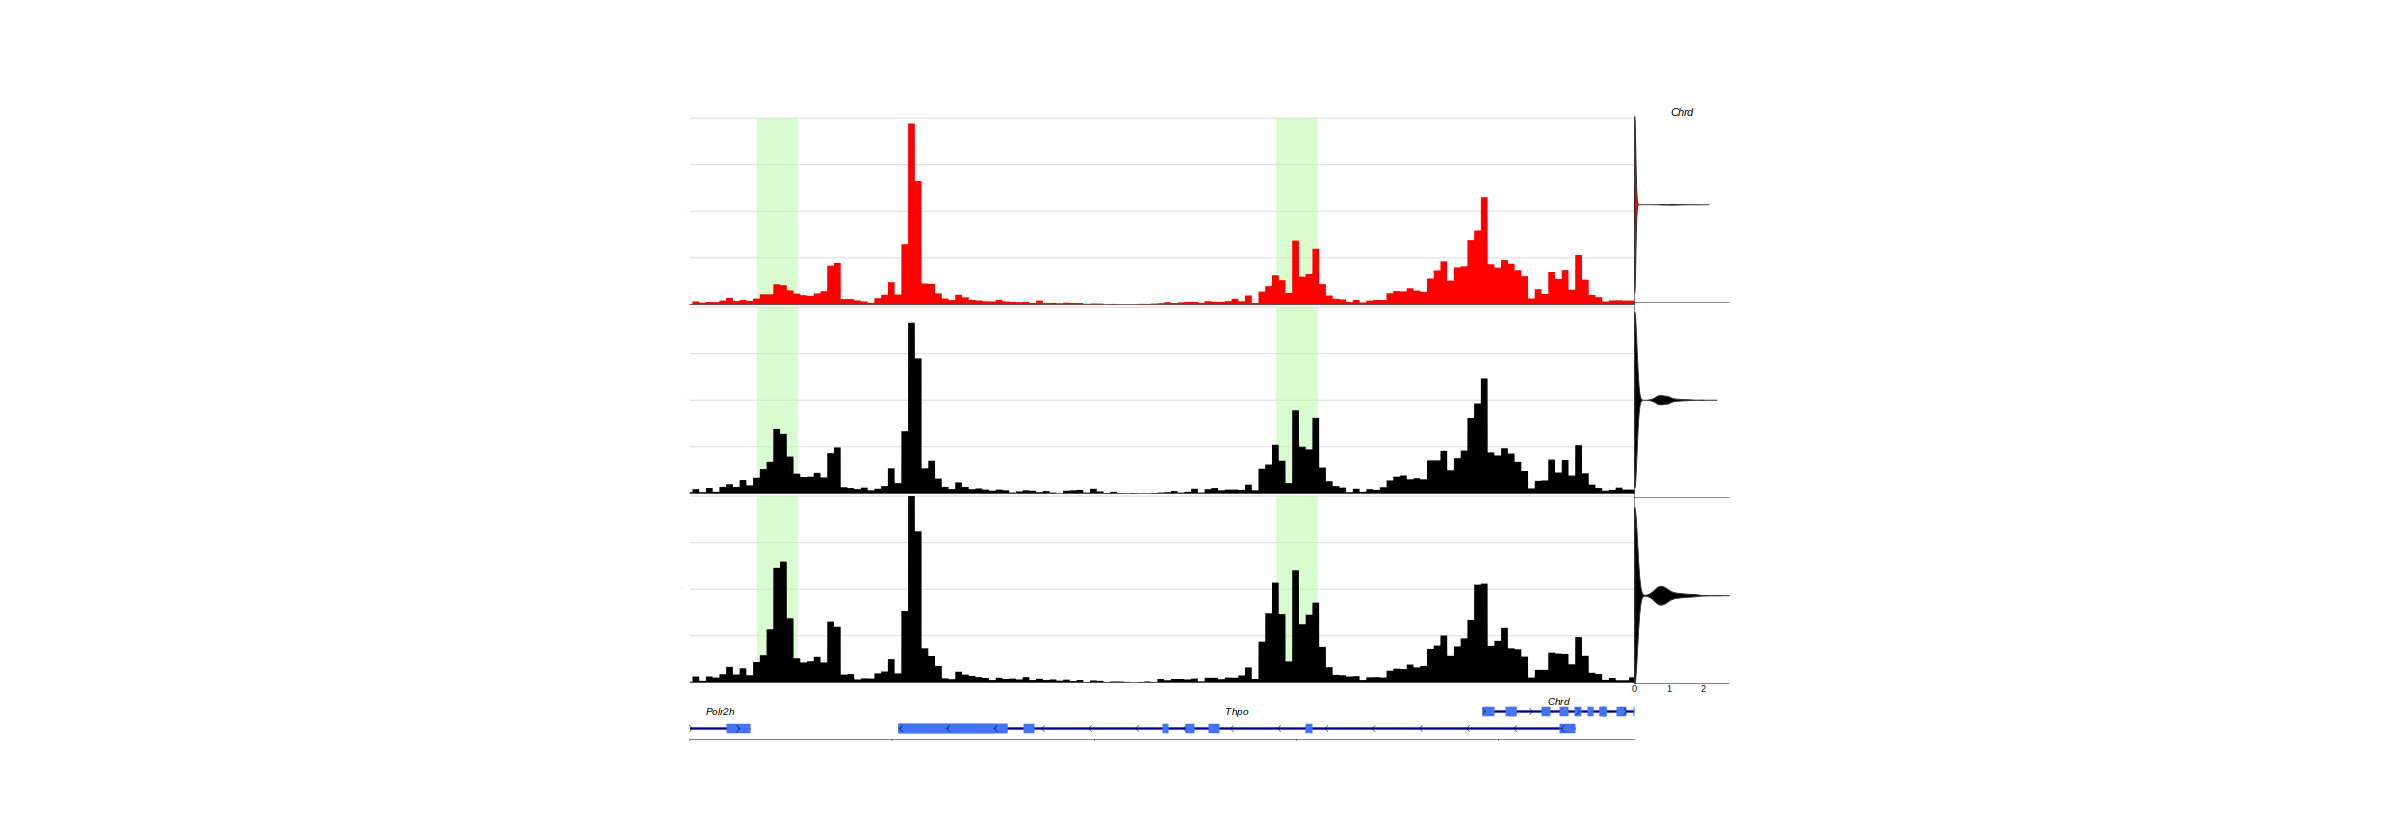

In [113]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Chrd', extend.upstream = -7e3, extend.downstream = 1e3)

In [114]:
enhancers = get_enhancers('Chrd', extend.upstream = 2e3, extend.downstream = 2e3)
enhancers

peak,gene,gene_strt,gene_end,chr,start,end,WT_WT_logFC,WT_WT_sign,WT_KD_logFC,WT_KD_sign,sign,meanlogFC
<chr>,<chr>,<dbl>,<dbl>,<chr>,<int>,<int>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<dbl>
chr16:20722363-20722963,Chrd,20733127,20742384,chr16,20722363,20722963,0.6913909,pos,-1.4755817,neg,both,1.0834863
chr16:20730069-20730669,Chrd,20733127,20742384,chr16,20730069,20730669,0.4516157,pos,-0.4552211,neg,both,0.4534184


In [115]:
matrix = as.matrix(matches[enhancers[[1]][, peak],
                           grep('EOMES|^TCF|LEF', colnames(matches))]@assays@data$matches)
matrix <- matrix * 1
matrix

,Tcfe3_17,Tcf3_31,Tcfeb_41,Tcfec_53,Tcf12_59,Tcfl5_71,Tcf21_79,Tcf4_88,Tcf15_93,Tcfcp2_389,Tcfcp2l1_391,Tcf7_726,Tcf7l2_732,Lef1_734,Tcf7l1_744,Eomes_768
chr16:20722363-20722963,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
chr16:20730069-20730669,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0


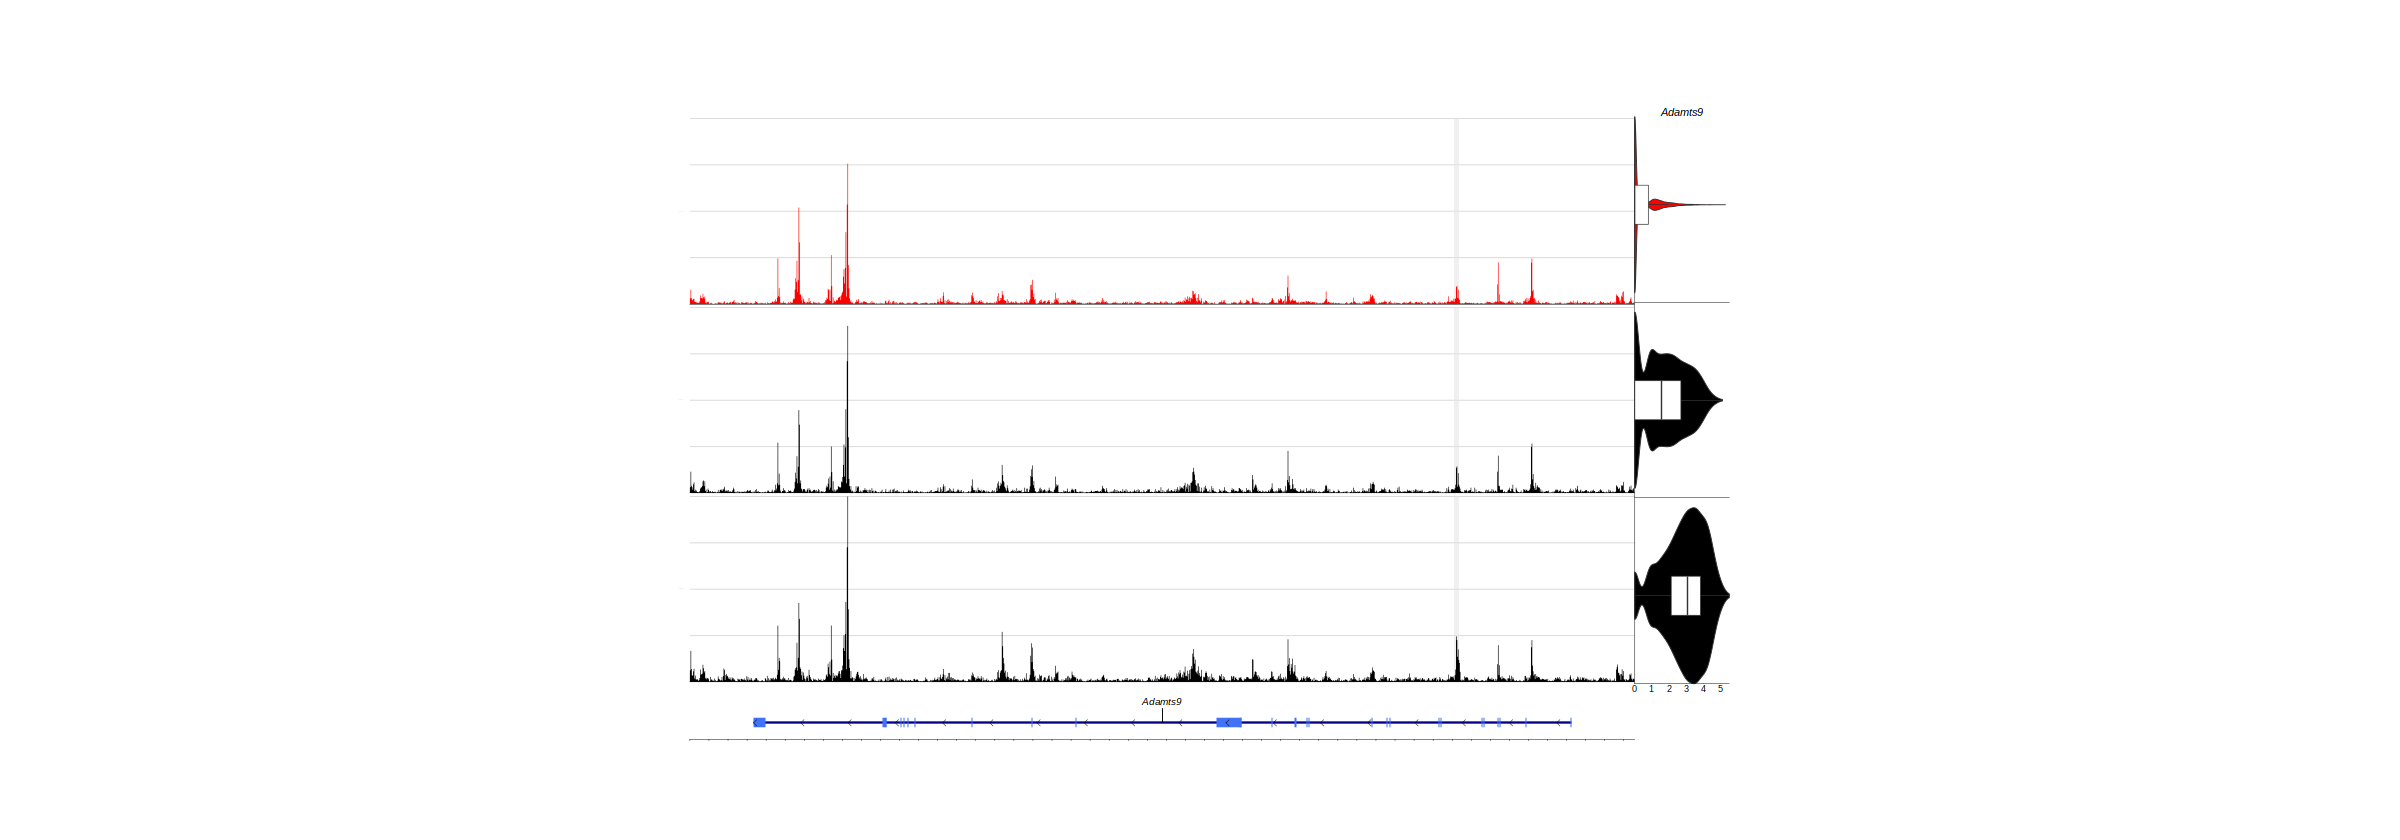

In [116]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Adamts9', extend.upstream = 1e4, extend.downstream = 1e4)

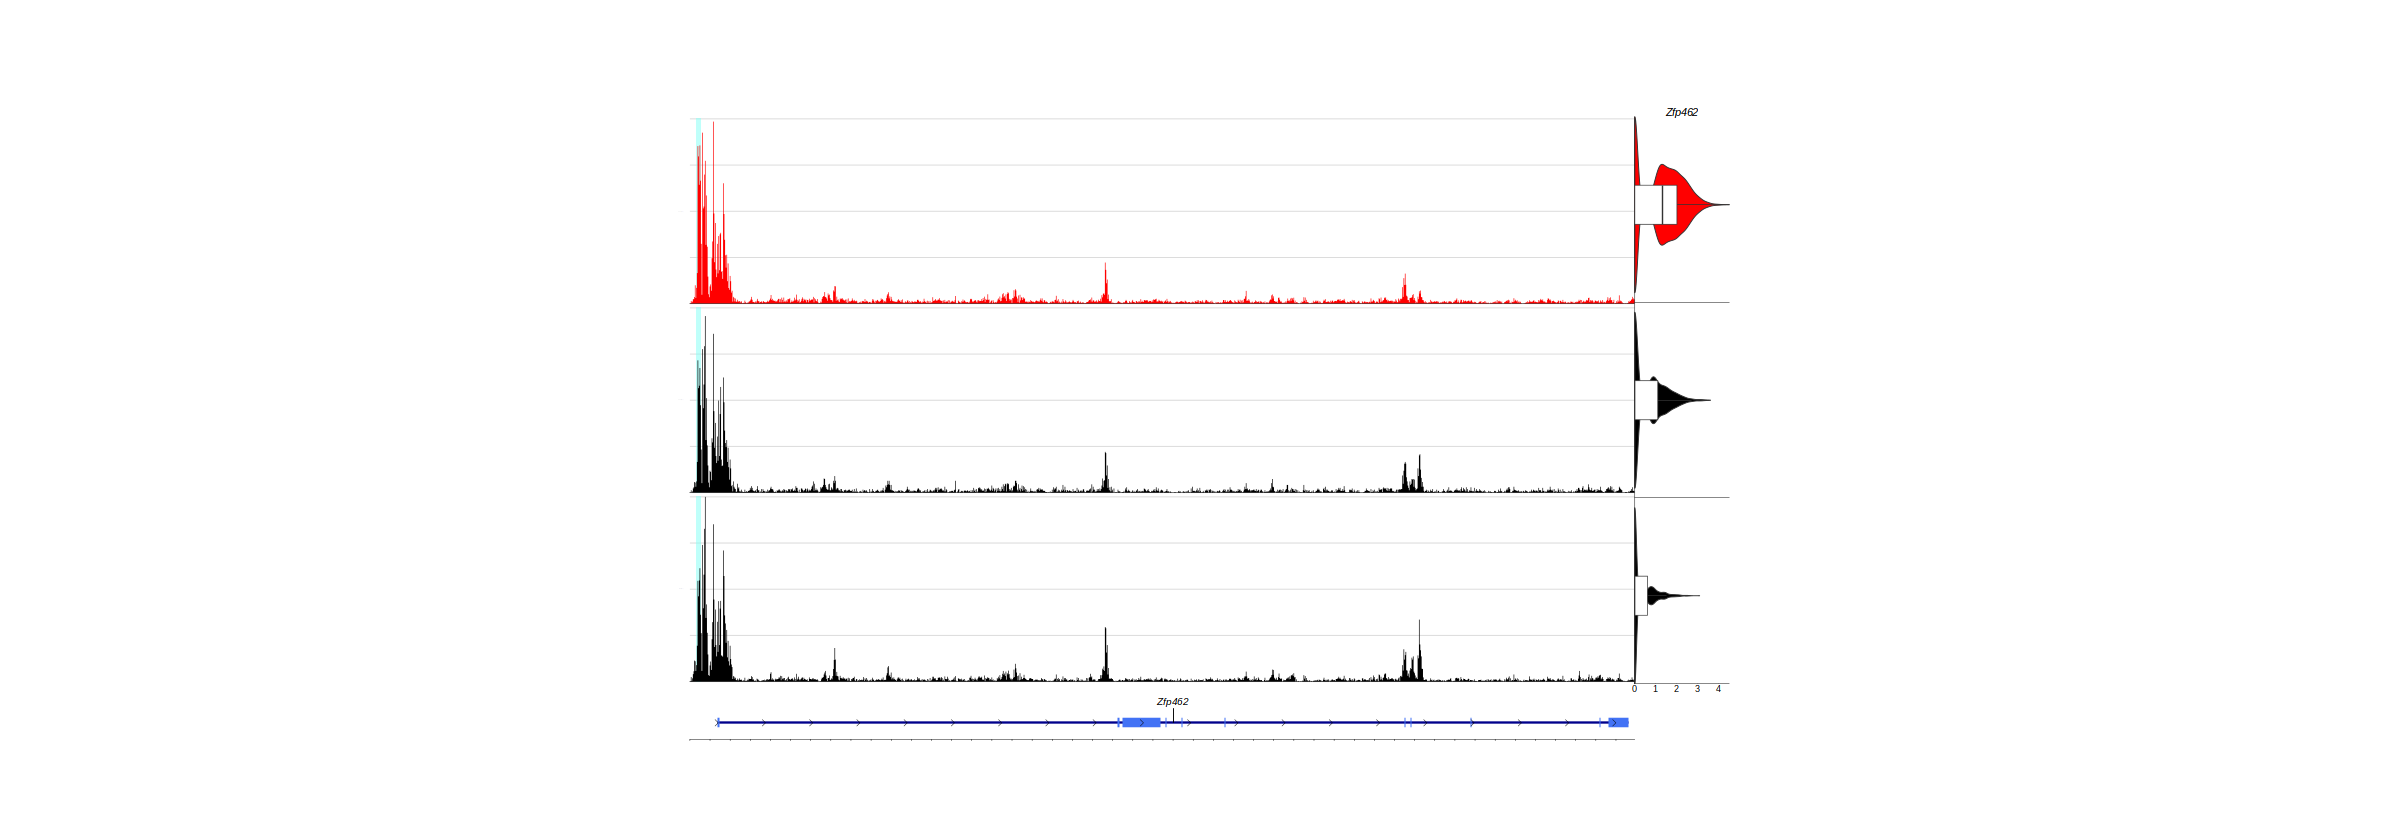

In [117]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Zfp462', extend.upstream = 1e3, extend.downstream = 1e3)

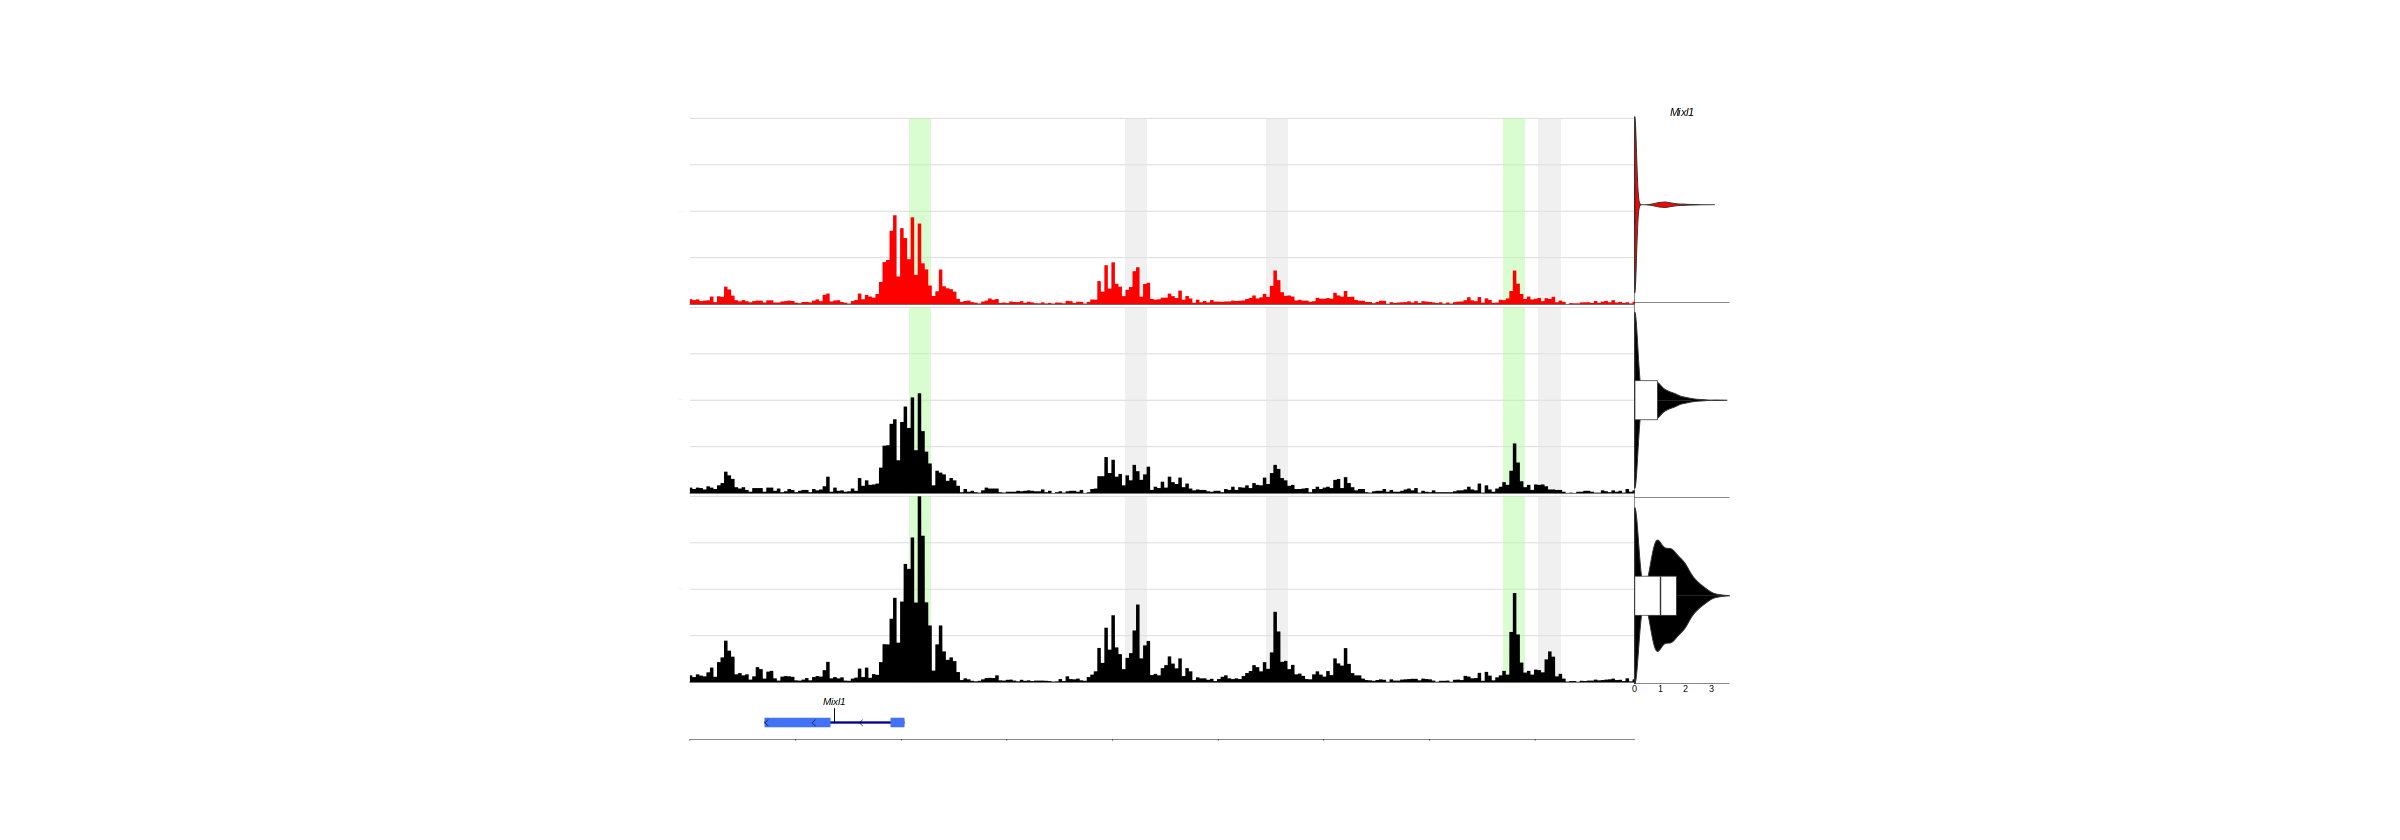

In [118]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Mixl1', extend.upstream = -4.6e4, extend.downstream = -8.5e4)

In [119]:
enhancers = get_enhancers('Mixl1', extend.upstream = -4.6e4, extend.downstream = -8.5e4)
enhancers

peak,gene,gene_strt,gene_end,chr,start,end,WT_WT_logFC,WT_WT_sign,WT_KD_logFC,WT_KD_sign,sign,meanlogFC
<chr>,<chr>,<dbl>,<dbl>,<chr>,<int>,<int>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<dbl>
chr1:180605932-180606532,Mixl1,180693043,180697034,chr1,180605932,180606532,1.7840759,pos,-0.10368296,nonsig,WT_WT,0.9438794
chr1:180697161-180697761,Mixl1,180693043,180697034,chr1,180697161,180697761,0.7359206,pos,-0.37766585,neg,both,0.5567932
chr1:180703304-180703904,Mixl1,180693043,180697034,chr1,180703304,180703904,1.0904933,pos,0.23063419,nonsig,WT_WT,0.4299295
chr1:180707294-180707894,Mixl1,180693043,180697034,chr1,180707294,180707894,0.8506374,pos,-0.07141545,nonsig,WT_WT,0.4610264
chr1:180714033-180714633,Mixl1,180693043,180697034,chr1,180714033,180714633,0.7356779,pos,-0.57237236,neg,both,0.6540251
chr1:180715040-180715640,Mixl1,180693043,180697034,chr1,180715040,180715640,1.5590781,pos,-0.26274858,nonsig,WT_WT,0.9109134
chr1:180763163-180763763,Mixl1,180693043,180697034,chr1,180763163,180763763,0.5100784,pos,0.22236521,nonsig,WT_WT,0.1438566


In [120]:
matrix = as.matrix(matches[enhancers[[1]][2:6, peak],
                           grep('EOMES|^TCF|LEF', colnames(matches))]@assays@data$matches)
matrix <- matrix * 1
matrix

,Tcfe3_17,Tcf3_31,Tcfeb_41,Tcfec_53,Tcf12_59,Tcfl5_71,Tcf21_79,Tcf4_88,Tcf15_93,Tcfcp2_389,Tcfcp2l1_391,Tcf7_726,Tcf7l2_732,Lef1_734,Tcf7l1_744,Eomes_768
chr1:180697161-180697761,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0
chr1:180703304-180703904,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
chr1:180707294-180707894,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0
chr1:180714033-180714633,0,0,0,0,1,0,0,1,1,0,1,0,0,0,0,1
chr1:180715040-180715640,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0


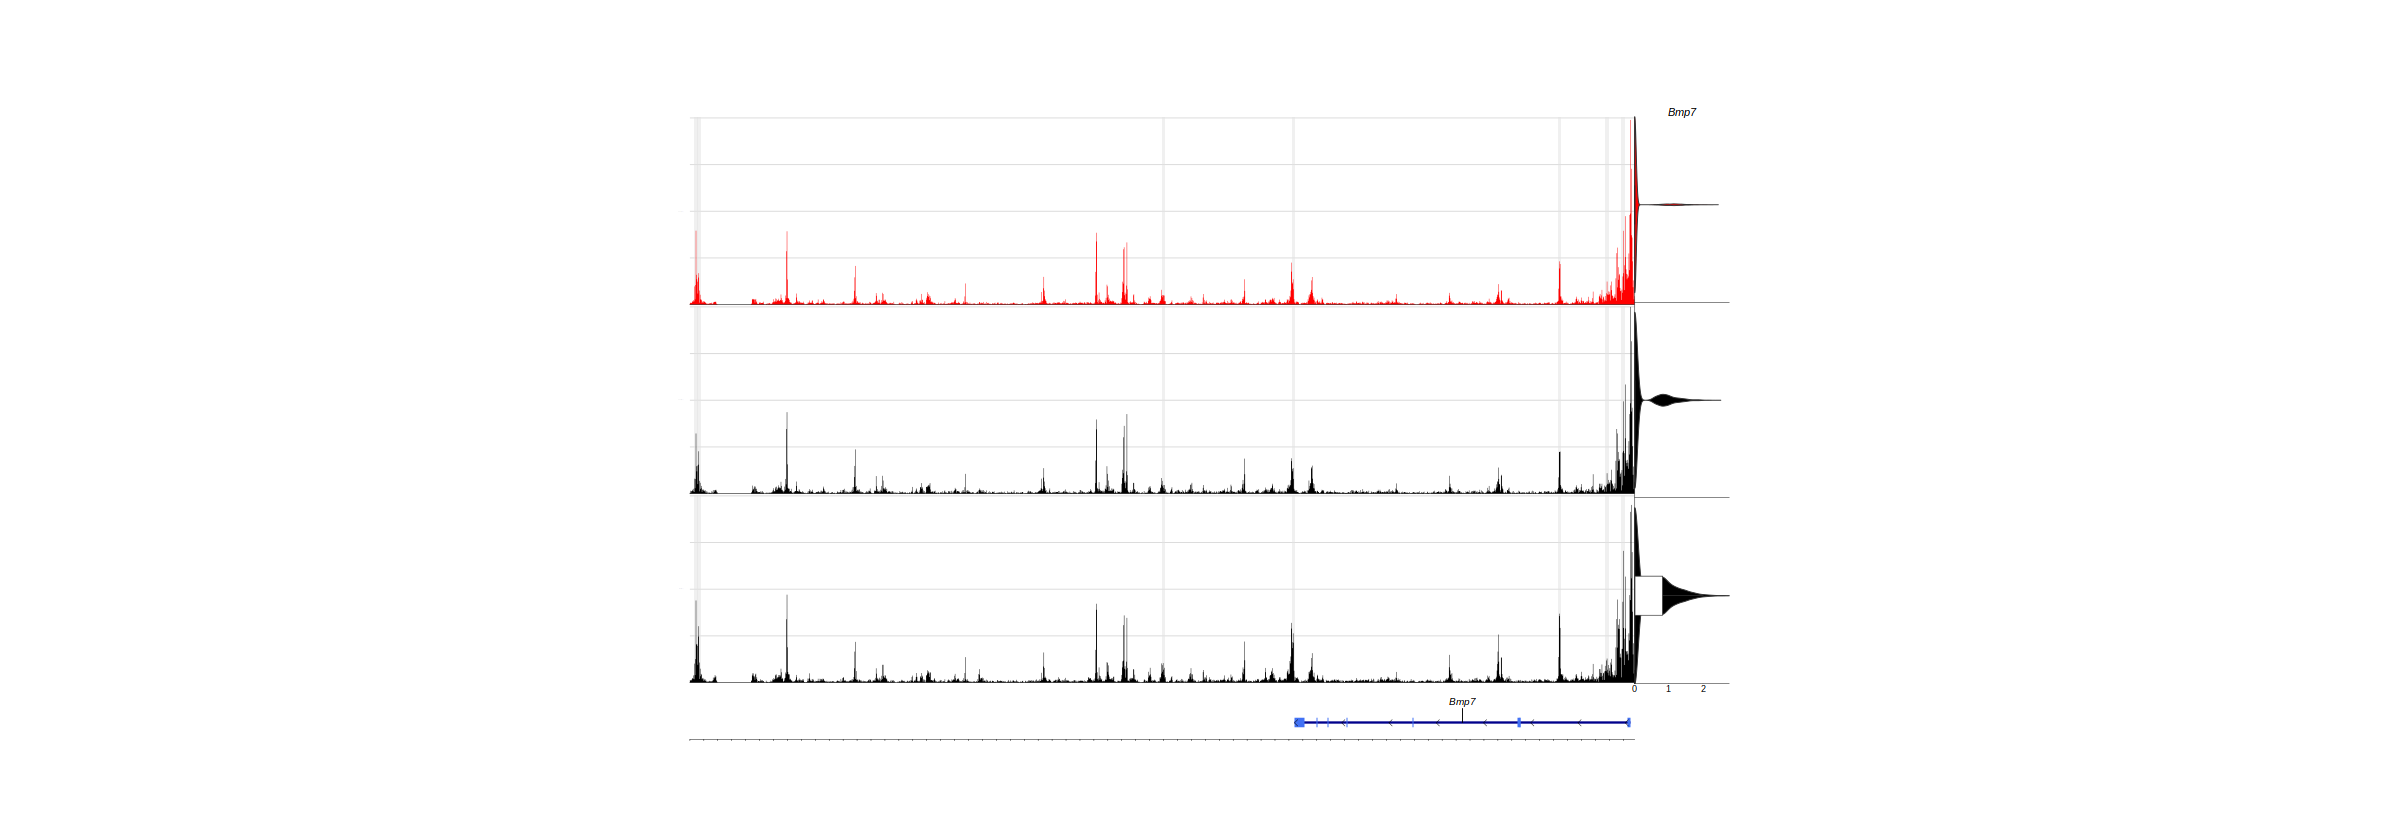

In [121]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Bmp7', extend.upstream = 1e3, extend.downstream = 1e3)

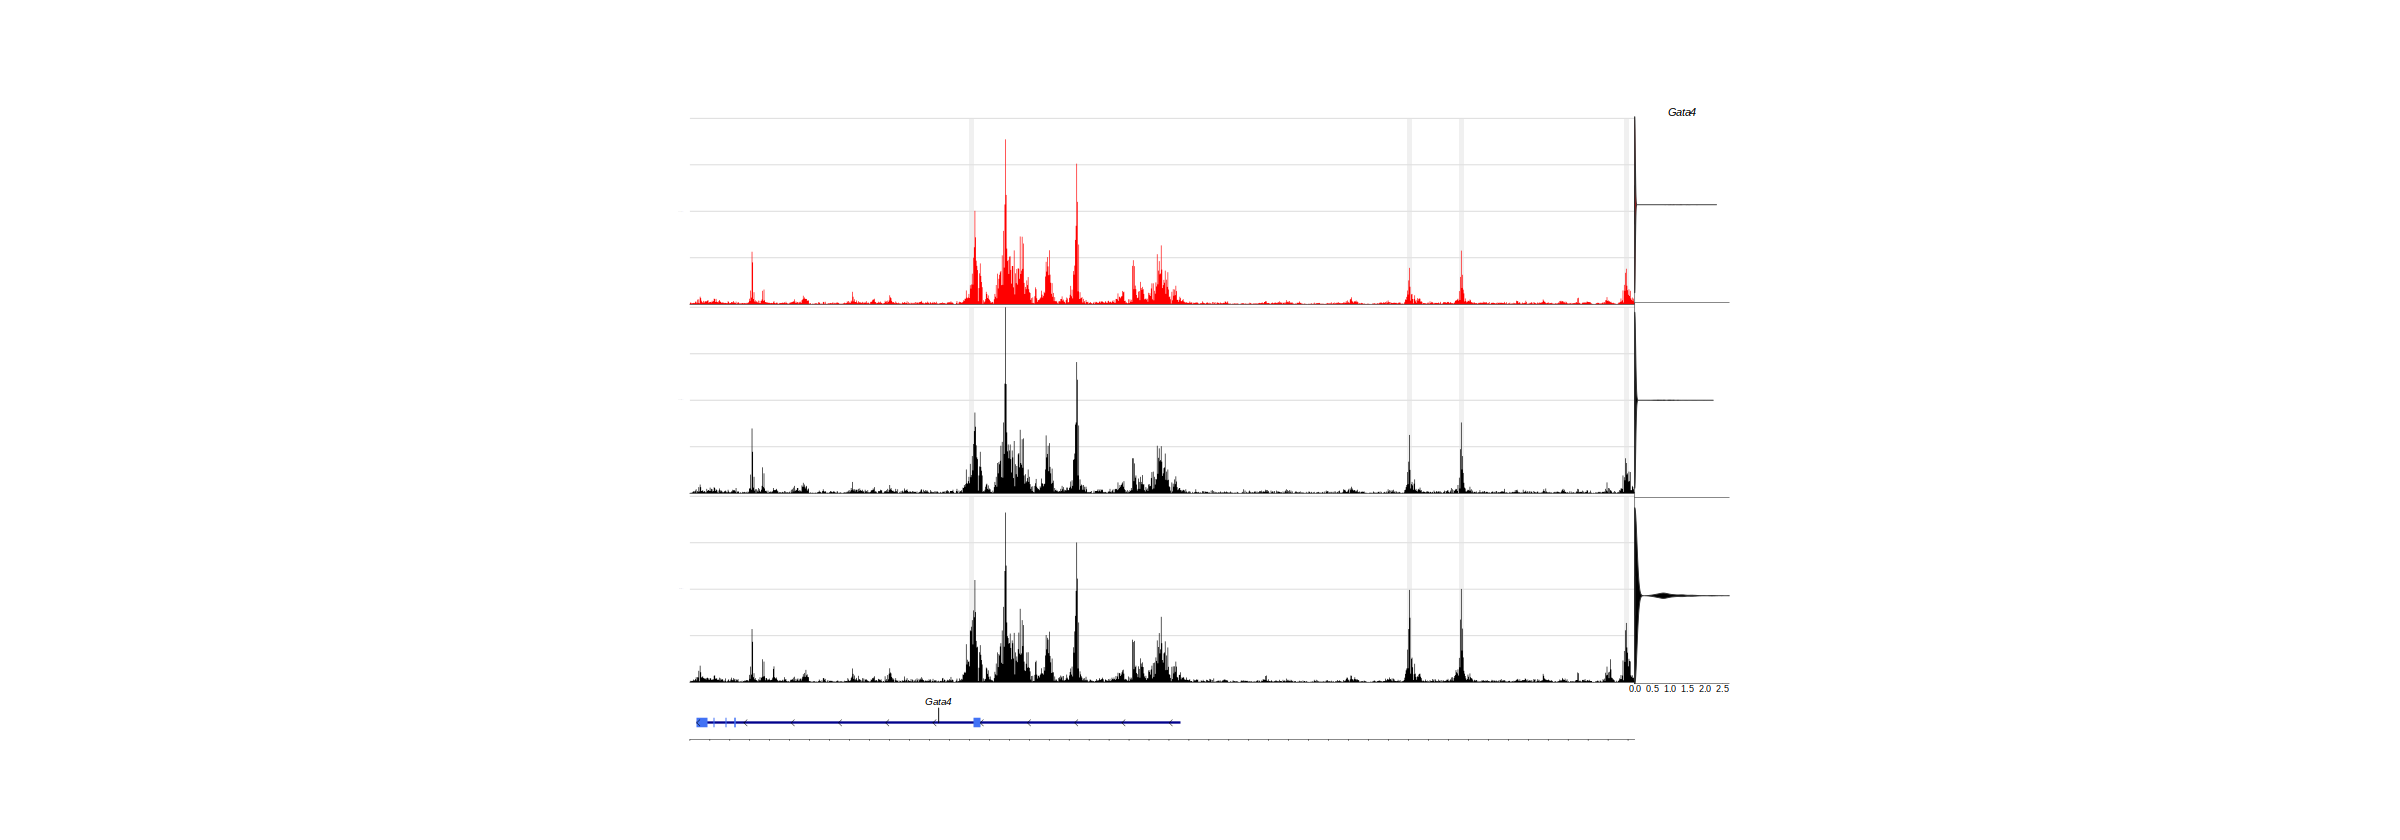

In [122]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Gata4', extend.upstream = 1e3, extend.downstream = 1e3)

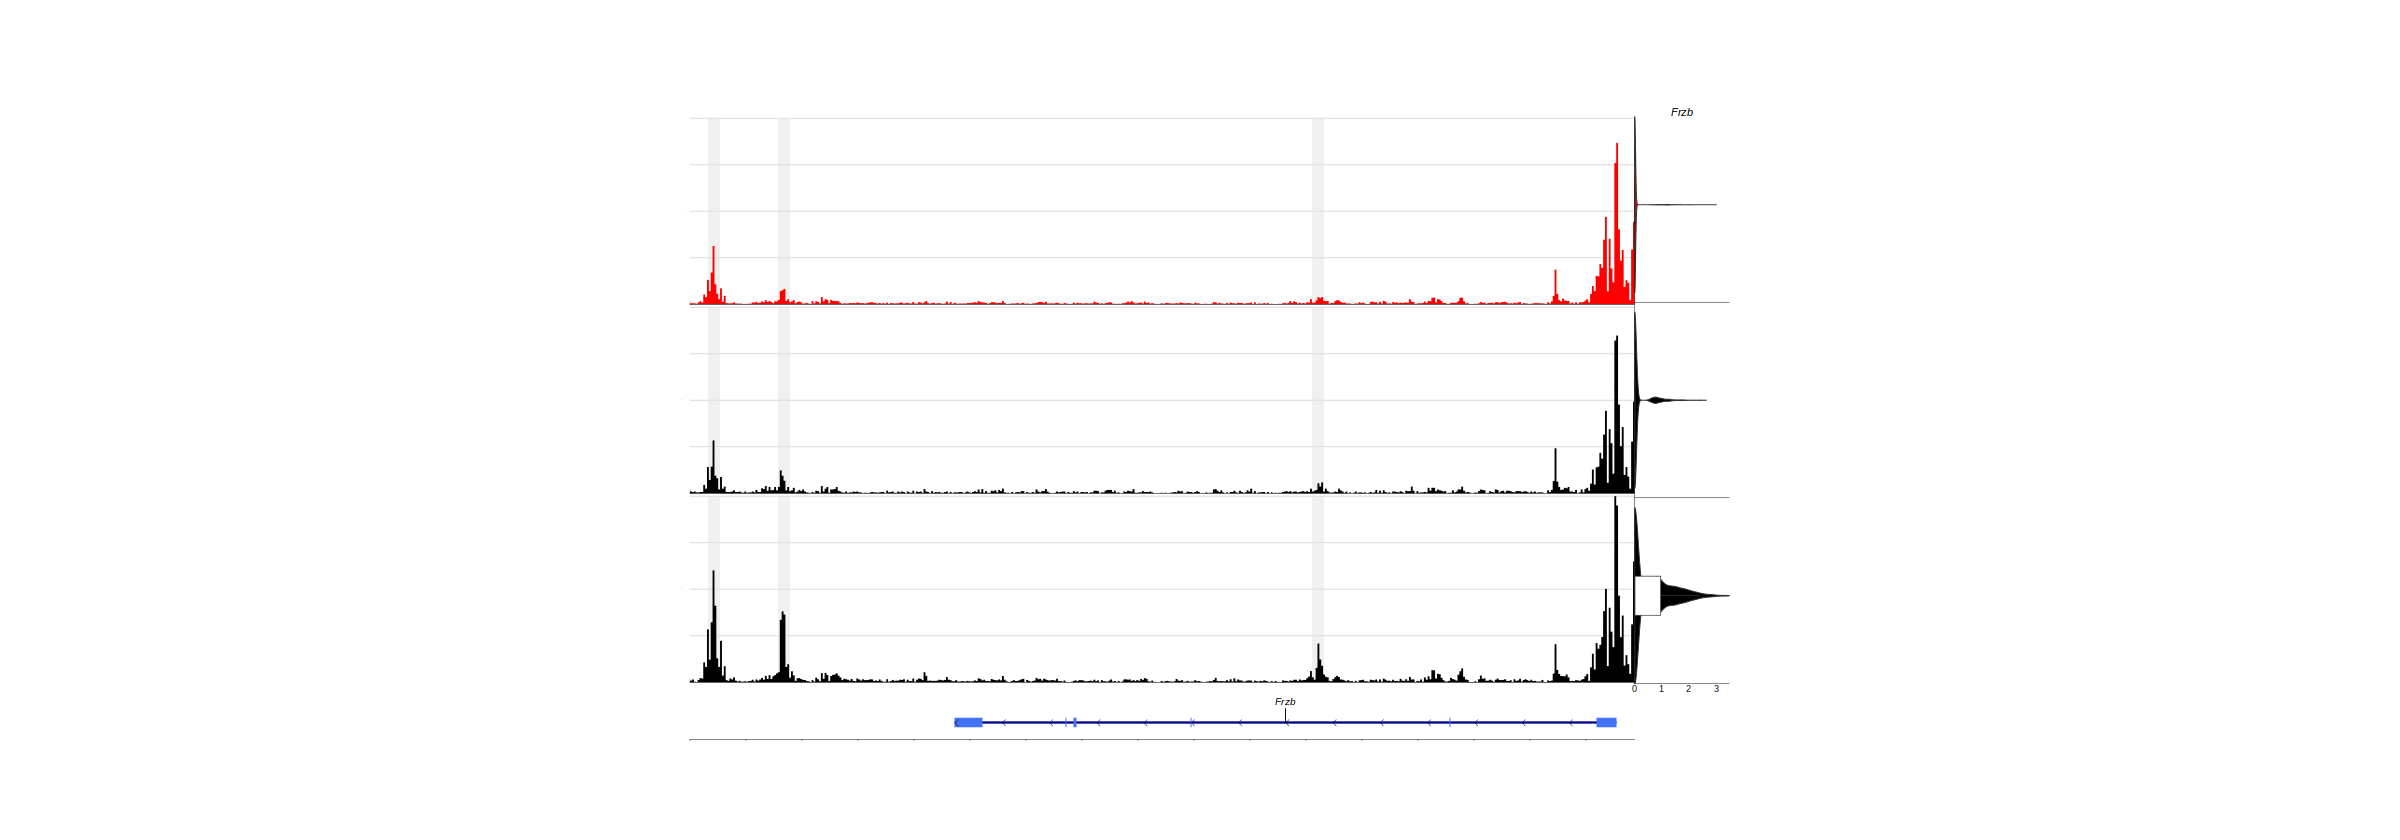

In [123]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Frzb', extend.upstream = 1e3, extend.downstream = 1e3)

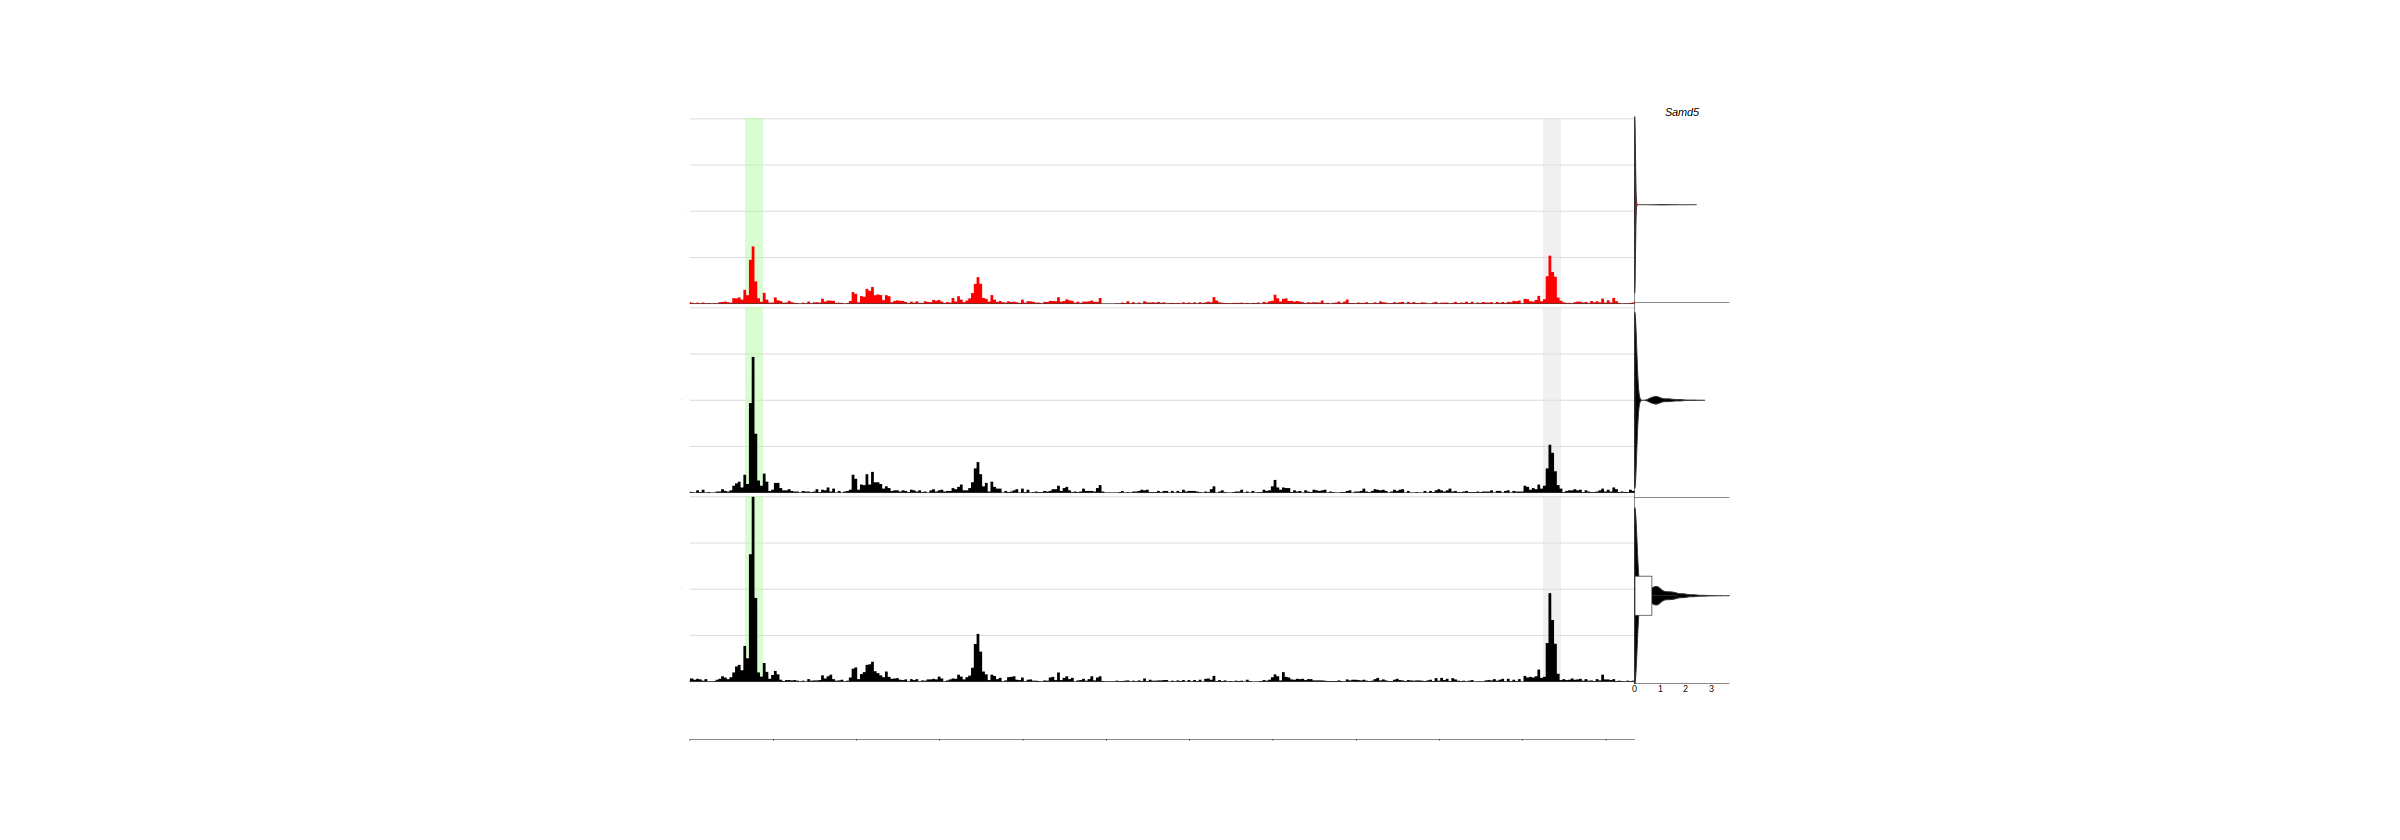

In [124]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Samd5', extend.upstream = -1.18e5, extend.downstream = 2e3)

In [125]:
enhancers = get_enhancers('Samd5', extend.upstream = -1.18e5, extend.downstream = 2e3)
enhancers

peak,gene,gene_strt,gene_end,chr,start,end,WT_WT_logFC,WT_WT_sign,WT_KD_logFC,WT_KD_sign,sign,meanlogFC
<chr>,<chr>,<dbl>,<dbl>,<chr>,<int>,<int>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<dbl>
chr10:9525175-9525775,Samd5,9627259,9675208,chr10,9525175,9525775,0.4226384,pos,-1.14232123,neg,both,0.7824798
chr10:9553925-9554525,Samd5,9627259,9675208,chr10,9553925,9554525,0.6658460,pos,-0.03303316,nonsig,WT_WT,0.3494396


In [126]:
matrix = as.matrix(matches[enhancers[[1]][, peak],
                           grep('EOMES|^TCF|LEF', colnames(matches))]@assays@data$matches)
matrix <- matrix * 1
matrix

,Tcfe3_17,Tcf3_31,Tcfeb_41,Tcfec_53,Tcf12_59,Tcfl5_71,Tcf21_79,Tcf4_88,Tcf15_93,Tcfcp2_389,Tcfcp2l1_391,Tcf7_726,Tcf7l2_732,Lef1_734,Tcf7l1_744,Eomes_768
chr10:9525175-9525775,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0
chr10:9553925-9554525,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0


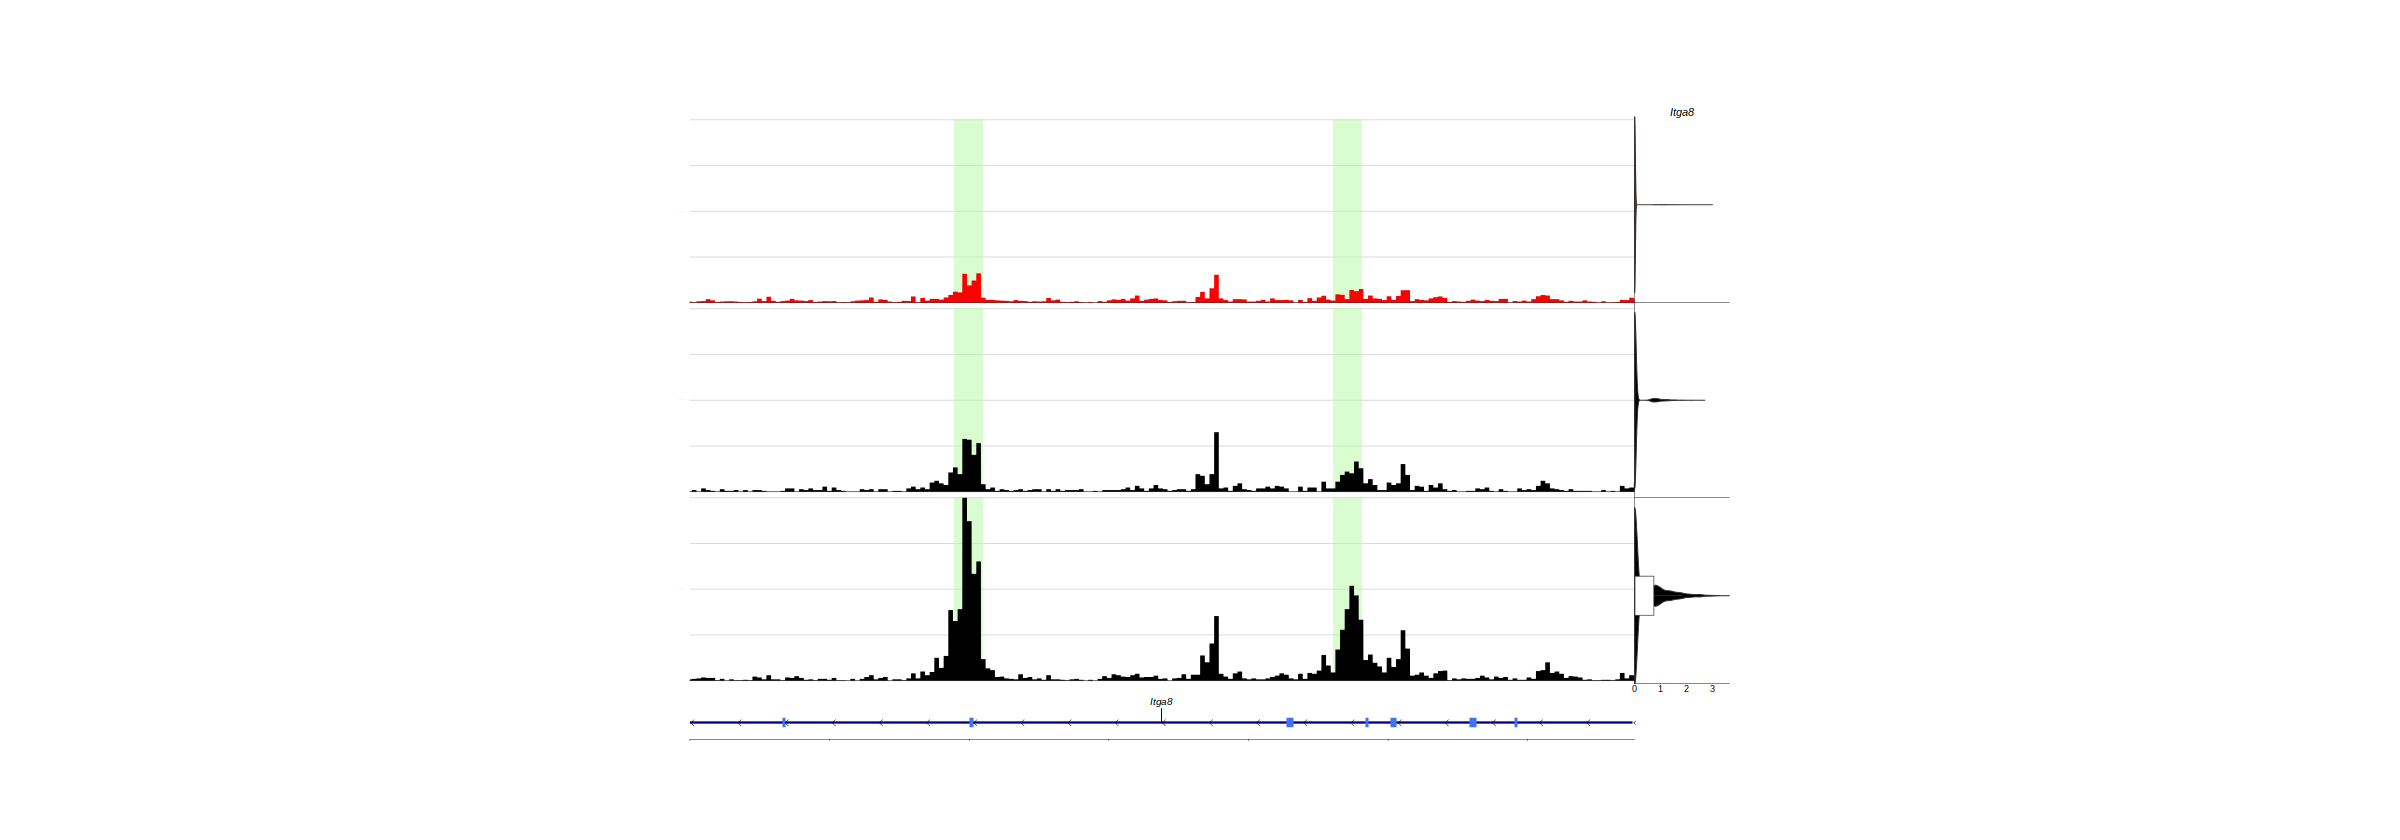

In [127]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Itga8', extend.upstream = -1.05e5, extend.downstream = -7e4)

In [128]:
enhancers = get_enhancers('Itga8', extend.upstream = -1.05e5, extend.downstream = -7e4)
enhancers

peak,gene,gene_strt,gene_end,chr,start,end,WT_WT_logFC,WT_WT_sign,WT_KD_logFC,WT_KD_sign,sign,meanlogFC
<chr>,<chr>,<dbl>,<dbl>,<chr>,<int>,<int>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<dbl>
chr2:12182330-12182930,Itga8,12106660,12301920,chr2,12182330,12182930,1.540746,pos,-0.8970517,neg,both,1.218899
chr2:12190451-12191051,Itga8,12106660,12301920,chr2,12190451,12191051,1.702535,pos,-1.0148285,neg,both,1.358682


In [129]:
matrix = as.matrix(matches[enhancers[[1]][, peak],
                           grep('EOMES|^TCF|LEF', colnames(matches))]@assays@data$matches)
matrix <- matrix * 1
matrix

,Tcfe3_17,Tcf3_31,Tcfeb_41,Tcfec_53,Tcf12_59,Tcfl5_71,Tcf21_79,Tcf4_88,Tcf15_93,Tcfcp2_389,Tcfcp2l1_391,Tcf7_726,Tcf7l2_732,Lef1_734,Tcf7l1_744,Eomes_768
chr2:12182330-12182930,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
chr2:12190451-12191051,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


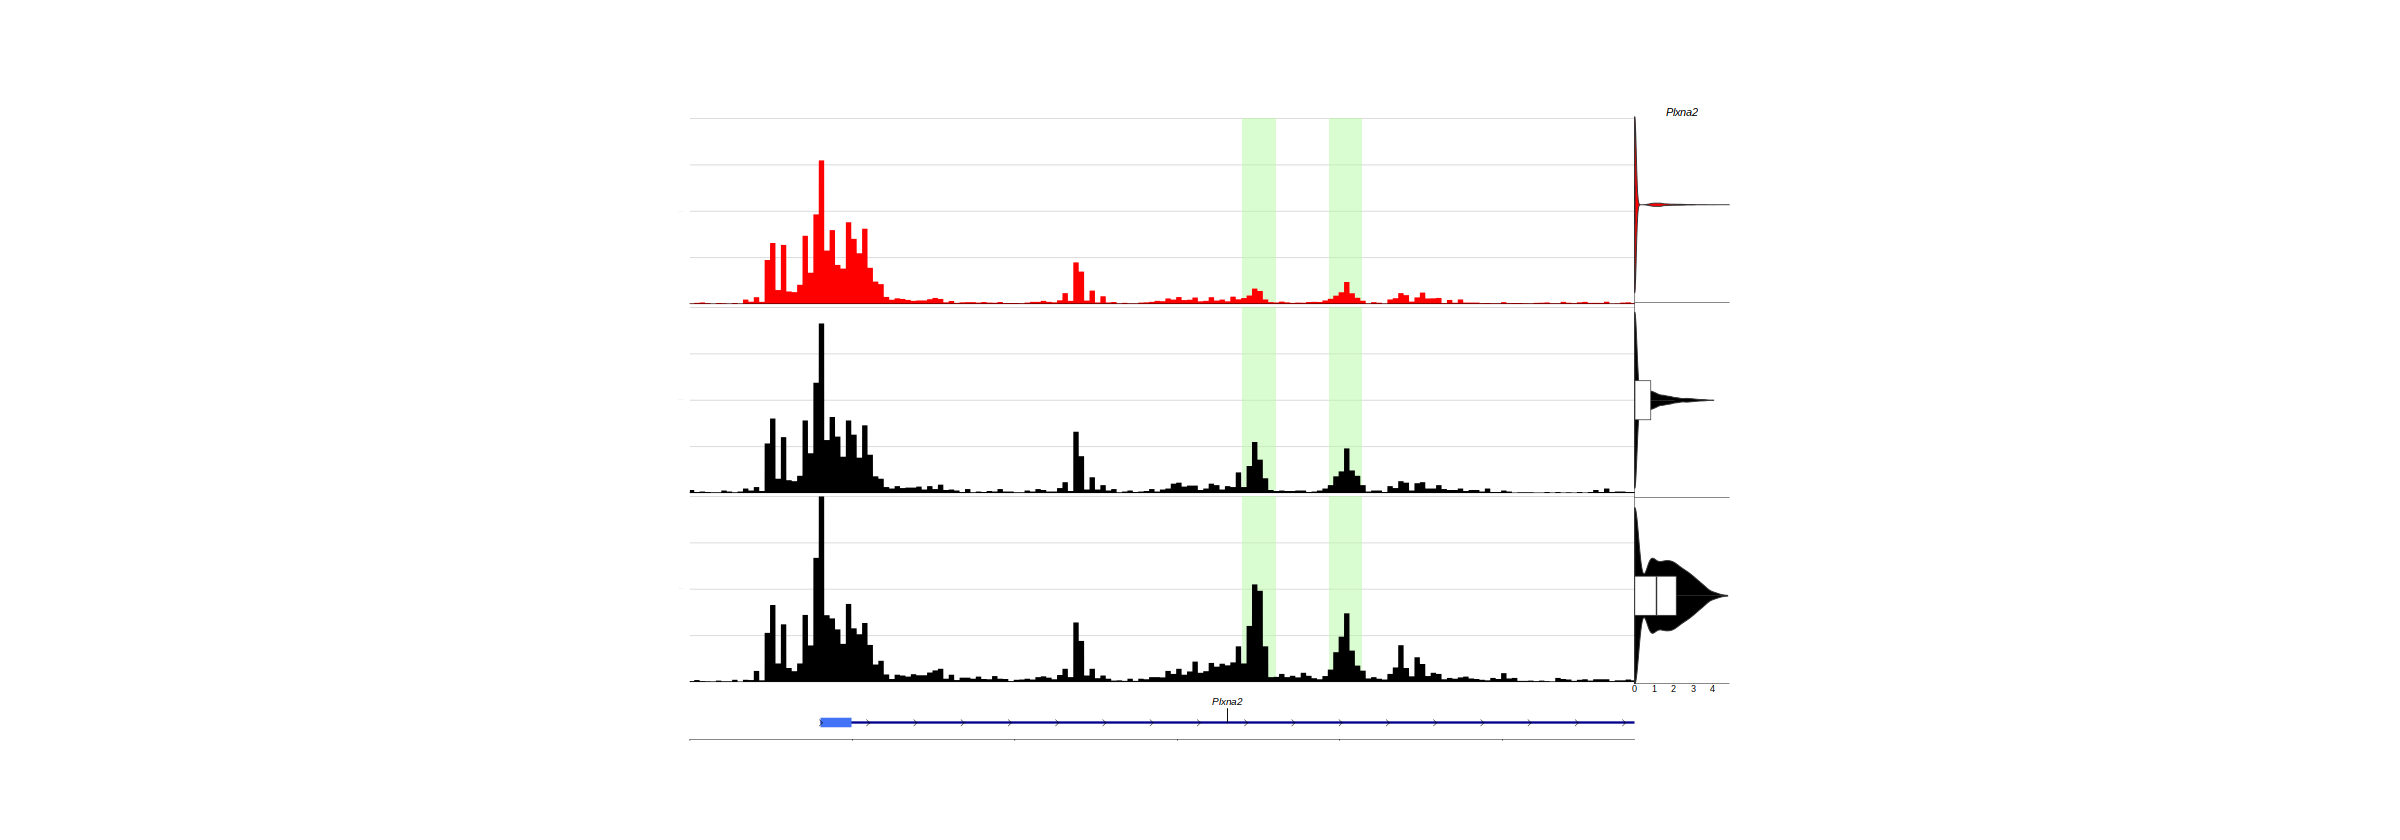

In [130]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Plxna2', extend.upstream = -1.82e5, extend.downstream = -1.14e5)

In [131]:
enhancers = get_enhancers('Plxna2', extend.upstream = -1.82e5, extend.downstream = -1.14e5)
enhancers

peak,gene,gene_strt,gene_end,chr,start,end,WT_WT_logFC,WT_WT_sign,WT_KD_logFC,WT_KD_sign,sign,meanlogFC
<chr>,<chr>,<dbl>,<dbl>,<chr>,<int>,<int>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<dbl>
chr1:194503421-194504021,Plxna2,194619829,194816869,chr1,194503421,194504021,0.3638170,nonsig,-1.0130007,neg,WT_KD,0.6884089
chr1:194610387-194610987,Plxna2,194619829,194816869,chr1,194610387,194610987,0.8885897,pos,-0.3252202,nonsig,WT_WT,0.6069049
chr1:194627627-194628227,Plxna2,194619829,194816869,chr1,194627627,194628227,1.0902108,pos,-1.4672869,neg,both,1.2787489
chr1:194629226-194629826,Plxna2,194619829,194816869,chr1,194629226,194629826,0.5949474,pos,-1.0052771,neg,both,0.8001123
chr1:194680211-194680811,Plxna2,194619829,194816869,chr1,194680211,194680811,0.7468773,pos,-0.2245202,nonsig,WT_WT,0.4856987


In [132]:
matrix = as.matrix(matches[enhancers[[1]][2:3, peak],
                           grep('EOMES|^TCF|LEF', colnames(matches))]@assays@data$matches)
matrix <- matrix * 1
matrix

,Tcfe3_17,Tcf3_31,Tcfeb_41,Tcfec_53,Tcf12_59,Tcfl5_71,Tcf21_79,Tcf4_88,Tcf15_93,Tcfcp2_389,Tcfcp2l1_391,Tcf7_726,Tcf7l2_732,Lef1_734,Tcf7l1_744,Eomes_768
chr1:194610387-194610987,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1
chr1:194627627-194628227,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,1


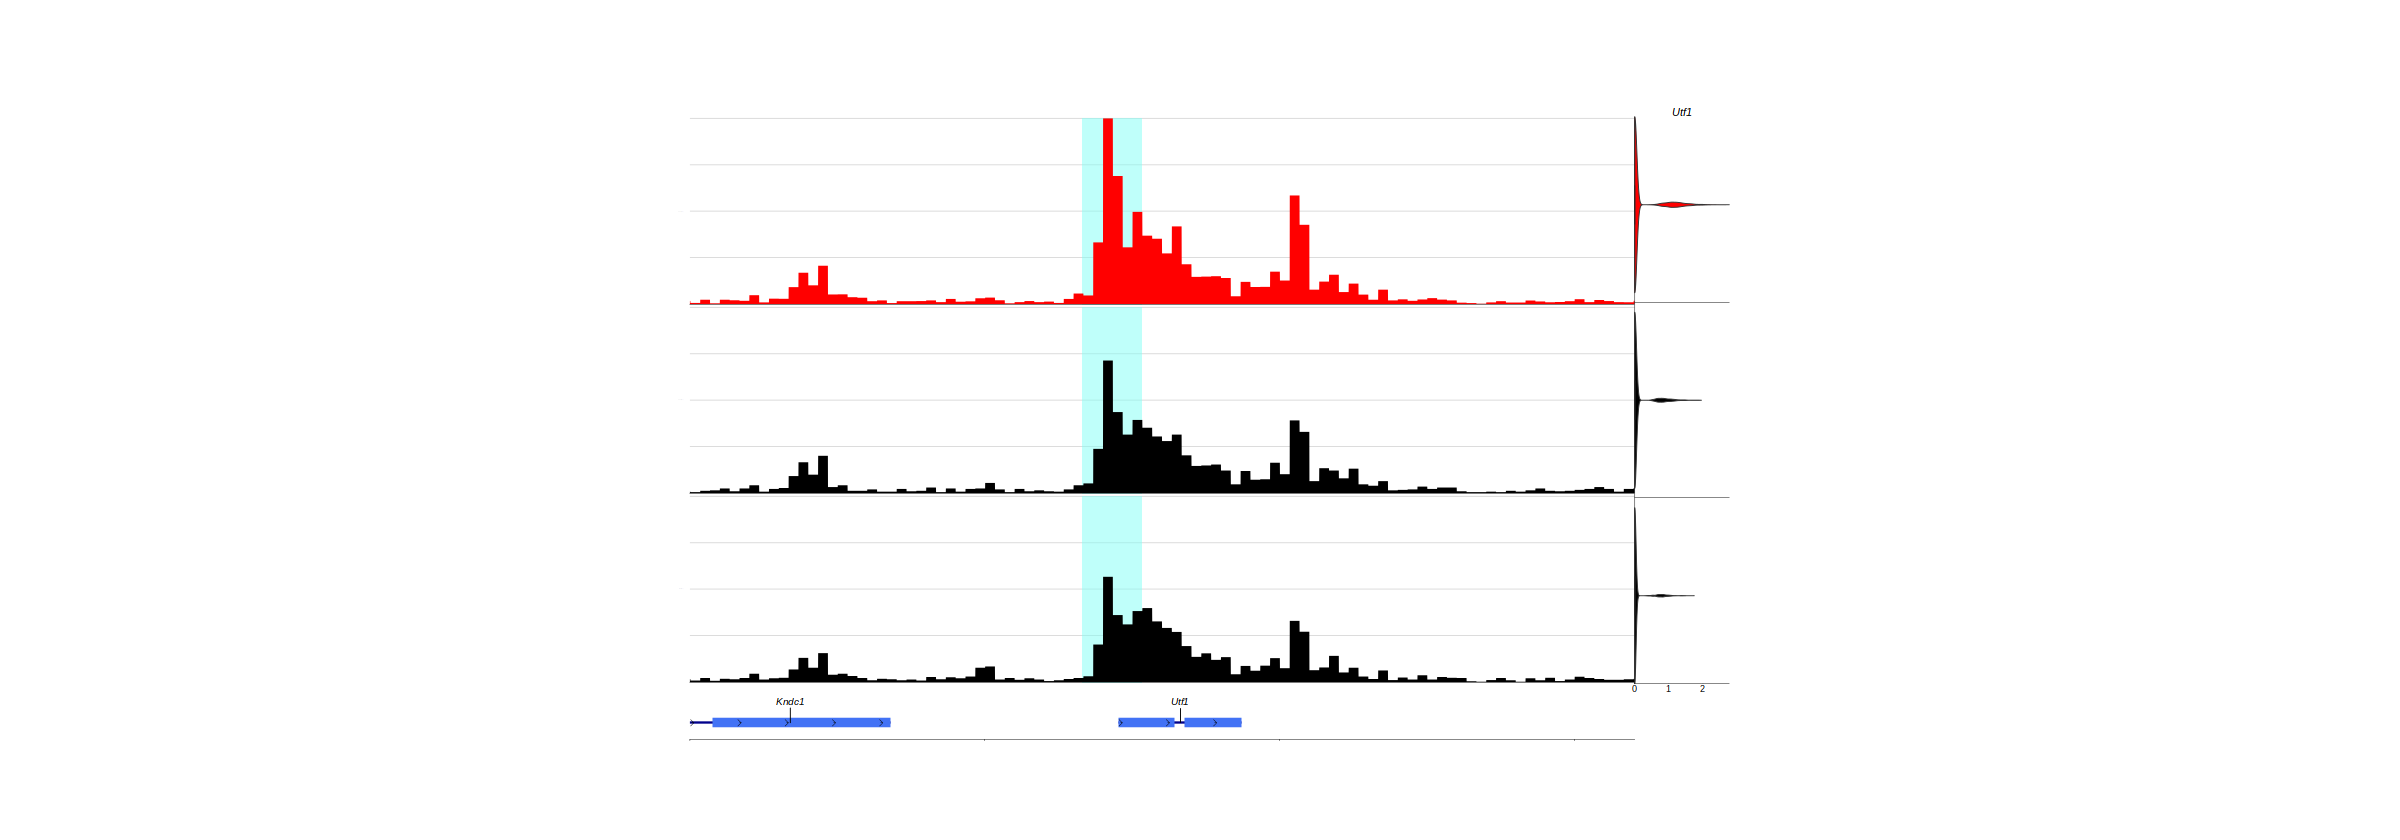

In [133]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Utf1', extend.upstream = 4e3, extend.downstream = 4e3)

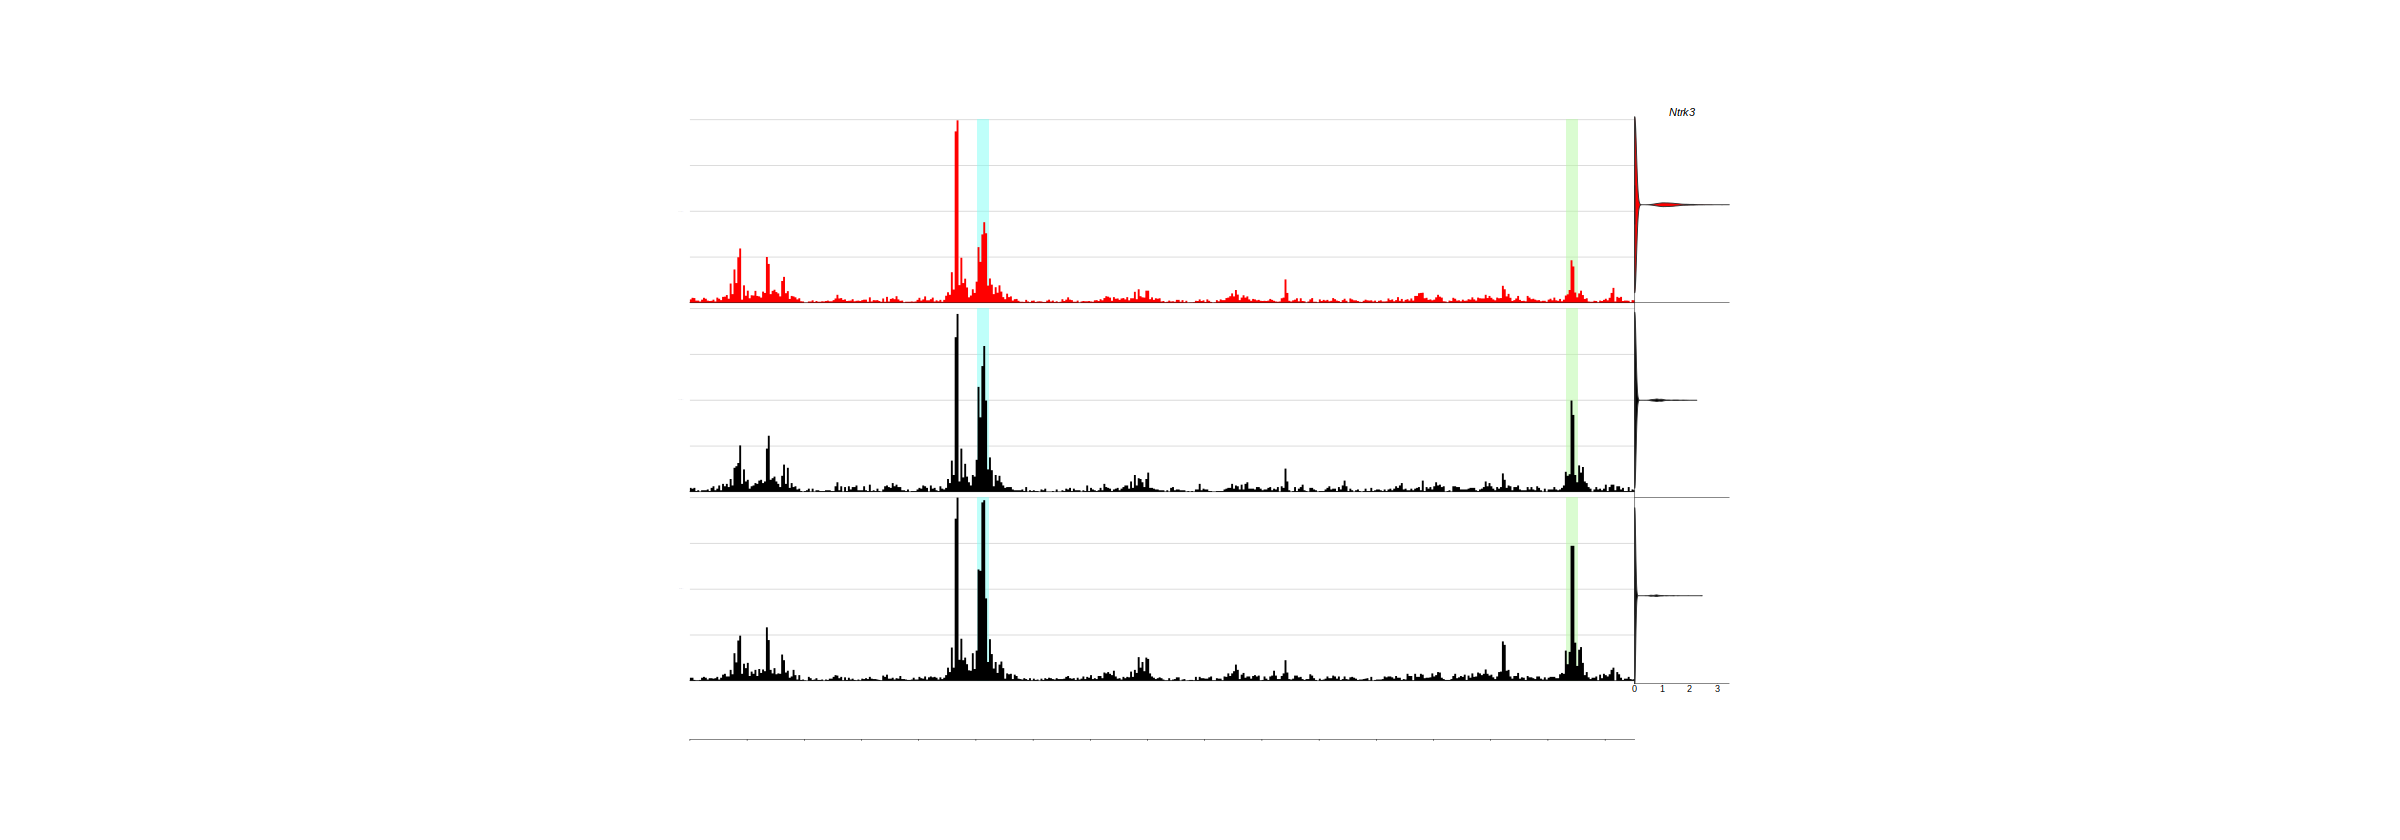

In [134]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Ntrk3', extend.upstream = 3e3, extend.downstream = -3.9e5)

In [135]:
enhancers = get_enhancers('Ntrk3', extend.upstream = 3e3, extend.downstream = -3.9e5)
enhancers

peak,gene,gene_strt,gene_end,chr,start,end,WT_WT_logFC,WT_WT_sign,WT_KD_logFC,WT_KD_sign,sign,meanlogFC
<chr>,<chr>,<dbl>,<dbl>,<chr>,<int>,<int>,<dbl>,<chr>,<dbl>,<chr>,<chr>,<dbl>
chr7:78597181-78597781,Ntrk3,78192114,78577838,chr7,78597181,78597781,0.1943136,nonsig,-0.7689226,neg,WT_KD,0.4816181
chr7:78628069-78628669,Ntrk3,78192114,78577838,chr7,78628069,78628669,0.6643912,pos,-0.9524027,neg,both,0.8083970


In [136]:
matrix = as.matrix(matches[enhancers[[1]][, peak],
                           grep('EOMES|^TCF|LEF', colnames(matches))]@assays@data$matches)
matrix <- matrix * 1
matrix

,Tcfe3_17,Tcf3_31,Tcfeb_41,Tcfec_53,Tcf12_59,Tcfl5_71,Tcf21_79,Tcf4_88,Tcf15_93,Tcfcp2_389,Tcfcp2l1_391,Tcf7_726,Tcf7l2_732,Lef1_734,Tcf7l1_744,Eomes_768
chr7:78597181-78597781,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0
chr7:78628069-78628669,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


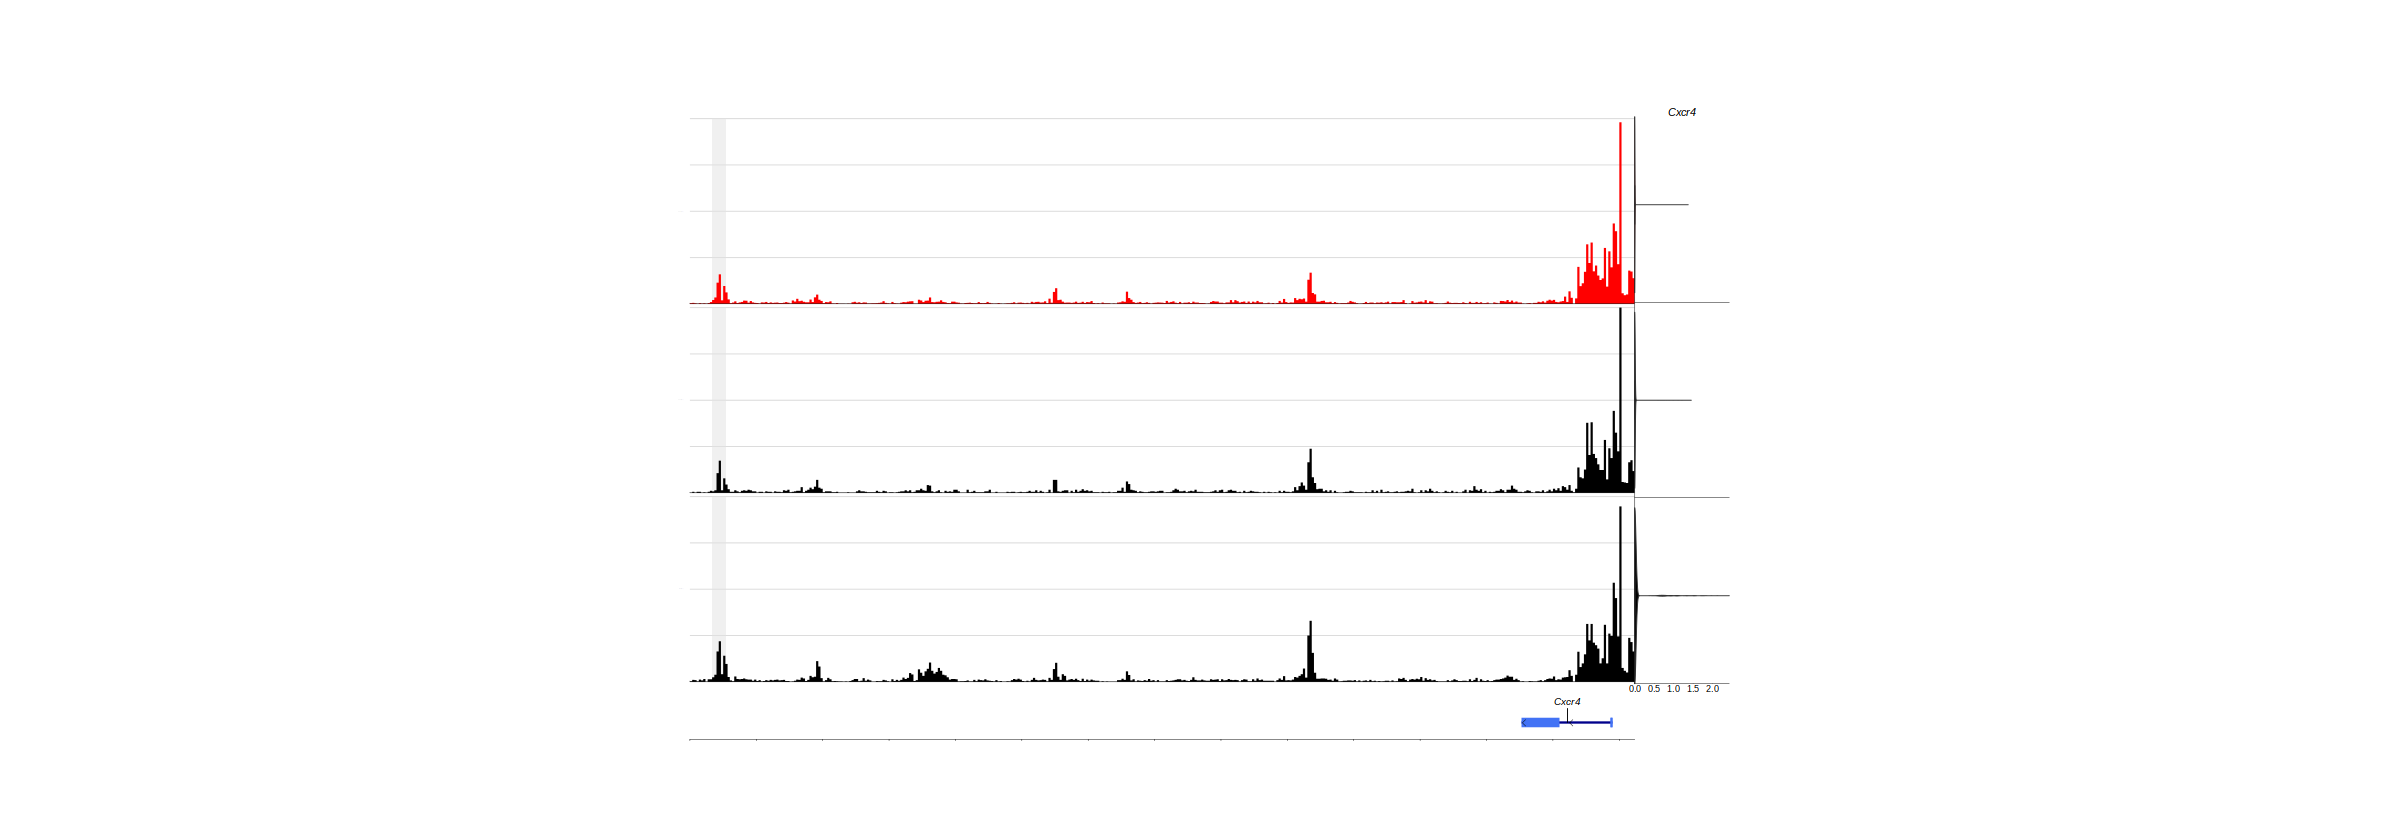

In [137]:
plot_gene_bigwig('Cxcr4')

In [138]:
gene_list <- c(
  "Foxa2", "Adamts9", "Sox17", "Gsc", "Lhx1", "Chrd", "Mixl1", 
  "Noto", "Shh", "Fgf8", "T", "Eomes", "Dkk1", "Lefty1", 
  "Foxj1", "Cxcr4", "Snai1"
)

pdf(file.path(args$outdir, "browser_tracks.pdf"), width = 15, height = 6)
invisible(lapply(gene_list, function(g) print(plot_gene_bigwig(g))))
dev.off()

png 
  2

In [139]:
plot_gene_bigwig

function(gene_in, extend.upstream = 1e3, extend.downstream = 1e3){
    DARs = comparison
    peaks = links[gene %in% gene_in & peak %in% DARs[sign != 'nonsig']$gene,] %>%
        merge(., DARs, by.x = 'peak', by.y = 'gene')
    region = paste0(peaks$chr[1], ':', min(c(peaks$start, peaks$gene_strt)) - extend.downstream, '-', max(peaks$end, peaks$gene_end) + extend.upstream)

    highlight_colors = ifelse(peaks$sign == 'both', "#b8fca4", 
                              ifelse(peaks$sign == 'WT_KD', "#80fff9",
                                    'grey90'))
    names(highlight_colors) = str_split(str_split(peaks[, peak], ':') %>% map_chr(2), '-') %>% map_chr(1)
    
    p1 = plot_browser_track(gene = gene_in, # Only choose one of gene/input_region, otherwise will use region
                              input_region = region, #'chr10:101890817-101891317', 
                              WT_plot, 
                              plot_expression = T,
                              sce = rna.sce_filt,
                              extend.upstream = 0,
                              extend.downstream = 0, 
                              highlight_regions = peaks$peak,
                              downsample.rate = 1, 
                              no_label = T, 
                              background_color = 'white',
                              highlight_color = highlight_colors,
                              bw_height = 40, 
                              gene_height = 10, 
                              bw_width = 200,
                              expr_width = 20)
    return(p1)
    }
<bytecode: 0x563e2cfb9398>

In [157]:
# Plotting of browser tracks from bigwigs
plot_browser_track = function(gene = NULL, # Only choose one of gene/input_region, otherwise will use region
                              input_region = NULL, 
                              bigwigs, 
                              plot_expression = F,
                              sce = rna.sce,
                              extend.upstream = 0,
                              extend.downstream = 0, 
                              highlight_regions = NULL,
                              downsample.rate = 1, 
                              no_label = F, 
                              background_color = 'white',
                              highlight_color = 'grey95',
                              bw_height = 2, 
                              gene_height = 1.5, 
                              bw_width = 20,
                              expr_width = 4.5){
    
    
    # x-axis labels function 
    alternate_labels <- function(x) {
      ifelse(seq_along(x) %% 2 == 0, paste("\n", x), x)
    }
    
    if(!is.null(gene)){
        # Get region around gene
        region = ArchRProject@geneAnnotation$genes[grep(paste0('^', gene, '$'), ArchRProject@geneAnnotation$genes$symbol)]
        start(ranges(region)) = start(ranges(region)) - extend.upstream
        end(ranges(region)) = end(ranges(region)) + extend.downstream
        gr <- GRanges(c(seqnames(region)), IRanges(start=start(ranges(region)), end=end(ranges(region))), strand='+')
    }
    if(!is.null(input_region)){
        # Get supplied region as Granges
        gr <- GRanges(c(str_split(input_region, ':') %>% map_chr(1)), 
                      IRanges(start=as.numeric(str_split(str_split(input_region, ':') %>% map_chr(2), '-') %>% map_chr(1)) - extend.upstream, 
                              end=as.numeric(str_split(str_split(input_region, ':') %>% map_chr(2), '-') %>% map_chr(2)) + extend.downstream), 
                        strand='+')
    }
    
    # Get bigwig info
    bw_list = lapply(bigwigs$path, function(x)return(x))
    names(bw_list) = bigwigs$name
    bigwigs.colors = bigwigs$color
    names(bigwigs.colors) = bigwigs$name
                     
    coverages = mclapply(names(bw_list), function(x){
        region_data <- as.data.table(rtracklayer::import(con = bw_list[[x]], 
                    which = gr))
        region_data = rbind(region_data, region_data %>% copy() %>% .[,start:=end]) %>% 
            .[order(start)] %>% 
            .[,c('start', 'score')] %>% 
            .[, bw := names(bw_list[x])]
            # .[, bw := factor(names(bw_list[x]), levels = names(bw_list[x]))] 
        return(region_data)
    }, mc.cores = max(1,detectCores()-2)) %>% rbindlist() %>%
        .[, bw := factor(bw, levels = names(bw_list))] %>% .[order(bw)]
                     
    if(downsample.rate != 1){
        coverages = coverages[start %in% sample(start, nrow(coverages)*downsample.rate)]
    }
                     
    p1 =  ggplot(data = coverages, mapping = aes_string(x = "start", y = "score", fill = "bw")) + 
                     geom_area(color = 'black', linewidth = 0) + 
                     # geom_area() +
                     facet_wrap(facets = ~factor(bw, levels = names(bw_list)), 
                            strip.position = "left", ncol = 1) +
        # ggtitle(label = paste0(seqnames(gr)),
        #     subtitle = paste0(ranges(gr))) + #, ':', ranges(gr))) + 
        geom_hline(yintercept = 0, color='black', linewidth = 0.1) +
        geom_segment(data = as.data.table(gr)[,bw:=bigwigs[1,name]], # Add background segment to make sure x-axis is correct
            mapping = aes(x = start, y = 0, xend = end, yend = 0), color = 'white', alpha=0) +
        scale_x_continuous(expand=c(0,0)) + 
        scale_y_continuous(expand=c(0,0.005), breaks = seq(min(coverages$score), max(coverages$score), length.out = 5)) +
        Signac::theme_browser(axis.text.y = TRUE) + 
        theme(axis.text.y = element_blank(),
                panel.grid.minor = element_blank(),
              panel.grid.major.y =  element_line(color = "grey85", linewidth = 0.2),
              panel.grid.major.x = element_blank(),
                strip.text.y = element_text(hjust=1, color='black', size = 6, vjust=0.5),
                axis.line = element_blank(),
                axis.line.x = element_blank(),
                axis.text.x = element_blank(),
                axis.ticks = element_blank(), 
                axis.title = element_blank(),
                legend.position = 'none',
                plot.title = element_text(size = 7, hjust=0.5, vjust = -0.5, face='plain'),
                plot.subtitle = element_text(size = 5, hjust=0.5, face='plain'),
                panel.background = element_rect(fill=background_color),
                panel.spacing = unit(0, "lines"),
                plot.margin = margin(0,0,0,0)) 
    
    # Remove y-text if needed
    if(no_label){
        p1 = p1 + theme(strip.text.y = element_text(size = 0), 
                        strip.background = element_blank(),
                        plot.margin = unit(c(0,0,0,0), units = "lines")) 
    }
    
    # Add Highlights
    if(!is.null(highlight_regions)){
        # Keep only highlights in the display range
        highlights = GRanges(c(str_split(highlight_regions, ':') %>% map_chr(1)), 
                      IRanges(start=as.numeric(str_split(str_split(highlight_regions, ':') %>% map_chr(2), '-') %>% map_chr(1)), 
                              end=as.numeric(str_split(str_split(highlight_regions, ':') %>% map_chr(2), '-') %>% map_chr(2))), 
                        strand='+')
        
        highlight_in_region = findOverlaps(highlights, gr, ignore.strand = T, type = 'within')
        highlight_regions = highlight_regions[queryHits(highlight_in_region)]
        
        # Add highlight display
        if(length(highlight_regions) > 0){ # Only if there is any overlap
            highlights.dt = data.table(start = as.numeric(str_split(str_split(highlight_regions, ':') %>% map_chr(2), '-') %>% map_chr(1)),
                                       end = as.numeric(str_split(str_split(highlight_regions, ':') %>% map_chr(2), '-') %>% map_chr(2))) %>% 
                            .[, .(start, end, vector_column = rep(unique(p1$data$bw), each = 1)), by = .(row_index = 1:nrow(.))] %>% 
                            .[, position := start] %>% .[,score := 0]
            
            if(length(highlight_color) == 1){
                highlight_color = rep(highlight_color, length(highlight_regions))
                names(highlight_color) = as.character(unique(highlights.dt$start))
            }
            
            colors = c(bigwigs$color, as.character(highlight_color))
            names(colors) = c(as.character(bigwigs$name), names(highlight_color))

            p1 = p1 + 
                geom_rect(data = highlights.dt, aes(xmin=start, xmax=end, ymin=0, ymax=max(p1$data$score), fill = as.character(start)), 
                                    color=NA, alpha=0.2) +
                scale_fill_manual(values = colors) 
            # Change layers around so highlight is behind bigwig
            p1$layers = list(p1$layers[[3]], p1$layers[[4]], p1$layers[[1]], p1$layer[[2]])
        }
    }else{ p1 = p1 + scale_fill_manual(values = bigwigs.colors)}

    # Get genome annotation
    annotation.genes = ArchRProject@geneAnnotation$genes 
    annotation.genes = annotation.genes[grep("^Rik|Rik$|^Gm|^Mir", annotation.genes$symbol, invert=T)] # remove uninformative genes from plotting
 
    annotation.exons = ArchRProject@geneAnnotation$exons
    annotation.exons = annotation.exons[grep("^Rik|Rik$|^Gm|^Mir", annotation.exons$symbol, invert=T)]
    
    # Search for genes within region
    tmp1 = findOverlaps(gr, annotation.genes, ignore.strand = T)
    tmp2 = findOverlaps(gr, annotation.exons, ignore.strand = T)
    
    # Add gene track if there are any genes in the window
    if(length(subjectHits(tmp1)) > 0){
        # get overlap among genes
        overlap = as.data.table(findOverlaps(annotation.genes[subjectHits(tmp1)], annotation.genes[subjectHits(tmp1)], type = 'any', ignore.strand = T))

        # check if genes overlap, and if so move different rows
        solver = list()
        for(x in unique(overlap$queryHits)){
            overlaps = overlap[queryHits==x & subjectHits <= x]
            nr_overlaps = nrow(overlaps)
        # No overlap --> Row = 0
            if(nr_overlaps == 1){
                rows = 1
        # 1 overlap --> check which row it was on
            }else{
               rows = setdiff(1:10, rbindlist(solver[overlaps$subjectHits])$row)[1]
            }
        #If overlap is after, do nothing
            solver[[x]] = data.table(queryHits = x,
                                     row = rows)
        }
        solved = rbindlist(solver)

        # keep overlapping genes/exons
        tmp1 = as.data.table(annotation.genes[subjectHits(tmp1)]) %>% 
            .[,row := solved$row] %>% .[width>200] # remove super short genes

        tmp2 = as.data.table(annotation.exons[subjectHits(tmp2)]) %>% 
            merge(., tmp1[,c('symbol', 'row')], by='symbol') # Add rown information

        # Cutoff genes/exon if they fall outside of the range
        tmp1 = tmp1 %>% 
            .[, `:=`(start = ifelse(start <= start(ranges(gr)), start(ranges(gr)), start),
                     end = ifelse(end >= end(ranges(gr)), end(ranges(gr)), end))]

        tmp2 = tmp2 %>% 
            .[, `:=`(start = ifelse(start <= start(ranges(gr)), start(ranges(gr)), start),
                     end = ifelse(end >= end(ranges(gr)), end(ranges(gr)), end))] %>% unique()

        # Add Arrows to indicate orientation
        width = end(ranges(gr)) - start(ranges(gr))

        tmp3 = lapply(1:nrow(tmp1), function(x){
            tmp = tmp1[x,]
            tmpp = data.table(
                          start = seq(tmp$start + 20, tmp$end + 20, by = width/20),
                          end = seq(tmp$start + 40, tmp$end + 40, by = width/20),
                          symbol = tmp$symbol,
                          row = tmp$row)
            return(tmpp)
        }) %>% rbindlist()


        # Plot gene track 
        p = ggplot() + # rbind(tmp1, tmp1 %>% copy() %>% .[,row:=row+1]), aes(start, row)
            geom_segment(data = as.data.table(gr), # Add background segment to make sure x-axis is correct
                         mapping = aes(x = start, y = 1, xend = end, yend = 1), color = 'white') +
            geom_segment(data = tmp1, 
                mapping = aes(x = start, y = row, 
                xend = end, yend = row), color = 'darkblue', show.legend = FALSE, linewidth = unit(0.5, 'mm')) +
            geom_segment(data = tmp2, 
                mapping = aes(x = start, y = row, 
                xend = end, yend = row), color = '#4272f5', show.legend = FALSE, linewidth = unit(2, 'mm')) + 
        for(i in 1:nrow(tmp1)){
            tmp = tmp1[i,]
            if(as.character(tmp$strand) == '+'){
                p = p + geom_segment(data = tmp3[symbol == tmp$symbol], 
                        mapping = aes(x = start, y = row, 
                xend = end, yend = row), arrow = arrow(ends = "last", 
                        type = "open", angle = 45, length = unit(x = 1, 
                        units = "mm")), show.legend = FALSE, color='black', 
                        linewidth = 0.1)
               }else{
              p = p + geom_segment(data = tmp3[symbol == tmp$symbol], 
                        mapping = aes(x = start, y = row, 
                xend = end, yend = row), arrow = arrow(ends = "first", 
                        type = "open", angle = 45, length = unit(x = 1, 
                        units = "mm")), show.legend = FALSE, color='black', 
                        linewidth = 0.1)  
            }
        }


        p = p + 
            #xlim(start(ranges(gr)), end(ranges(gr))) + 
            ggrepel::geom_text_repel(data = tmp1, aes(label = symbol, x = end - (end - start)/2 , y = row), 
                                     fontface = "italic",
                                     size = 2,
                                     color = 'black', 
                                     direction = "y",
                                     force_pull   = 0, # do not pull toward data points
                                     nudge_y      = 1,
                                     segment.size = 0.2
                                    ) + 
            ylim(0.5, max(c(1, tmp1$row) + 1))

    }else{
        p = ggplot() + # rbind(tmp1, tmp1 %>% copy() %>% .[,row:=row+1]), aes(start, row)
            geom_segment(data = as.data.table(gr), # Add background segment to make sure x-axis is correct
                         mapping = aes(x = start, y = 1, xend = end, yend = 1), color = 'white') +
            ylim(0.5, 2)
        
        
        
    }
    p = p + 
        scale_x_continuous(expand = c(0,0), labels = alternate_labels, breaks = seq(start(ranges(gr)), end(ranges(gr)), 3000)) + # breaks = scales::pretty_breaks(n = 1))
        theme_void() + 
        theme( #axis.text.x = element_text(size=15, color='black', vjust=0.9),
               axis.ticks.x = element_line(color='black', linewidth=0.1), 
               axis.ticks.length.x = unit(0.3, 'mm'),
               axis.line.x = element_line(color='black', linewidth=0.1),
               plot.margin = margin(0,0,0,0) 
    )
    
    if(plot_expression == F){
        patchwork::wrap_plots(plotlist = list(p1, p), ncol = 1, heights = unit(c(nrow(bigwigs)*bw_height, gene_height), c('mm', 'mm')))
    }else{
        stopifnot(!is.null(gene))
        meta.plot = as.data.table(colData(sce)) %>% 
            .[,gene := as.vector(logcounts(sce[gene,]))] %>% 
            merge(., bigwigs, by = c('celltype')) %>% 
            .[,c('genotype', 'celltype', 'name', 'color', 'gene')]

        p2 = ggplot(meta.plot %>% copy(),
                        # .[,celltype_v2 := factor(celltype_v2, levels = rev(WT_plot$name))], 
                    aes(gene, name, fill = name)) + 
            geom_violin(scale = 'width',  size = 0.2) + 
            geom_boxplot(width=0.2, fill='white', linewidth = 0.15, outlier.shape=NA) + 
            scale_fill_manual(values = bigwigs.colors) + 
            scale_x_continuous(expand = c(0, 0)) + 
            scale_y_discrete(expand = c(0, 0), limits = rev(names(bw_list))) + 
            geom_hline(yintercept = seq(0.5, nrow(WT_plot), 1), linewidth = 0.1) + 
            ggtitle(gene) + 
            theme_void() + 
            theme(axis.text.x = element_text(size = 5, vjust = 0),
                  axis.line = element_line(linewidth = 0.1),
                  axis.ticks.x = element_line(linewidth=0.1, color = 'black'),
                  plot.title = element_text(size = 6, hjust=0.5, face = "italic"),
                  plot.subtitle = element_text(size = 7, hjust=0.5, face='plain'),
                  panel.background = element_rect(fill = background_color, color = NA),
                  plot.margin = margin(0,0,0,0),
                  legend.position = 'none')

        patchwork::wrap_plots(
          p1, p2, p, 
          ncol = 2, 
          widths = unit(c(bw_width, expr_width), c('mm', 'mm')), 
          heights = unit(c(nrow(bigwigs) * bw_height, gene_height), c('mm', 'mm'))
        ) + 
        patchwork::plot_annotation(
          title = paste0(seqnames(gr), ':', ranges(gr), ' (', round(width(gr)/1000, 1), 'kb)'),
          theme = ggplot2::theme(plot.title = ggplot2::element_text(size = 14, face = "bold", hjust = 0.5))
        )
    }
}
                     
plot_gene_bigwig = function(gene_in, extend.upstream = 1e3, extend.downstream = 1e3){
    DARs = comparison
    peaks = links[gene %in% gene_in & peak %in% DARs[sign != 'nonsig']$gene,] %>%
        merge(., DARs, by.x = 'peak', by.y = 'gene')
    region = paste0(peaks$chr[1], ':', min(c(peaks$start, peaks$gene_strt)) - extend.downstream, '-', max(peaks$end, peaks$gene_end) + extend.upstream)

    highlight_colors = ifelse(peaks$sign == 'both', "#b8fca4", 
                              ifelse(peaks$sign == 'WT_KD', "#80fff9",
                                    'grey90'))
    names(highlight_colors) = str_split(str_split(peaks[, peak], ':') %>% map_chr(2), '-') %>% map_chr(1)
    
    p1 = plot_browser_track(gene = gene_in, # Only choose one of gene/input_region, otherwise will use region
                              input_region = region, #'chr10:101890817-101891317', 
                              WT_plot, 
                              plot_expression = T,
                              sce = rna.sce_filt,
                              extend.upstream = 0,
                              extend.downstream = 0, 
                              highlight_regions = peaks$peak,
                              downsample.rate = 1, 
                              no_label = T, 
                              background_color = 'white',
                              highlight_color = highlight_colors,
                              bw_height = 40, 
                              gene_height = 10, 
                              bw_width = 200,
                              expr_width = 20)
    return(p1)
    }

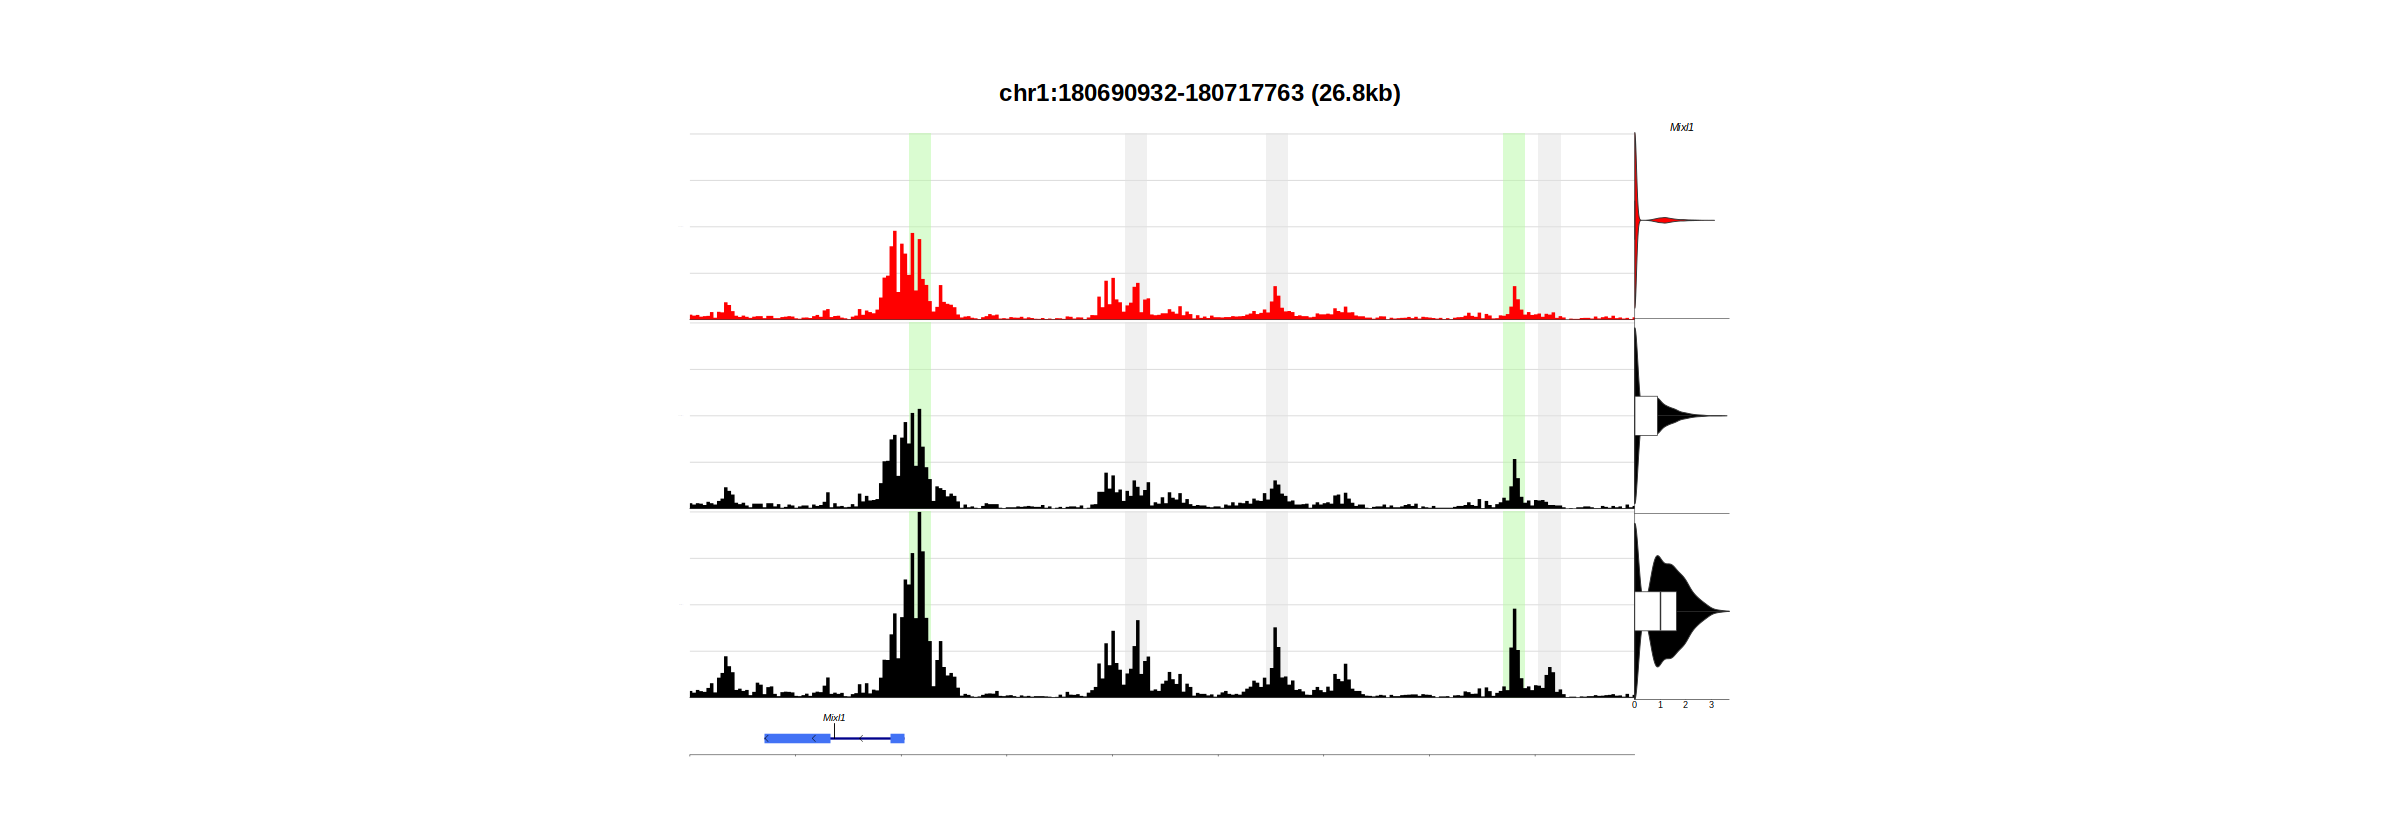

In [167]:
options(repr.plot.width = 20, repr.plot.height = 7)
plot_gene_bigwig('Mixl1', extend.upstream = -4.6e4, extend.downstream = -8.5e4)

In [180]:
plot_browser_track = function(gene = NULL, 
                              input_region = NULL, 
                              bigwigs, 
                              plot_expression = F,
                              sce = rna.sce,
                              extend.upstream = 0,
                              extend.downstream = 0, 
                              highlight_regions = NULL,
                              motif_regions = NULL, # <--- Added parameter
                              downsample.rate = 1, 
                              no_label = F, 
                              background_color = 'white',
                              highlight_color = 'grey95',
                              bw_height = 2, 
                              gene_height = 1.5, 
                              bw_width = 20,
                              expr_width = 4.5){
    
    
    # x-axis labels function 
    alternate_labels <- function(x) {
      ifelse(seq_along(x) %% 2 == 0, paste("\n", x), x)
    }
    
    if(!is.null(gene)){
        # Get region around gene
        region = ArchRProject@geneAnnotation$genes[grep(paste0('^', gene, '$'), ArchRProject@geneAnnotation$genes$symbol)]
        start(ranges(region)) = start(ranges(region)) - extend.upstream
        end(ranges(region)) = end(ranges(region)) + extend.downstream
        gr <- GRanges(c(seqnames(region)), IRanges(start=start(ranges(region)), end=end(ranges(region))), strand='+')
    }
    if(!is.null(input_region)){
        # Get supplied region as Granges
        gr <- GRanges(c(str_split(input_region, ':') %>% map_chr(1)), 
                      IRanges(start=as.numeric(str_split(str_split(input_region, ':') %>% map_chr(2), '-') %>% map_chr(1)) - extend.upstream, 
                              end=as.numeric(str_split(str_split(input_region, ':') %>% map_chr(2), '-') %>% map_chr(2)) + extend.downstream), 
                        strand='+')
    }
    
    # Get bigwig info
    bw_list = lapply(bigwigs$path, function(x)return(x))
    names(bw_list) = bigwigs$name
    bigwigs.colors = bigwigs$color
    names(bigwigs.colors) = bigwigs$name
                     
    coverages = mclapply(names(bw_list), function(x){
        region_data <- as.data.table(rtracklayer::import(con = bw_list[[x]], 
                    which = gr))
        region_data = rbind(region_data, region_data %>% copy() %>% .[,start:=end]) %>% 
            .[order(start)] %>% 
            .[,c('start', 'score')] %>% 
            .[, bw := names(bw_list[x])]
            # .[, bw := factor(names(bw_list[x]), levels = names(bw_list[x]))] 
        return(region_data)
    }, mc.cores = max(1,detectCores()-2)) %>% rbindlist() %>%
        .[, bw := factor(bw, levels = names(bw_list))] %>% .[order(bw)]
                     
    if(downsample.rate != 1){
        coverages = coverages[start %in% sample(start, nrow(coverages)*downsample.rate)]
    }
                     
    p1 =  ggplot(data = coverages, mapping = aes_string(x = "start", y = "score", fill = "bw")) + 
                     geom_area(color = 'black', linewidth = 0) + 
                     # geom_area() +
                     facet_wrap(facets = ~factor(bw, levels = names(bw_list)), 
                            strip.position = "left", ncol = 1) +
        # ggtitle(label = paste0(seqnames(gr)),
        #     subtitle = paste0(ranges(gr))) + #, ':', ranges(gr))) + 
        geom_hline(yintercept = 0, color='black', linewidth = 0.1) +
        geom_segment(data = as.data.table(gr)[,bw:=bigwigs[1,name]], # Add background segment to make sure x-axis is correct
            mapping = aes(x = start, y = 0, xend = end, yend = 0), color = 'white', alpha=0) +
        scale_x_continuous(expand=c(0,0)) + 
        scale_y_continuous(expand=c(0,0.005), breaks = seq(min(coverages$score), max(coverages$score), length.out = 5)) +
        Signac::theme_browser(axis.text.y = TRUE) + 
        theme(axis.text.y = element_blank(),
                panel.grid.minor = element_blank(),
              panel.grid.major.y =  element_line(color = "grey85", linewidth = 0.2),
              panel.grid.major.x = element_blank(),
                strip.text.y = element_text(hjust=1, color='black', size = 6, vjust=0.5),
                axis.line = element_blank(),
                axis.line.x = element_blank(),
                axis.text.x = element_blank(),
                axis.ticks = element_blank(), 
                axis.title = element_blank(),
                legend.position = 'none',
                plot.title = element_text(size = 7, hjust=0.5, vjust = -0.5, face='plain'),
                plot.subtitle = element_text(size = 5, hjust=0.5, face='plain'),
                panel.background = element_rect(fill=background_color),
                panel.spacing = unit(0, "lines"),
                plot.margin = margin(0,0,0,0)) 
    
    # Remove y-text if needed
    if(no_label){
        p1 = p1 + theme(strip.text.y = element_text(size = 0), 
                        strip.background = element_blank(),
                        plot.margin = unit(c(0,0,0,0), units = "lines")) 
    }
                     
    
# Add Highlights
    if(!is.null(highlight_regions)){
        # Keep only highlights in the display range
        highlights = GRanges(c(str_split(highlight_regions, ':') %>% map_chr(1)), 
                      IRanges(start=as.numeric(str_split(str_split(highlight_regions, ':') %>% map_chr(2), '-') %>% map_chr(1)), 
                              end=as.numeric(str_split(str_split(highlight_regions, ':') %>% map_chr(2), '-') %>% map_chr(2))), 
                        strand='+')
        
        highlight_in_region = findOverlaps(highlights, gr, ignore.strand = T, type = 'within')
        highlight_regions = highlight_regions[queryHits(highlight_in_region)]
        
        # Add highlight display
        if(length(highlight_regions) > 0){ # Only if there is any overlap
            highlights.dt = data.table(start = as.numeric(str_split(str_split(highlight_regions, ':') %>% map_chr(2), '-') %>% map_chr(1)),
                                       end = as.numeric(str_split(str_split(highlight_regions, ':') %>% map_chr(2), '-') %>% map_chr(2))) %>% 
                            .[, .(start, end, vector_column = rep(unique(p1$data$bw), each = 1)), by = .(row_index = 1:nrow(.))] %>% 
                            .[, position := start] %>% .[,score := 0]
            
            if(length(highlight_color) == 1){
                highlight_color = rep(highlight_color, length(highlight_regions))
                names(highlight_color) = as.character(unique(highlights.dt$start))
            }
            
            colors = c(bigwigs$color, as.character(highlight_color))
            names(colors) = c(as.character(bigwigs$name), names(highlight_color))

            p1 = p1 + 
                geom_rect(data = highlights.dt, aes(xmin=start, xmax=end, ymin=0, ymax=max(p1$data$score), fill = as.character(start)), 
                                    color=NA, alpha=0.2) +
                scale_fill_manual(values = colors) 
            # Change layers around so highlight is behind bigwig
            p1$layers = list(p1$layers[[3]], p1$layers[[4]], p1$layers[[1]], p1$layer[[2]])
        }
    }else{ p1 = p1 + scale_fill_manual(values = bigwigs.colors)}
                     
    # --- Add Motif Asterisks to Top of Top BigWig Track ---
    if(!is.null(motif_regions)){
      if(inherits(motif_regions, "GRanges")){
        motif_gr <- motif_regions
      } else {
        motif_gr <- GRanges(c(str_split(motif_regions, ':') %>% map_chr(1)), 
                            IRanges(start=as.numeric(str_split(str_split(motif_regions, ':') %>% map_chr(2), '-') %>% map_chr(1)), 
                                    end=as.numeric(str_split(str_split(motif_regions, ':') %>% map_chr(2), '-') %>% map_chr(2))))
      }
      
      # Keep motifs within current display window
      motif_hits <- findOverlaps(motif_gr, gr, ignore.strand = TRUE)
      if(length(motif_hits) > 0){
        motif_in_window <- motif_gr[queryHits(motif_hits)]
        
        # Build coordinate table targeting the FIRST (top) track panel
        motif_dt <- data.table(
          x = (start(motif_in_window) + end(motif_in_window)) / 2,
          bw = factor(names(bw_list)[1], levels = names(bw_list)), # Pin to top track
          y = Inf # Pushes text to the maximum y-axis bound of that facet
        )
        
        # Overlay asterisks at the top edge
        p1 <- p1 + 
          geom_text(data = motif_dt, 
                    aes(x = x, y = y, label = "*"), 
                    color = "blue", 
                    size = 12, 
                    vjust = 1.2, # Pulls asterisk down slightly into view from the y=Inf ceiling
                    inherit.aes = FALSE)
      }
    }
    # Get genome annotation
    annotation.genes = ArchRProject@geneAnnotation$genes 
    annotation.genes = annotation.genes[grep("^Rik|Rik$|^Gm|^Mir", annotation.genes$symbol, invert=T)] # remove uninformative genes from plotting
 
    annotation.exons = ArchRProject@geneAnnotation$exons
    annotation.exons = annotation.exons[grep("^Rik|Rik$|^Gm|^Mir", annotation.exons$symbol, invert=T)]
    
    # Search for genes within region
    tmp1 = findOverlaps(gr, annotation.genes, ignore.strand = T)
    tmp2 = findOverlaps(gr, annotation.exons, ignore.strand = T)
    
    # Add gene track if there are any genes in the window
    if(length(subjectHits(tmp1)) > 0){
        # get overlap among genes
        overlap = as.data.table(findOverlaps(annotation.genes[subjectHits(tmp1)], annotation.genes[subjectHits(tmp1)], type = 'any', ignore.strand = T))

        # check if genes overlap, and if so move different rows
        solver = list()
        for(x in unique(overlap$queryHits)){
            overlaps = overlap[queryHits==x & subjectHits <= x]
            nr_overlaps = nrow(overlaps)
        # No overlap --> Row = 0
            if(nr_overlaps == 1){
                rows = 1
        # 1 overlap --> check which row it was on
            }else{
               rows = setdiff(1:10, rbindlist(solver[overlaps$subjectHits])$row)[1]
            }
        #If overlap is after, do nothing
            solver[[x]] = data.table(queryHits = x,
                                     row = rows)
        }
        solved = rbindlist(solver)

        # keep overlapping genes/exons
        tmp1 = as.data.table(annotation.genes[subjectHits(tmp1)]) %>% 
            .[,row := solved$row] %>% .[width>200] # remove super short genes

        tmp2 = as.data.table(annotation.exons[subjectHits(tmp2)]) %>% 
            merge(., tmp1[,c('symbol', 'row')], by='symbol') # Add rown information

        # Cutoff genes/exon if they fall outside of the range
        tmp1 = tmp1 %>% 
            .[, `:=`(start = ifelse(start <= start(ranges(gr)), start(ranges(gr)), start),
                     end = ifelse(end >= end(ranges(gr)), end(ranges(gr)), end))]

        tmp2 = tmp2 %>% 
            .[, `:=`(start = ifelse(start <= start(ranges(gr)), start(ranges(gr)), start),
                     end = ifelse(end >= end(ranges(gr)), end(ranges(gr)), end))] %>% unique()

        # Add Arrows to indicate orientation
        width = end(ranges(gr)) - start(ranges(gr))

        tmp3 = lapply(1:nrow(tmp1), function(x){
            tmp = tmp1[x,]
            tmpp = data.table(
                          start = seq(tmp$start + 20, tmp$end + 20, by = width/20),
                          end = seq(tmp$start + 40, tmp$end + 40, by = width/20),
                          symbol = tmp$symbol,
                          row = tmp$row)
            return(tmpp)
        }) %>% rbindlist()


        # Plot gene track 
        p = ggplot() + # rbind(tmp1, tmp1 %>% copy() %>% .[,row:=row+1]), aes(start, row)
            geom_segment(data = as.data.table(gr), # Add background segment to make sure x-axis is correct
                         mapping = aes(x = start, y = 1, xend = end, yend = 1), color = 'white') +
            geom_segment(data = tmp1, 
                mapping = aes(x = start, y = row, 
                xend = end, yend = row), color = 'darkblue', show.legend = FALSE, linewidth = unit(0.5, 'mm')) +
            geom_segment(data = tmp2, 
                mapping = aes(x = start, y = row, 
                xend = end, yend = row), color = '#4272f5', show.legend = FALSE, linewidth = unit(2, 'mm')) + 
        for(i in 1:nrow(tmp1)){
            tmp = tmp1[i,]
            if(as.character(tmp$strand) == '+'){
                p = p + geom_segment(data = tmp3[symbol == tmp$symbol], 
                        mapping = aes(x = start, y = row, 
                xend = end, yend = row), arrow = arrow(ends = "last", 
                        type = "open", angle = 45, length = unit(x = 1, 
                        units = "mm")), show.legend = FALSE, color='black', 
                        linewidth = 0.1)
               }else{
              p = p + geom_segment(data = tmp3[symbol == tmp$symbol], 
                        mapping = aes(x = start, y = row, 
                xend = end, yend = row), arrow = arrow(ends = "first", 
                        type = "open", angle = 45, length = unit(x = 1, 
                        units = "mm")), show.legend = FALSE, color='black', 
                        linewidth = 0.1)  
            }
        }


        p = p + 
            #xlim(start(ranges(gr)), end(ranges(gr))) + 
            ggrepel::geom_text_repel(data = tmp1, aes(label = symbol, x = end - (end - start)/2 , y = row), 
                                     fontface = "italic",
                                     size = 2,
                                     color = 'black', 
                                     direction = "y",
                                     force_pull   = 0, # do not pull toward data points
                                     nudge_y      = 1,
                                     segment.size = 0.2
                                    ) + 
            ylim(0.5, max(c(1, tmp1$row) + 1))

    }else{
        p = ggplot() + # rbind(tmp1, tmp1 %>% copy() %>% .[,row:=row+1]), aes(start, row)
            geom_segment(data = as.data.table(gr), # Add background segment to make sure x-axis is correct
                         mapping = aes(x = start, y = 1, xend = end, yend = 1), color = 'white') +
            ylim(0.5, 2)
        
        
        
    }
    p = p + 
        scale_x_continuous(expand = c(0,0), labels = alternate_labels, breaks = seq(start(ranges(gr)), end(ranges(gr)), 3000)) + # breaks = scales::pretty_breaks(n = 1))
        theme_void() + 
        theme( #axis.text.x = element_text(size=15, color='black', vjust=0.9),
               axis.ticks.x = element_line(color='black', linewidth=0.1), 
               axis.ticks.length.x = unit(0.3, 'mm'),
               axis.line.x = element_line(color='black', linewidth=0.1),
               plot.margin = margin(0,0,0,0) 
    )
    
    if(plot_expression == F){
        patchwork::wrap_plots(plotlist = list(p1, p), ncol = 1, heights = unit(c(nrow(bigwigs)*bw_height, gene_height), c('mm', 'mm')))
    }else{
        stopifnot(!is.null(gene))
        meta.plot = as.data.table(colData(sce)) %>% 
            .[,gene := as.vector(logcounts(sce[gene,]))] %>% 
            merge(., bigwigs, by = c('celltype')) %>% 
            .[,c('genotype', 'celltype', 'name', 'color', 'gene')]

        p2 = ggplot(meta.plot %>% copy(),
                        # .[,celltype_v2 := factor(celltype_v2, levels = rev(WT_plot$name))], 
                    aes(gene, name, fill = name)) + 
            geom_violin(scale = 'width',  size = 0.2) + 
            geom_boxplot(width=0.2, fill='white', linewidth = 0.15, outlier.shape=NA) + 
            scale_fill_manual(values = bigwigs.colors) + 
            scale_x_continuous(expand = c(0, 0)) + 
            scale_y_discrete(expand = c(0, 0), limits = rev(names(bw_list))) + 
            geom_hline(yintercept = seq(0.5, nrow(WT_plot), 1), linewidth = 0.1) + 
            ggtitle(gene) + 
            theme_void() + 
            theme(axis.text.x = element_text(size = 5, vjust = 0),
                  axis.line = element_line(linewidth = 0.1),
                  axis.ticks.x = element_line(linewidth=0.1, color = 'black'),
                  plot.title = element_text(size = 6, hjust=0.5, face = "italic"),
                  plot.subtitle = element_text(size = 7, hjust=0.5, face='plain'),
                  panel.background = element_rect(fill = background_color, color = NA),
                  plot.margin = margin(0,0,0,0),
                  legend.position = 'none')

        patchwork::wrap_plots(
          p1, p2, p, 
          ncol = 2, 
          widths = unit(c(bw_width, expr_width), c('mm', 'mm')), 
          heights = unit(c(nrow(bigwigs) * bw_height, gene_height), c('mm', 'mm'))
        ) + 
        patchwork::plot_annotation(
          title = paste0(seqnames(gr), ':', ranges(gr), ' (', round(width(gr)/1000, 1), 'kb)'),
          theme = ggplot2::theme(plot.title = ggplot2::element_text(size = 14, face = "bold", hjust = 0.5))
        )
    }
}

In [181]:
plot_gene_bigwig = function(gene_in, extend.upstream = 1e3, extend.downstream = 1e3){
    DARs = comparison
    peaks = links[gene %in% gene_in & peak %in% DARs[sign != 'nonsig']$gene,] %>%
        merge(., DARs, by.x = 'peak', by.y = 'gene')
    region = paste0(peaks$chr[1], ':', min(c(peaks$start, peaks$gene_strt)) - extend.downstream, '-', max(peaks$end, peaks$gene_end) + extend.upstream)

    highlight_colors = ifelse(peaks$sign == 'both', "#b8fca4", 
                              ifelse(peaks$sign == 'WT_KD', "#80fff9",
                                    'grey90'))
    names(highlight_colors) = str_split(str_split(peaks[, peak], ':') %>% map_chr(2), '-') %>% map_chr(1)
    
    # --- Extract EOMES motif positive peaks ---
    # Retrieve matrix column corresponding to EOMES
    eomes_mat <- matches[, grep('EOMES', colnames(matches))]@assays@data$matches
    
    # Get peaks with at least 1 motif hit
    if (is(eomes_mat, "sparseMatrix") || is.matrix(eomes_mat)) {
      eomes_positive_peaks <- rownames(eomes_mat)[which(rowSums(eomes_mat) > 0)]
    } else {
      eomes_positive_peaks <- names(eomes_mat)[which(eomes_mat > 0)]
    }
    
    # Filter for peaks within the current plot window/peaks table
    eomes_in_region <- intersect(peaks$peak, eomes_positive_peaks)

    p1 = plot_browser_track(gene = gene_in,
                              input_region = region, 
                              WT_plot, 
                              plot_expression = T,
                              sce = rna.sce_filt,
                              extend.upstream = 0,
                              extend.downstream = 0, 
                              highlight_regions = peaks$peak,
                              motif_regions = eomes_in_region, # <--- Pass motif peaks here
                              downsample.rate = 1, 
                              no_label = T, 
                              background_color = 'white',
                              highlight_color = highlight_colors,
                              bw_height = 40, 
                              gene_height = 10, 
                              bw_width = 200,
                              expr_width = 20)
    return(p1)
}

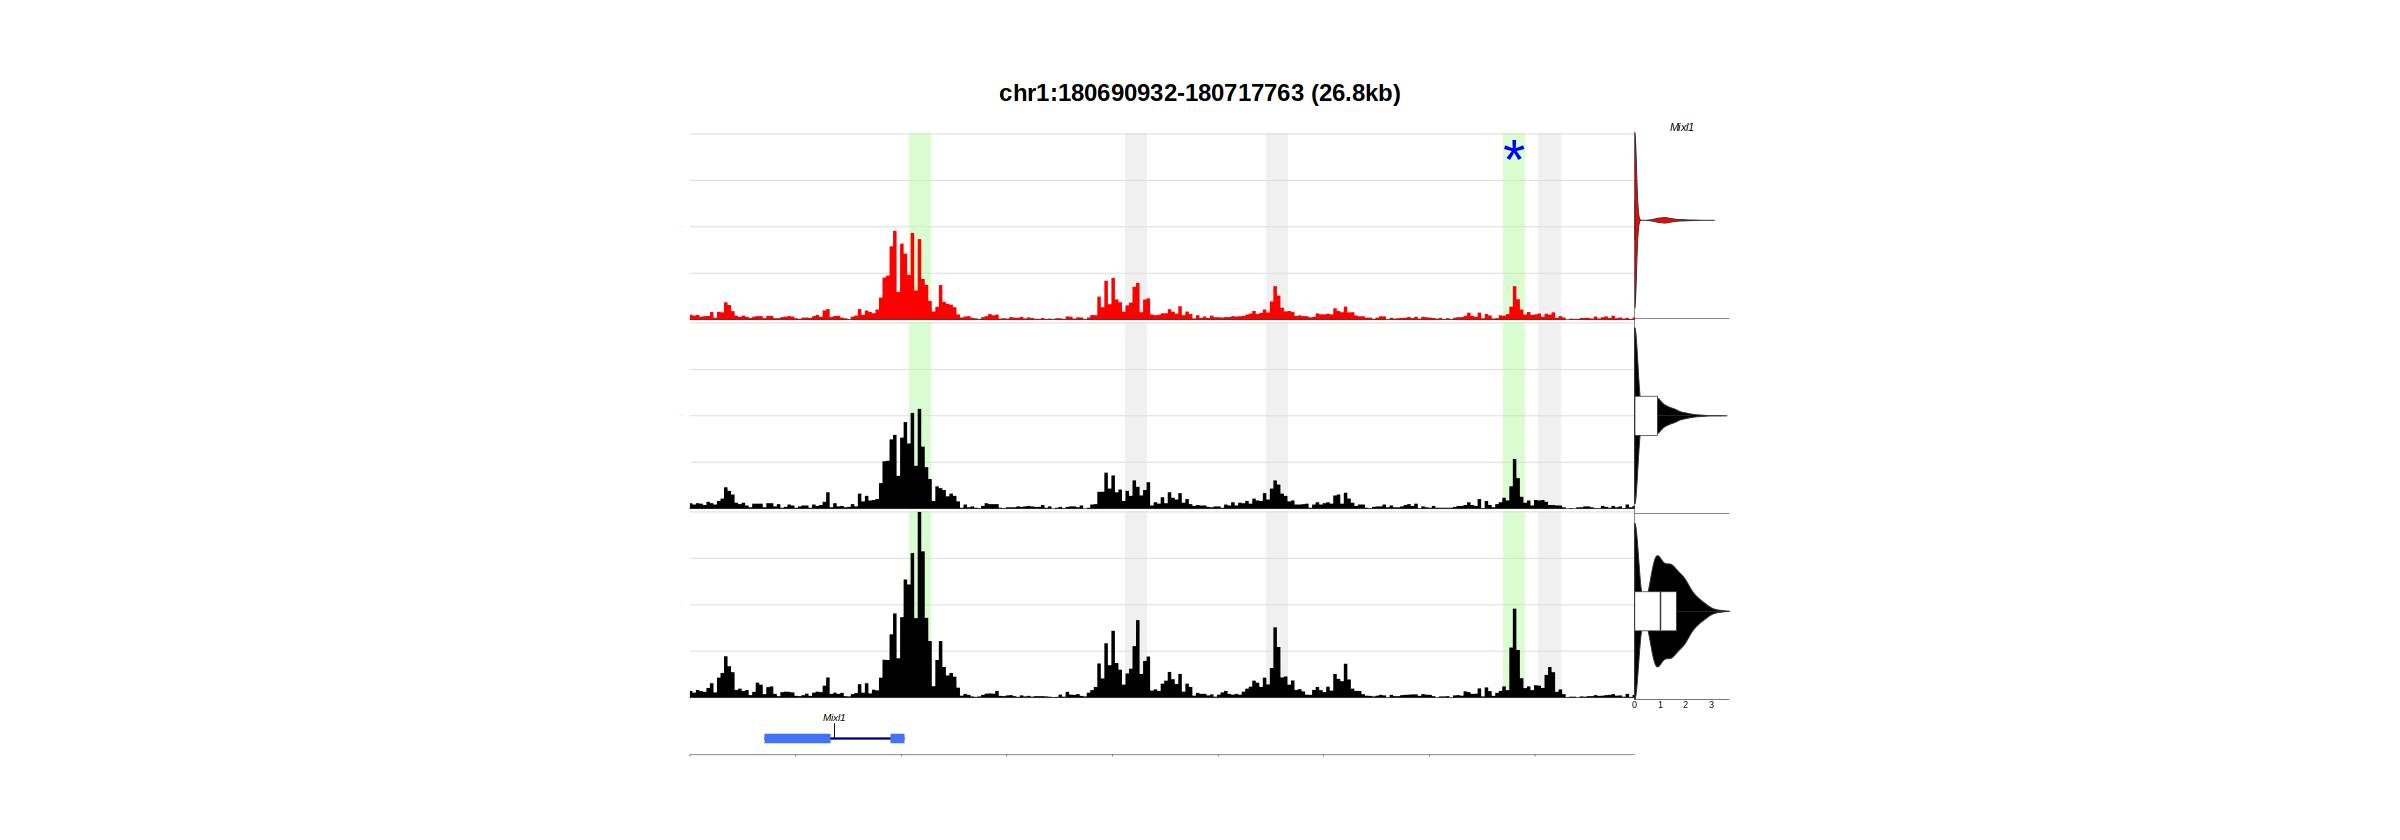

In [182]:
plot_gene_bigwig('Mixl1', extend.upstream = -4.6e4, extend.downstream = -8.5e4)

In [183]:
gene_list <- c(
  "Foxa2", "Adamts9", "Sox17", "Gsc", "Lhx1", "Chrd", "Mixl1", 
  "Noto", "Shh", "Fgf8", "T", "Eomes", "Dkk1", "Lefty1", 
  "Foxj1", "Cxcr4", "Snai1"
)

pdf(file.path(args$outdir, "browser_tracks.pdf"), width = 15, height = 6)
invisible(lapply(gene_list, function(g) print(plot_gene_bigwig(g))))
dev.off()

png 
  2